In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import the data
* Import data that describe countries in one point

In [4]:
one_point_countries_win = pd.read_parquet('../data/by_country/one_point_countries_winsorized.parquet')

In [5]:
one_point_countries_win.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,...,0.907532,0.896973,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,...,0.800186,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,...,0.423795,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149
3,Brazil,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.672829,4.675629,1.646041,...,-1.172808,-1.123510,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.714821,-0.915149
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.582413,4.585987,1.688591,...,-1.172808,-1.109812,0.138675,-1.000910,-1.172995,-1.023467,-0.268474,-0.822060,0.057350,-0.412401


### Search outliers
* Look for outliers
* Plot boxplot for every feature

In [8]:
def detect_top_outliers(df, top_n=5):
    # Select only numerical columns
    numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns

    outlier_counts = {}

    # Count outliers per column using IQR method
    for col in numeric_columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
        outlier_counts[col] = outliers.shape[0]

    # Sort columns by number of outliers (descending)
    sorted_outliers = dict(sorted(outlier_counts.items(), key=lambda item: item[1], reverse=True))

    print("Number of outliers per column (sorted):\n")
    for col, count in sorted_outliers.items():
        print(f"{col}: {count}")

    # Plot boxplots for top N columns with most outliers
    top_columns = list(sorted_outliers.keys())[:top_n]

    plt.figure(figsize=(15, top_n * 2))
    for i, col in enumerate(top_columns, 1):
        plt.subplot(top_n, 1, i)
        sns.boxplot(x=df[col], color='salmon')
        plt.title(f'Boxplot of {col}', fontsize=11)
        plt.tight_layout()

    plt.show()

Number of outliers per column (sorted):

labor_force_mean: 0
labor_force_median: 0
labor_force_std: 0
labor_force_min: 0
labor_force_max: 0
labor_force_last: 0
livestock_prod_mean: 0
livestock_prod_median: 0
livestock_prod_std: 0
livestock_prod_cv: 0
livestock_prod_min: 0
livestock_prod_max: 0
livestock_prod_last: 0
urban_pop_mean: 0
urban_pop_median: 0
urban_pop_min: 0
urban_pop_max: 0
urban_pop_last: 0
gov_exp_mean: 0
gov_exp_median: 0
gov_exp_std: 0
gov_exp_cv: 0
gov_exp_min: 0
gov_exp_max: 0
gov_exp_last: 0
gov_exp_growth: 0
gov_exp_trend: 0
reserves_mean: 0
reserves_median: 0
reserves_std: 0
reserves_cv: 0
reserves_min: 0
reserves_max: 0
reserves_last: 0
investment_mean: 0
investment_median: 0
investment_std: 0
investment_cv: 0
investment_min: 0
investment_max: 0
investment_last: 0
investment_growth: 0
investment_trend: 0
cpi_mean: 0
cpi_median: 0
cpi_std: 0
cpi_cv: 0
cpi_min: 0
cpi_max: 0
cpi_last: 0
gdp_mean: 0
gdp_median: 0
gdp_std: 0
gdp_cv: 0
gdp_min: 0
gdp_max: 0
gdp_last: 0

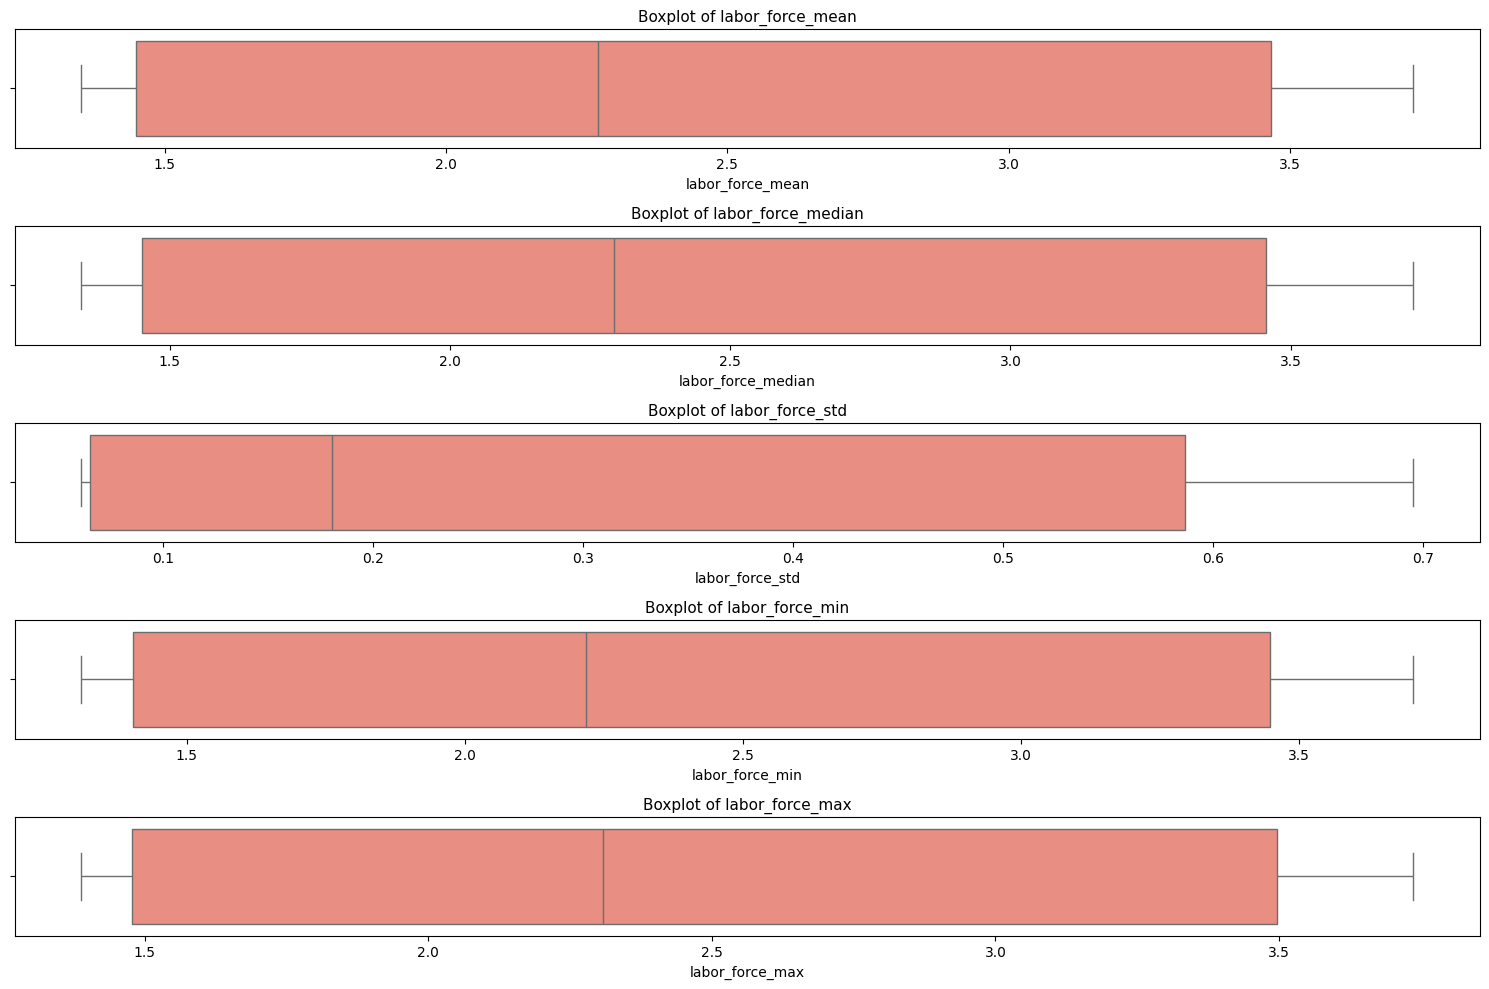

In [9]:
detect_top_outliers(one_point_countries_win)

### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [14]:
from sklearn.cluster import KMeans

In [16]:
cluster_input = one_point_countries_win.select_dtypes(include='number')
cluster_input.head()

,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,0.054347,...,0.907532,0.896973,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477
1,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,0.017337,...,0.800186,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887
2,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,0.017337,...,0.423795,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149
3,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.672829,4.675629,1.646041,0.038379,...,-1.172808,-1.123510,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.714821,-0.915149
4,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.582413,4.585987,1.688591,0.046573,...,-1.172808,-1.109812,0.138675,-1.000910,-1.172995,-1.023467,-0.268474,-0.822060,0.057350,-0.412401


#### Using the elbow method to find the optimal number of clusters

In [17]:
distortions = []

In [18]:
import time

In [19]:
# Parameters
n_init_list = [12, 15, 18, 20]
max_iter_list = [200, 300, 400, 500]
n_clusters_range = range(1, 11)
random_states = [0, 21, 42, 84, 101]

KMeans algorithm:
- n_clusters: Specifies the number of clusters to form. It directly determines the granularity of the grouping.
- init: Defines the method for initializing centroids. 'k-means++' is preferred for better convergence.
- n_init: Sets how many times the algorithm runs with different centroid seeds. Higher values improve robustness.
- max_iter: Limits the number of iterations per run. Controls convergence depth.
- tol: Sets the tolerance for declaring convergence. Affects when the algorithm stops based on centroid movement.
- random_state: Fixes the seed for reproducibility. Ensures consistent results across runs.
- algorithm: Chooses the internal algorithm variant ('lloyd' or 'elkan'). 'elkan' is faster for well-separated clusters.



Running elbow plots for random_state=0


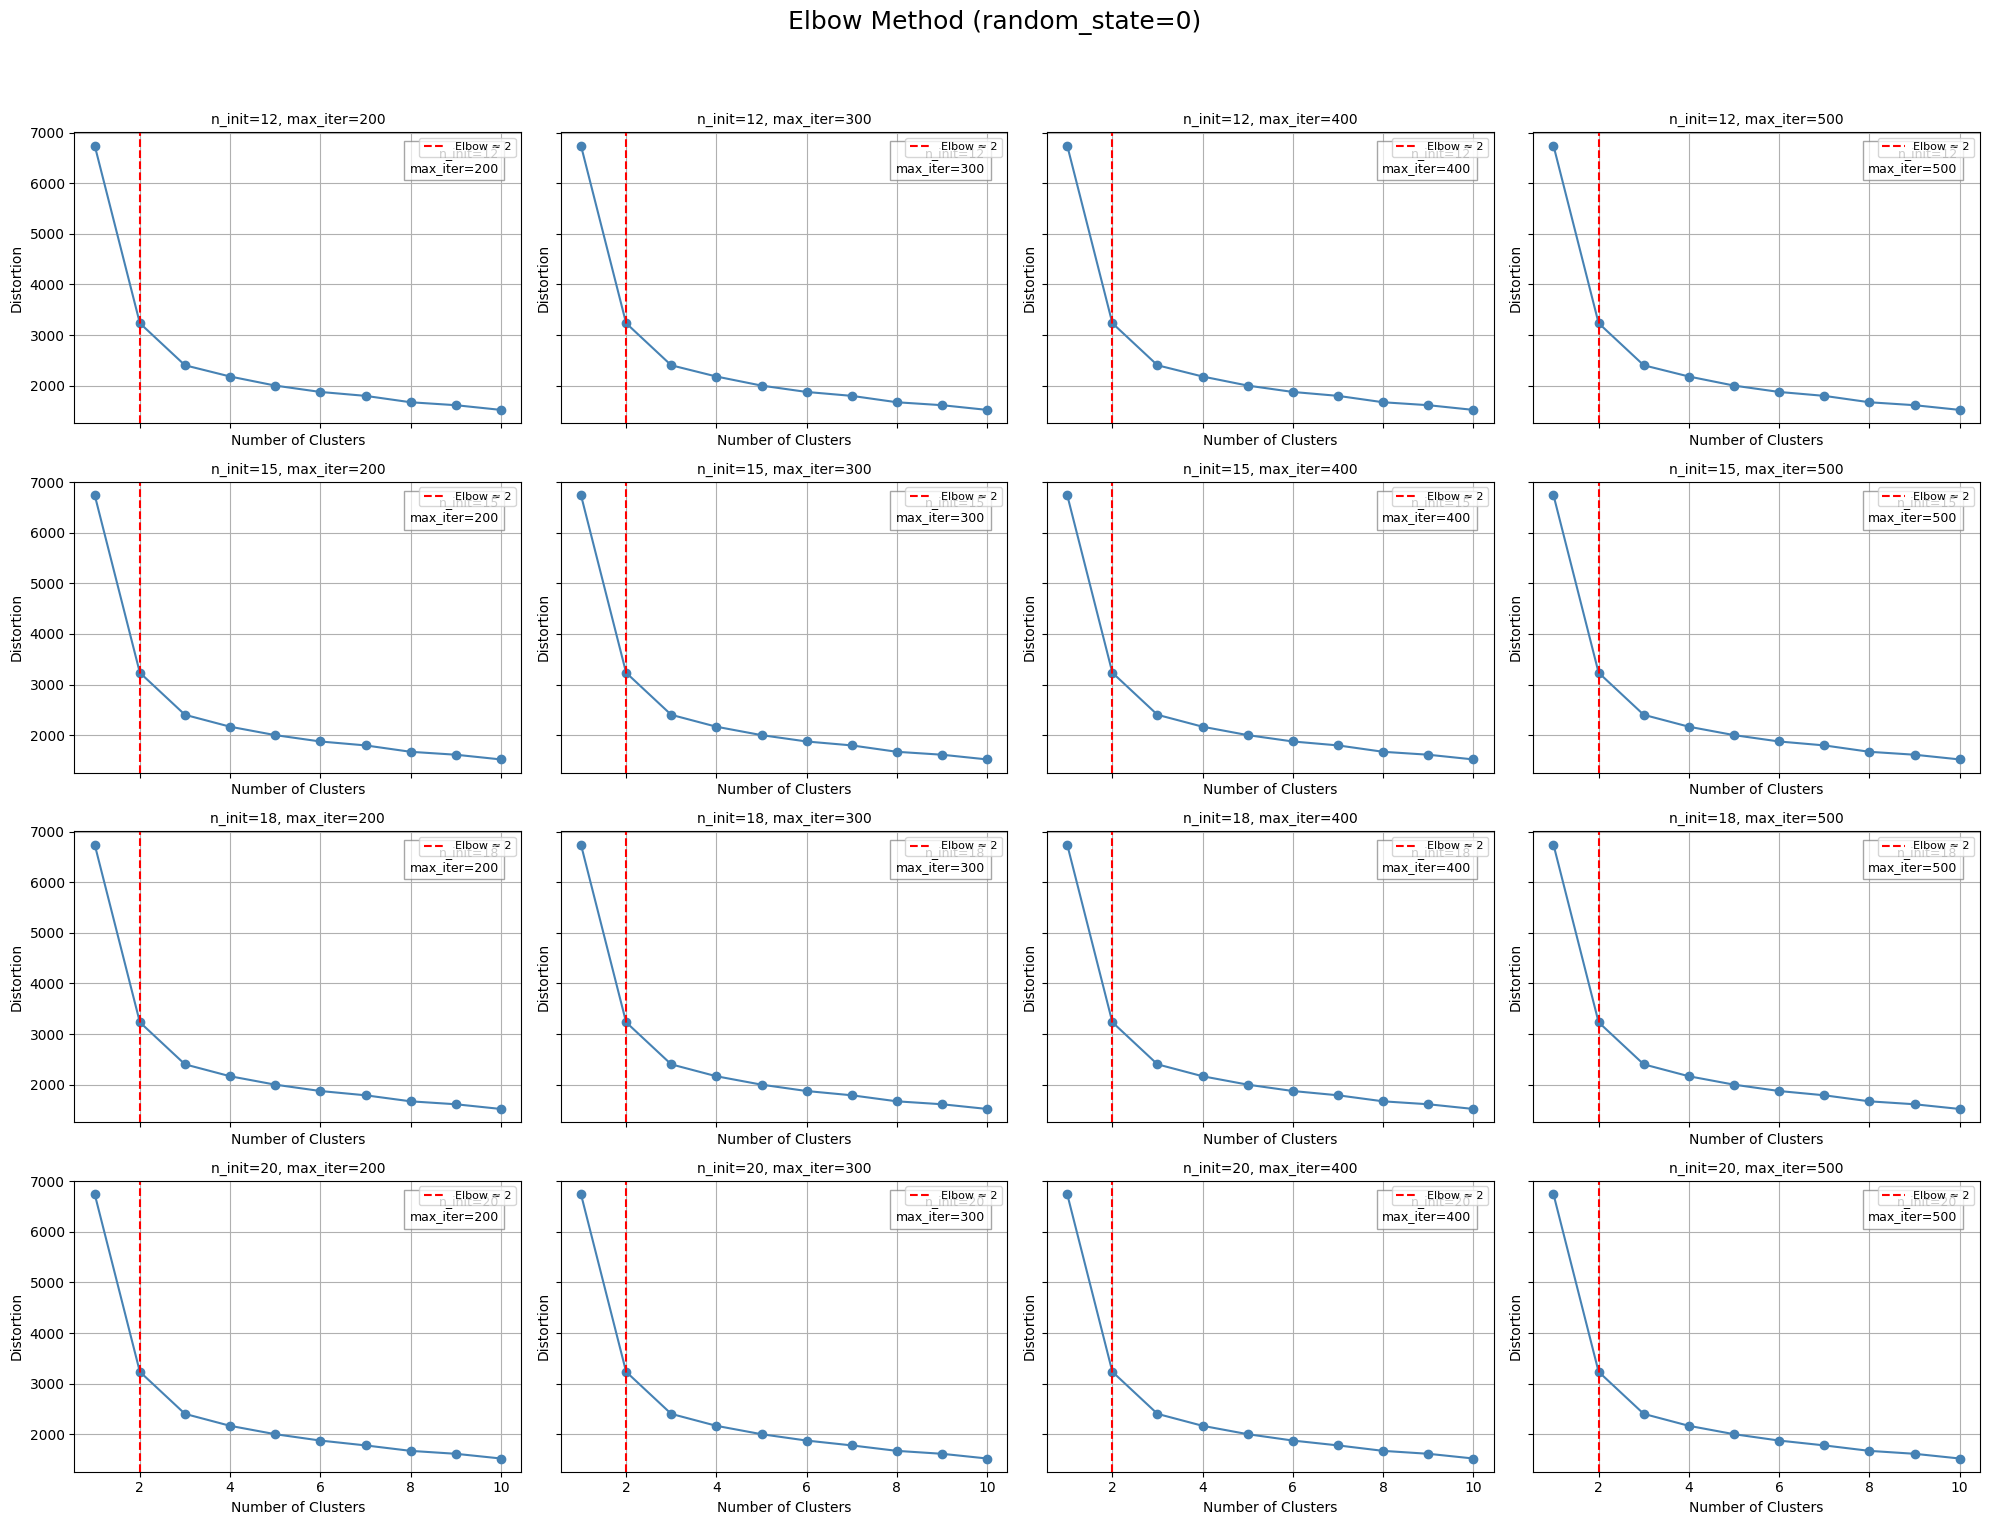


Running elbow plots for random_state=21


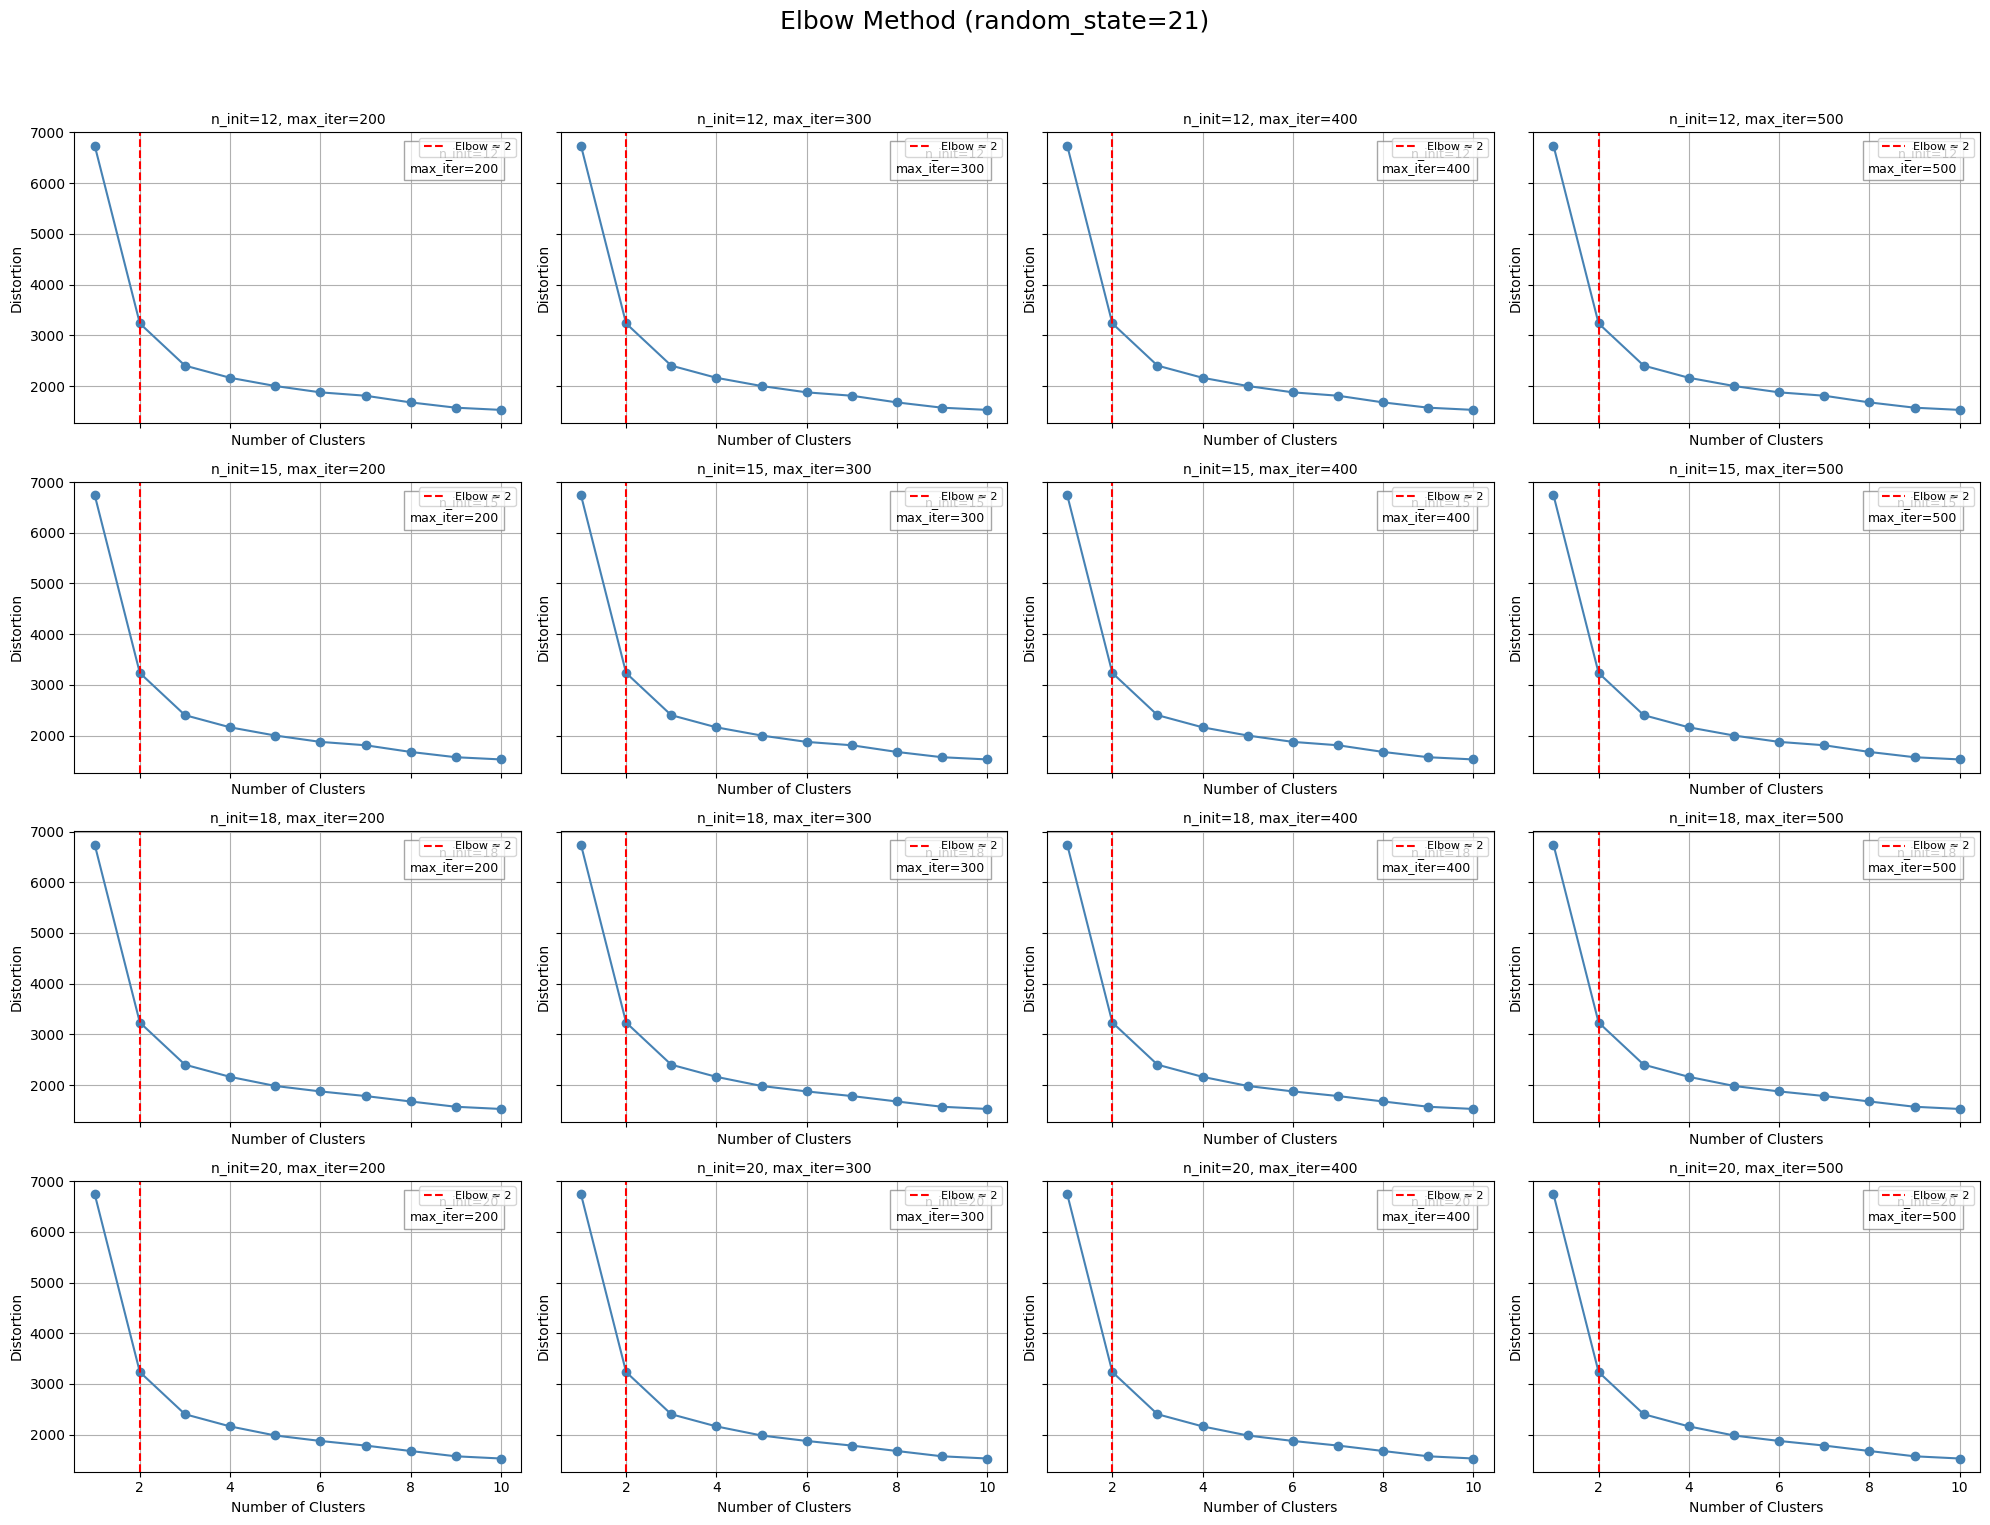


Running elbow plots for random_state=42


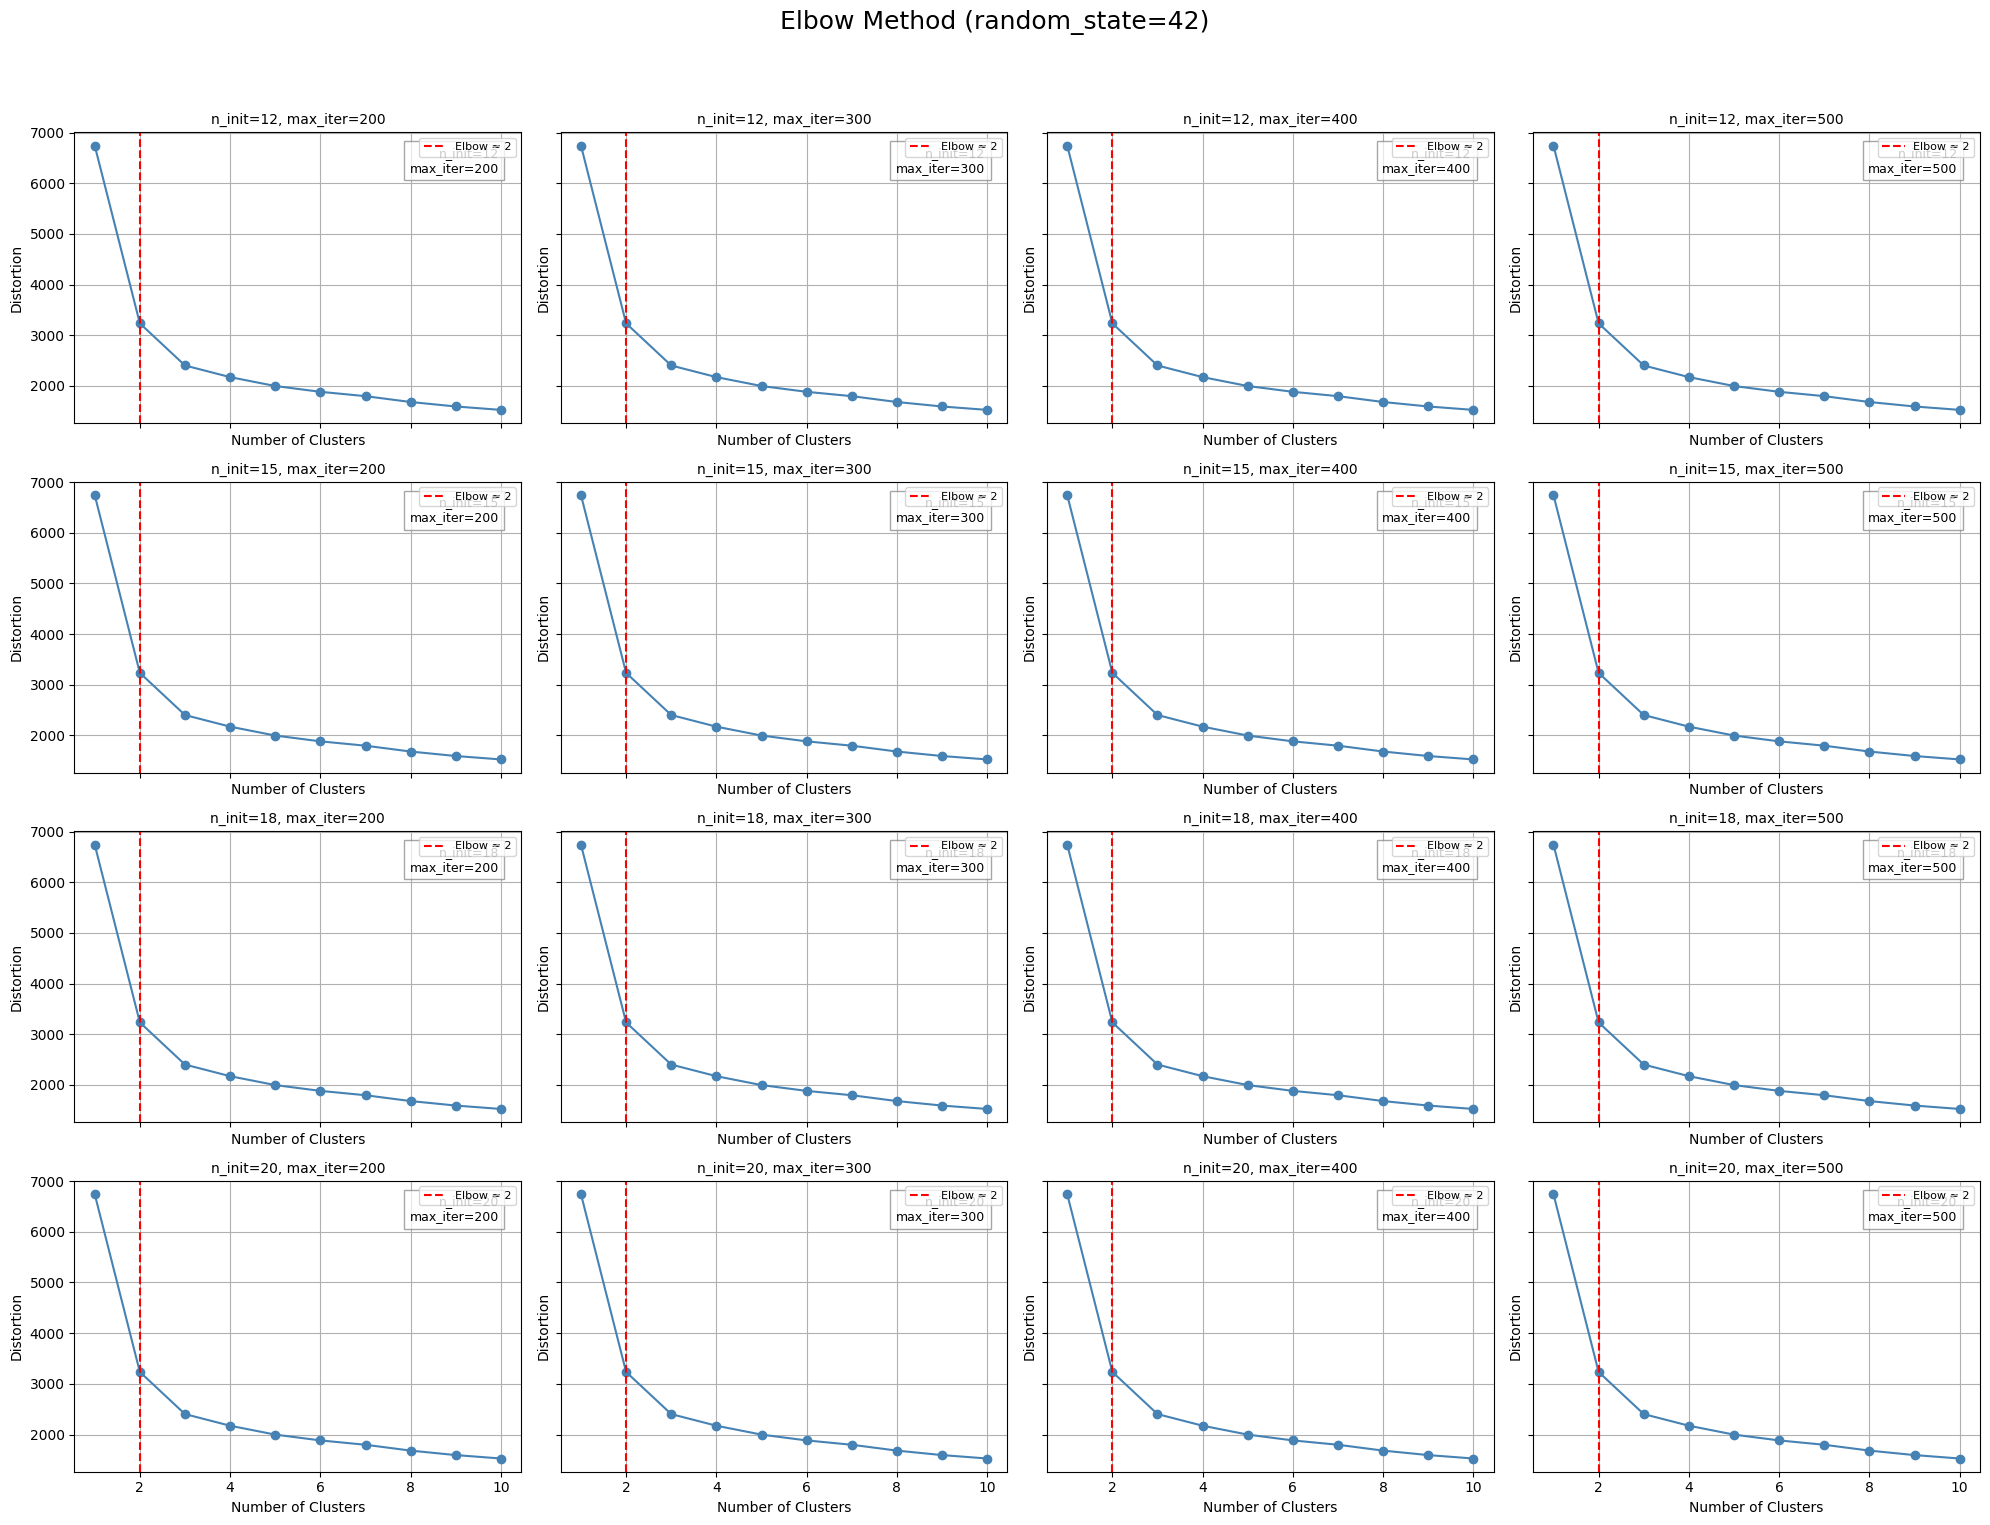


Running elbow plots for random_state=84


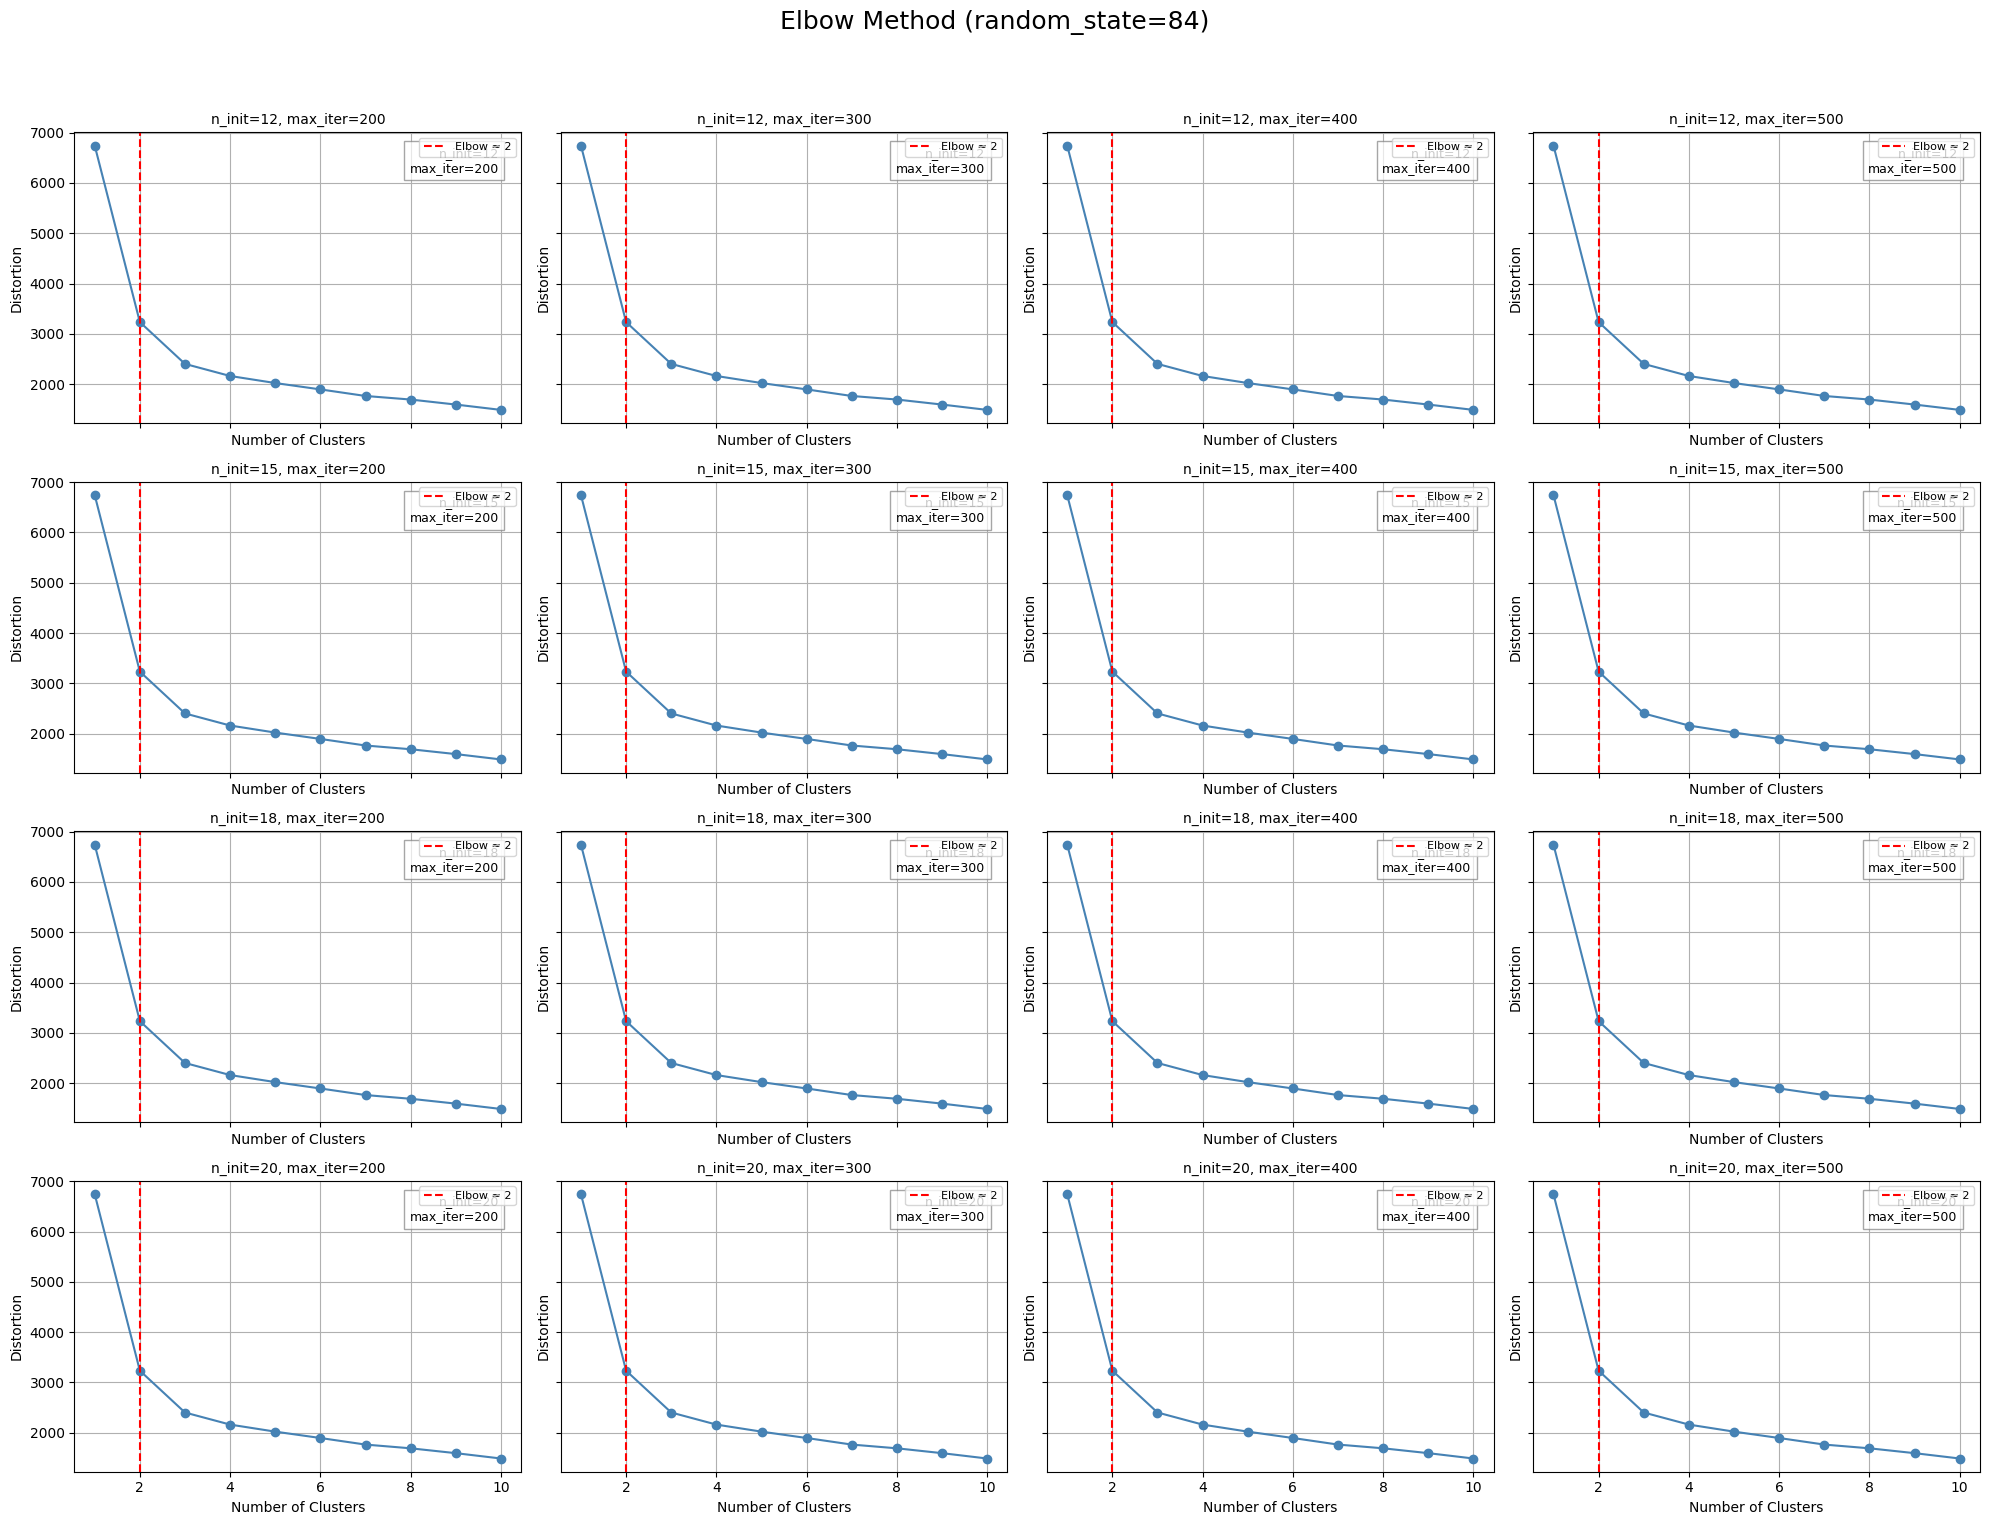


Running elbow plots for random_state=101


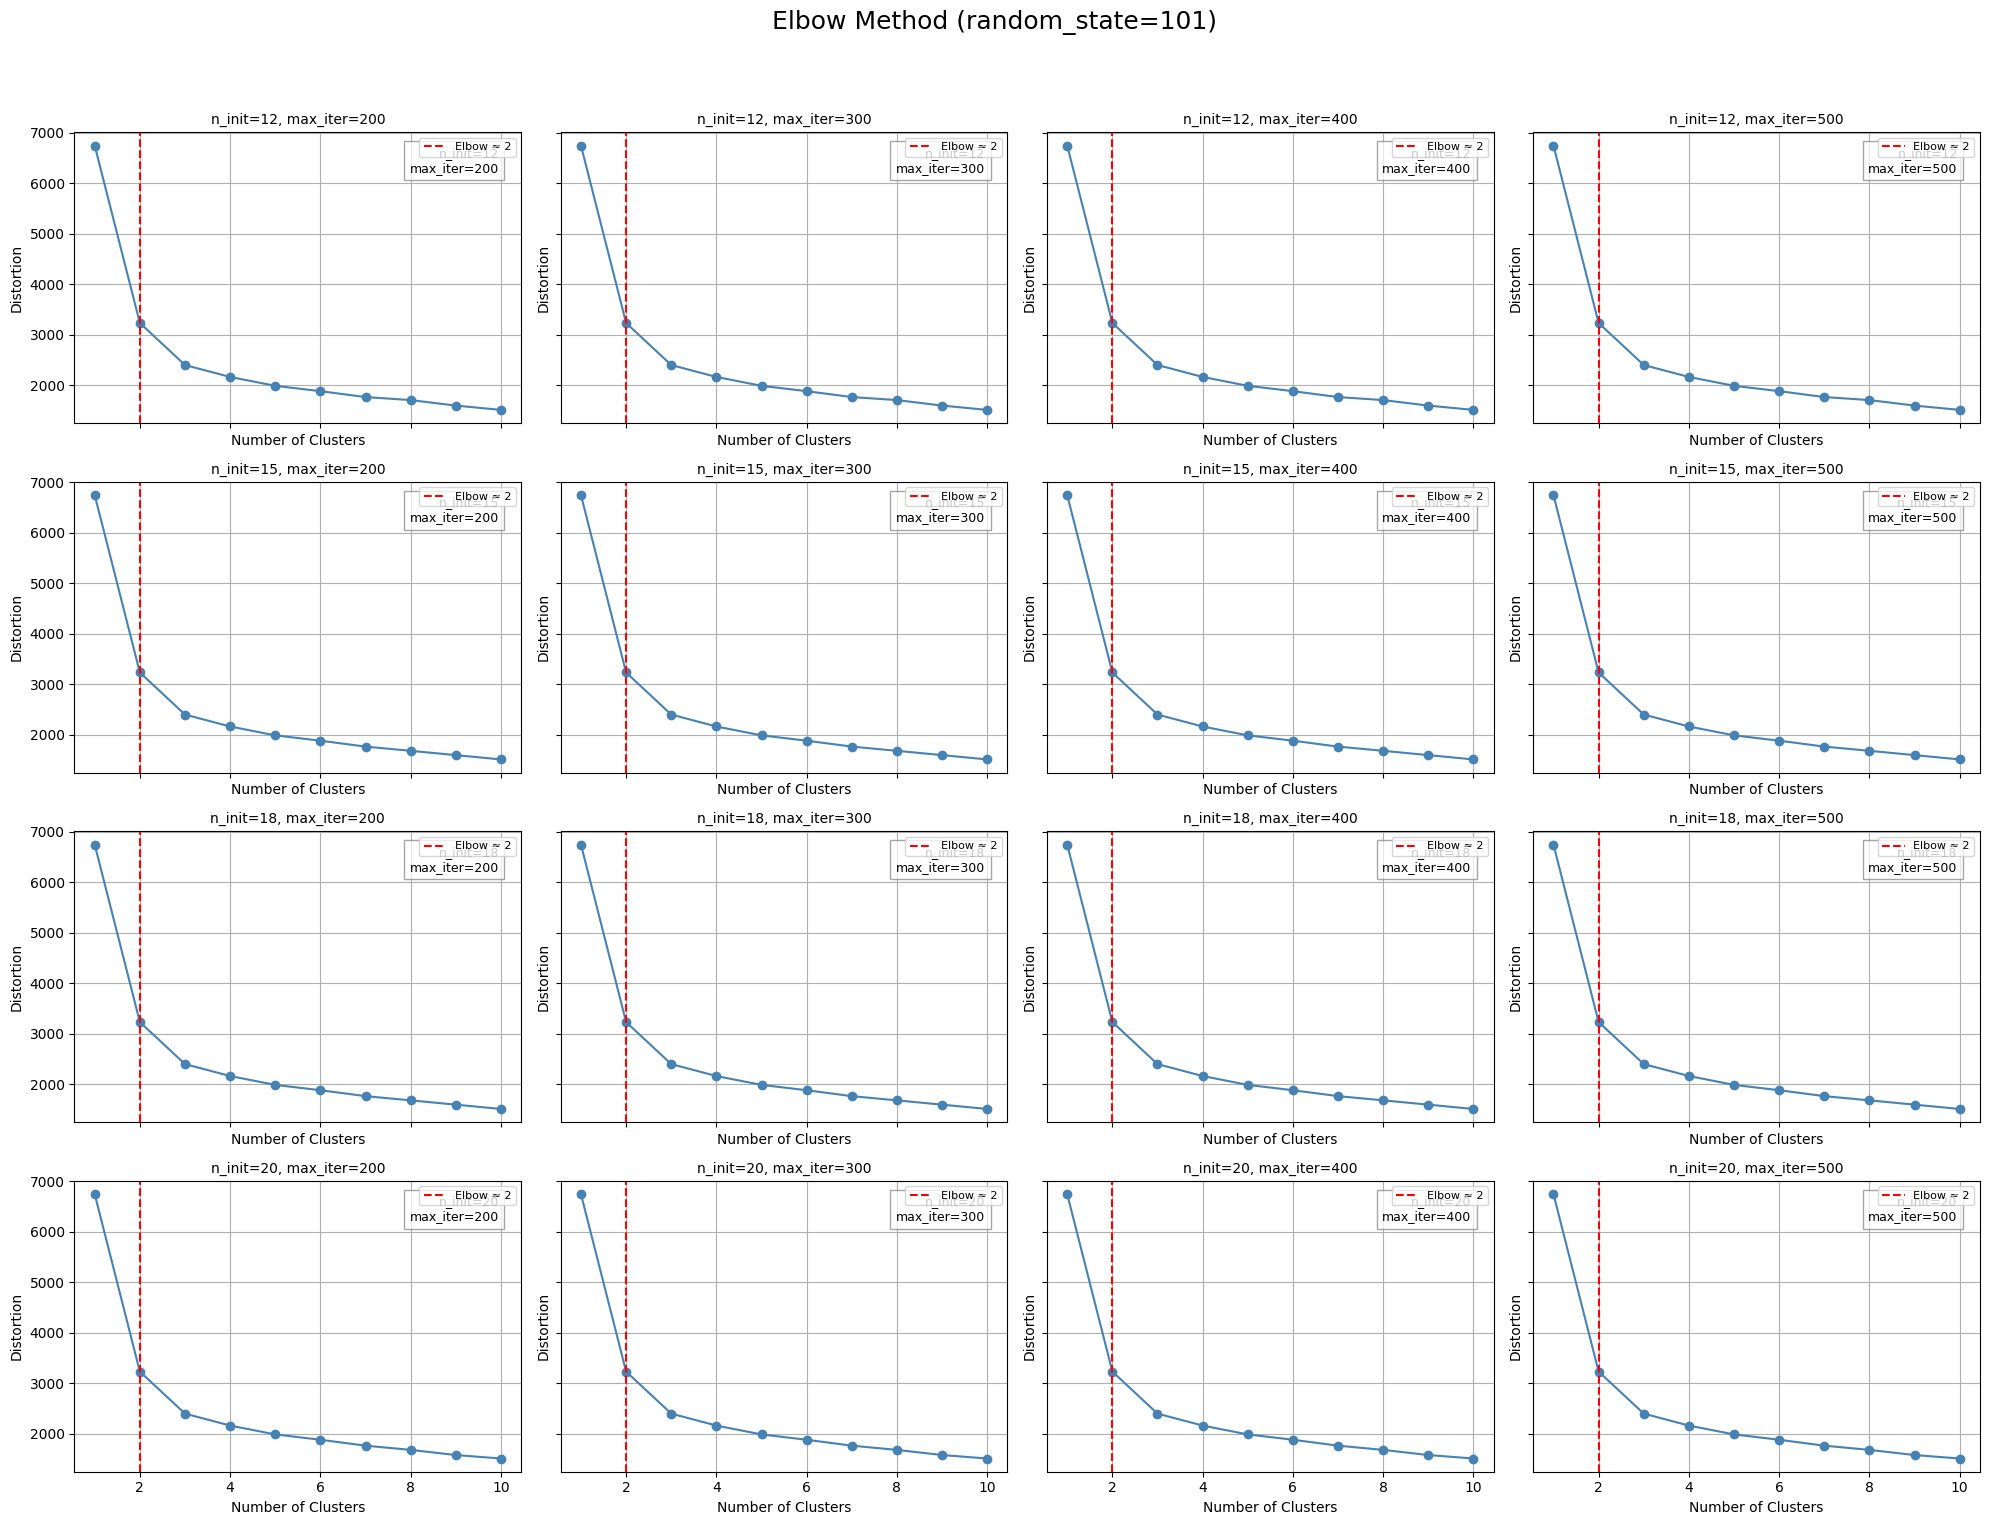


Total execution time: 48.96 seconds


In [21]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(cluster_input)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

* Compared to the last experiments where we did not take into account the outliers before creating the clusters, we see a significant decrease in the distortion. This could give indications that reducing the variables to represent the countries and running the clustering algorithm could reproduce better results.

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [22]:
from sklearn.metrics import silhouette_samples

In [23]:
from matplotlib import cm

In [24]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

In [25]:
km_c2_ni20_maxi500 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [26]:
ym_c2_ni20_maxi500 = km_c2_ni20_maxi500.fit(cluster_input)

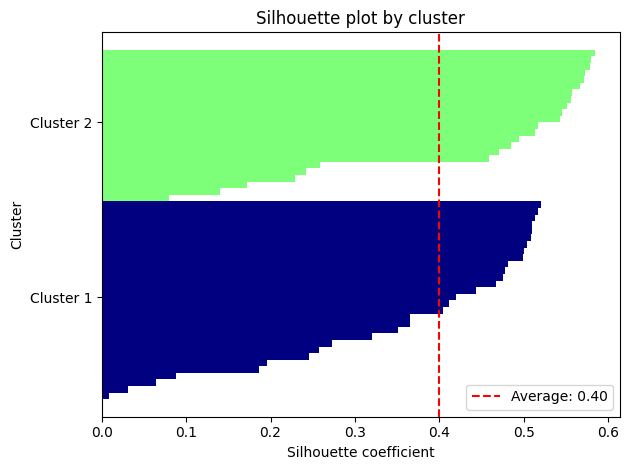

np.float64(0.3998025981275242)

In [27]:
plot_silhouette(ym_c2_ni20_maxi500, cluster_input)

In [28]:
km_c2_ni10_maxi100 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=10,
            max_iter=100,
            random_state=42)

In [29]:
ym_c2_ni10_maxi100 = km_c2_ni10_maxi100.fit(cluster_input)

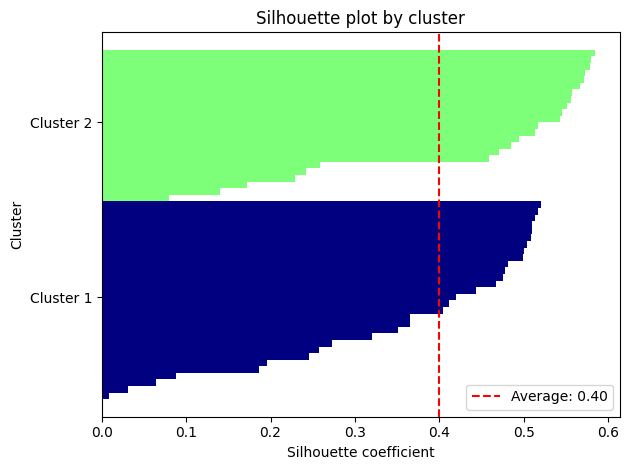

np.float64(0.3998025981275242)

In [30]:
plot_silhouette(ym_c2_ni10_maxi100, cluster_input)

1. Uniform height on the Y axis
- Each row represents a cluster.
- Height ≠ quality, but if all clusters have a similar number of samples, the bars should have similar heights.
- If you see a very thin cluster (low height), it may indicate that the group has too few elements → possible outlier or oversegmentation.

2. Length of the bars on the X-axis
- This does indicate quality: it is the Silhouette Coefficient of each point.
- Values ​​close to +1 → the point is correctly assigned to its cluster.
- Values ​​close to 0 → the point is on the border between clusters.
- Negative values ​​→ the point is probably incorrectly assigned.

In [31]:
one_point_countries_win.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,...,0.907532,0.896973,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,...,0.800186,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,...,0.423795,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149
3,Brazil,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.672829,4.675629,1.646041,...,-1.172808,-1.123510,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.714821,-0.915149
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.582413,4.585987,1.688591,...,-1.172808,-1.109812,0.138675,-1.000910,-1.172995,-1.023467,-0.268474,-0.822060,0.057350,-0.412401


In [32]:
final_c2_ni10_maxi100 = one_point_countries_win.copy()
final_c2_ni10_maxi100['cluster'] = ym_c2_ni10_maxi100.labels_
final_c2_ni10_maxi100.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,cluster
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,...,0.896973,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477,0
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,...,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887,1
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,...,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149,1
3,Brazil,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.672829,4.675629,1.646041,...,-1.123510,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.714821,-0.915149,0
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.582413,4.585987,1.688591,...,-1.109812,0.138675,-1.000910,-1.172995,-1.023467,-0.268474,-0.822060,0.057350,-0.412401,1


In [33]:
final_c2_ni20_maxi500 = one_point_countries_win.copy()
final_c2_ni20_maxi500['cluster'] = ym_c2_ni20_maxi500.labels_
final_c2_ni20_maxi500.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,cluster
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,...,0.896973,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477,0
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,...,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887,1
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,...,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149,1
3,Brazil,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.672829,4.675629,1.646041,...,-1.123510,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.714821,-0.915149,0
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.582413,4.585987,1.688591,...,-1.109812,0.138675,-1.000910,-1.172995,-1.023467,-0.268474,-0.822060,0.057350,-0.412401,1


In [34]:
import country_converter as coco

In [35]:
final_c2_ni10_maxi100['ISO_A3'] = coco.convert(names=final_c2_ni10_maxi100['Country'], to='ISO3')
final_c2_ni20_maxi500['ISO_A3'] = coco.convert(names=final_c2_ni20_maxi500['Country'], to='ISO3')

In [36]:
clusters_c2_ni10_maxi100 = final_c2_ni10_maxi100[['Country', 'ISO_A3', 'cluster']].copy()
clusters_c2_ni20_maxi500 = final_c2_ni20_maxi500[['Country', 'ISO_A3', 'cluster']].copy()

In [37]:
clusters_c2_ni10_maxi100.loc[:, 'Continent'] = coco.convert(
    names=clusters_c2_ni10_maxi100['Country'], to='continent'
)

clusters_c2_ni20_maxi500.loc[:, 'Continent'] = coco.convert(
    names=clusters_c2_ni20_maxi500['Country'], to='continent'
)

In [38]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

In [39]:
print_cluster_groups(clusters_c2_ni10_maxi100)


🌍 Cluster 0 (30 countries):
 - Australia (Oceania)
 - Brazil (America)
 - Canada (America)
 - Chile (America)
 - Colombia (America)
 - Czech (Europe)
 - Denmark (Europe)
 - France (Europe)
 - Germany (Europe)
 - Hungary (Europe)
 - Iceland (Europe)
 - India (Asia)
 - Israel (Asia)
 - Italy (Europe)
 - Japan (Asia)
 - Malaysia (Asia)
 - Mexico (America)
 - Norway (Europe)
 - Paraguay (America)
 - Philippines (Asia)
 - Poland (Europe)
 - Russia (Europe)
 - Serbia (Europe)
 - South Africa (Africa)
 - South Korea (Asia)
 - Sweden (Europe)
 - Thailand (Asia)
 - Turkey (Asia)
 - United Kingdom (Europe)
 - USA (America)

🌍 Cluster 1 (23 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malta (Europe)
 - Netherlands (Europe)
 - New Zealand (Oceania)
 - Peru (America)
 - Portugal (Europe)
 -

In [40]:
print_cluster_groups(clusters_c2_ni20_maxi500)


🌍 Cluster 0 (30 countries):
 - Australia (Oceania)
 - Brazil (America)
 - Canada (America)
 - Chile (America)
 - Colombia (America)
 - Czech (Europe)
 - Denmark (Europe)
 - France (Europe)
 - Germany (Europe)
 - Hungary (Europe)
 - Iceland (Europe)
 - India (Asia)
 - Israel (Asia)
 - Italy (Europe)
 - Japan (Asia)
 - Malaysia (Asia)
 - Mexico (America)
 - Norway (Europe)
 - Paraguay (America)
 - Philippines (Asia)
 - Poland (Europe)
 - Russia (Europe)
 - Serbia (Europe)
 - South Africa (Africa)
 - South Korea (Asia)
 - Sweden (Europe)
 - Thailand (Asia)
 - Turkey (Asia)
 - United Kingdom (Europe)
 - USA (America)

🌍 Cluster 1 (23 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malta (Europe)
 - Netherlands (Europe)
 - New Zealand (Oceania)
 - Peru (America)
 - Portugal (Europe)
 -

* Previously when we did not work on outliers the algorithm found slightly different members for each group, when the hyperparameters have a significant difference, now this no longer happens

In [41]:
clusters_c2_ni10_maxi100['Country'] = clusters_c2_ni10_maxi100['Country'].replace('Czech','Czech Republic')
clusters_c2_ni20_maxi500['Country'] = clusters_c2_ni20_maxi500['Country'].replace('Czech','Czech Republic')

In [42]:
clusters_c2_ni10_maxi100.to_parquet('../data/clusters/clusters_plusplus_c2_ni10_maxi100_without_outliers.parquet')
clusters_c2_ni20_maxi500.to_parquet('../data/clusters/clusters_plusplus_c2_ni20_maxi500_without_outliers.parquet')

#### Continue with n_cluster = 3 variations

In [43]:
km_c3_ni20_maxi500 = KMeans(n_clusters=3,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [44]:
ym_c3_ni20_maxi500 = km_c3_ni20_maxi500.fit(cluster_input)

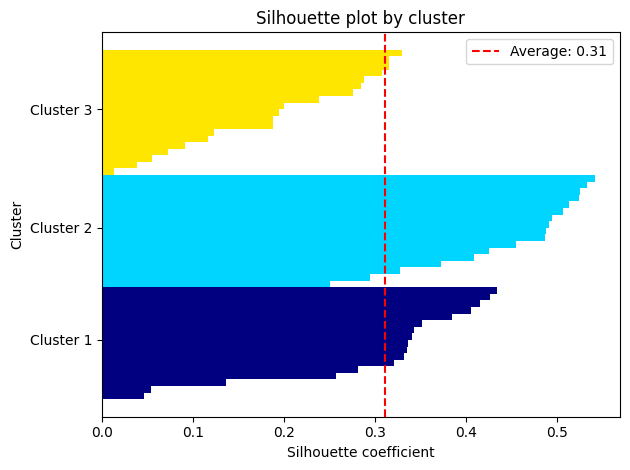

np.float64(0.3109832418289691)

In [45]:
plot_silhouette(ym_c3_ni20_maxi500, cluster_input)

In [46]:
final_c3_ni20_maxi500 = one_point_countries_win.copy()
final_c3_ni20_maxi500['cluster'] = ym_c3_ni20_maxi500.labels_
final_c3_ni20_maxi500['ISO_A3'] = coco.convert(names=final_c3_ni20_maxi500['Country'], to='ISO3')
clusters_c3_ni20_maxi500 = final_c3_ni20_maxi500[['Country', 'ISO_A3', 'cluster']].copy()
clusters_c3_ni20_maxi500.loc[:, 'Continent'] = coco.convert(
    names=clusters_c3_ni20_maxi500['Country'], to='continent'
)

In [47]:
print_cluster_groups(clusters_c3_ni20_maxi500)


🌍 Cluster 0 (17 countries):
 - Brazil (America)
 - Chile (America)
 - Colombia (America)
 - Czech (Europe)
 - Hungary (Europe)
 - India (Asia)
 - Japan (Asia)
 - Mexico (America)
 - Paraguay (America)
 - Philippines (Asia)
 - Russia (Europe)
 - Serbia (Europe)
 - South Africa (Africa)
 - South Korea (Asia)
 - Thailand (Asia)
 - Turkey (Asia)
 - USA (America)

🌍 Cluster 1 (17 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malta (Europe)
 - New Zealand (Oceania)
 - Portugal (Europe)
 - Slovakia (Europe)
 - Slovenia (Europe)

🌍 Cluster 2 (19 countries):
 - Australia (Oceania)
 - Canada (America)
 - Denmark (Europe)
 - France (Europe)
 - Germany (Europe)
 - Iceland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Malaysia (Asia)
 - Netherlands (Europe)
 - Norway (Europe)
 - Peru (Ameri

* Interesting, running the algorithm with more conservative hyperparameters the result was clusters with more variety in quantity, now greater similarity in quantity can be observed

In [48]:
clusters_c3_ni20_maxi500['Country'] = clusters_c3_ni20_maxi500['Country'].replace('Czech','Czech Republic')

In [49]:
clusters_c3_ni20_maxi500.to_parquet('../data/clusters/clusters_plusplus_c3_ni20_maxi500_without_outliers.parquet')

### Import and clean data for create synthetic data
* Import the data for hpi by country
* Observe if have Pararguay country
* Look if have the same countries that the df with the culsters
* Look if the name of the countries are in the same format "-" or "_"
* Delete countries that do not exist in the HPI dataframe

In [50]:
df_hpi_winsorized = pd.read_parquet('../data/hpi_index_winsorized.parquet')

In [51]:
df_hpi_winsorized.shape

(15, 53)

In [52]:
clusters_c2_ni10_maxi100.shape

(53, 4)

In [53]:
clusters_c2_ni20_maxi500.shape

(53, 4)

In [54]:
clusters_c3_ni20_maxi500.shape

(53, 4)

In [55]:
def find_countries_missing_from_clusters(df_hpi, df_clusters, country_column='Country'):
    """
    Identifies which countries are present in the HPI DataFrame but missing from the cluster DataFrame.

    Parameters:
    - df_hpi: DataFrame where columns are country names and rows are years (House Price Index data)
    - df_clusters: DataFrame with country names and cluster assignments
    - country_column: Name of the column in df_clusters that contains country names (default: 'Country')

    Returns:
    - List of country names that are in df_hpi but not in df_clusters
    """

    # Extract country names from HPI DataFrame (column headers)
    hpi_countries = set(df_hpi.columns)

    # Extract country names from cluster DataFrame
    cluster_countries = set(df_clusters[country_column].unique())

    # Find countries present in HPI but missing from clusters
    missing_countries = hpi_countries - cluster_countries

    # Print results
    if missing_countries:
        print("Countries in HPI that are missing from the cluster DataFrame:")
        for country in sorted(missing_countries):
            print(f" - {country}")
    else:
        print("All countries in the HPI DataFrame are present in the cluster DataFrame.")

    return list(missing_countries)

In [56]:
clusters_list = [clusters_c2_ni10_maxi100, clusters_c2_ni20_maxi500, clusters_c3_ni20_maxi500]

for cluster in clusters_list:
    find_countries_missing_from_clusters(df_hpi_winsorized, cluster)

Countries in HPI that are missing from the cluster DataFrame:
 - Year
Countries in HPI that are missing from the cluster DataFrame:
 - Year
Countries in HPI that are missing from the cluster DataFrame:
 - Year


### Apply transformation over hpi index
* Apply winsorization
* Apply round to two decimal
* Plot boxplot for every year

In [57]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

<Figure size 1400x600 with 0 Axes>

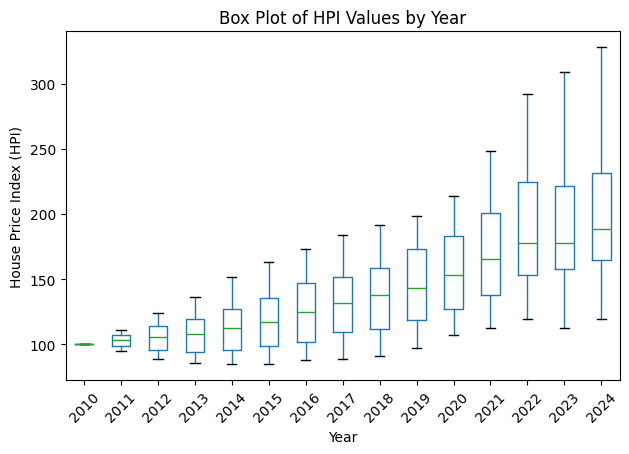

In [58]:
plot_hpi_boxplots_by_year(df_hpi_winsorized)

### Leverage The Law of Large Numbers
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [59]:
import random

In [60]:
def estimate_hpi_by_cluster_sampling(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Estimates synthetic HPI values for a randomly excluded country from a selected cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to use for sampling
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    - sample_size: Size of each sample (default: 30)
    - n_samples: Number of samples to generate (default: 1000)
    - plot: Whether to show histograms for each year (default: True)
    - seed: Optional random seed for reproducibility

    Returns:
    - synthetic_hpi: dict with estimated HPI values per year
    - excluded_country: name of the country left out
    - actual_values: dict with real HPI values of the excluded country
    """

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # Step 1: Get countries in the selected cluster that are present in the HPI DataFrame
    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]
    
    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data to perform exclusion and sampling.")
    
    # Step 2: Randomly exclude one country from those present in HPI
    excluded_country = random.choice(cluster_countries)
    sampling_countries = [c for c in cluster_countries if c != excluded_country]

    print(f"🔍 Cluster {cluster_id} selected. Excluding country: {excluded_country}")
    print(f"📊 Sampling from countries: {sampling_countries}")

    # Step 3: Prepare output containers
    synthetic_hpi = {}
    actual_values = {}

    # Step 4: Iterate over each year
    for _, row in df_hpi.iterrows():
        year = row[year_column]

        # Get HPI values for sampling countries
        values = row[sampling_countries].dropna().values

        # Get actual value of excluded country
        actual_value = row.get(excluded_country, np.nan)
        actual_values[year] = actual_value

        if len(values) == 0:
            print(f"⚠️ No HPI data available for cluster peers in year {year}")
            synthetic_hpi[year] = np.nan
            continue

        # Print available HPI values for sampling
        print(f"\n📅 Year {year} - Available HPI values for sampling:")
        print(values)

        # Generate sampling distribution
        sample_means = []
        cumulative_means = []
        for i in range(n_samples):
            sample = np.random.choice(values, size=sample_size, replace=True)
            mean = np.mean(sample)
            sample_means.append(mean)
            cumulative_means.append(np.mean(sample_means))  # track convergence

        # Compute 95% confidence interval
        lower_bound = np.percentile(sample_means, 2.5)
        upper_bound = np.percentile(sample_means, 97.5)

        # Plot side-by-side: histogram + convergence
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Histogram with confidence interval
        axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
        axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {excluded_country}")
        axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
        axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
        axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
        axes[0].set_xlabel("Sample Mean HPI")
        axes[0].set_ylabel("Frequency")
        axes[0].legend()
        axes[0].grid(True)

        # Convergence plot
        axes[1].plot(cumulative_means, color='purple')
        axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
        axes[1].set_title("Mean Convergence Over Iterations")
        axes[1].set_xlabel("Iteration")
        axes[1].set_ylabel("Cumulative Mean")
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()
        # Store synthetic HPI value
        synthetic_hpi[year] = np.mean(sample_means)

    return synthetic_hpi, excluded_country, actual_values

🔍 Cluster 0 selected. Excluding country: United Kingdom
📊 Sampling from countries: ['Australia', 'Brazil', 'Canada', 'Chile', 'Colombia', 'Czech Republic', 'Denmark', 'France', 'Germany', 'Hungary', 'Iceland', 'India', 'Israel', 'Italy', 'Japan', 'Malaysia', 'Mexico', 'Norway', 'Philippines', 'Poland', 'Russia', 'Serbia', 'South Africa', 'South Korea', 'Sweden', 'Thailand', 'Turkey', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


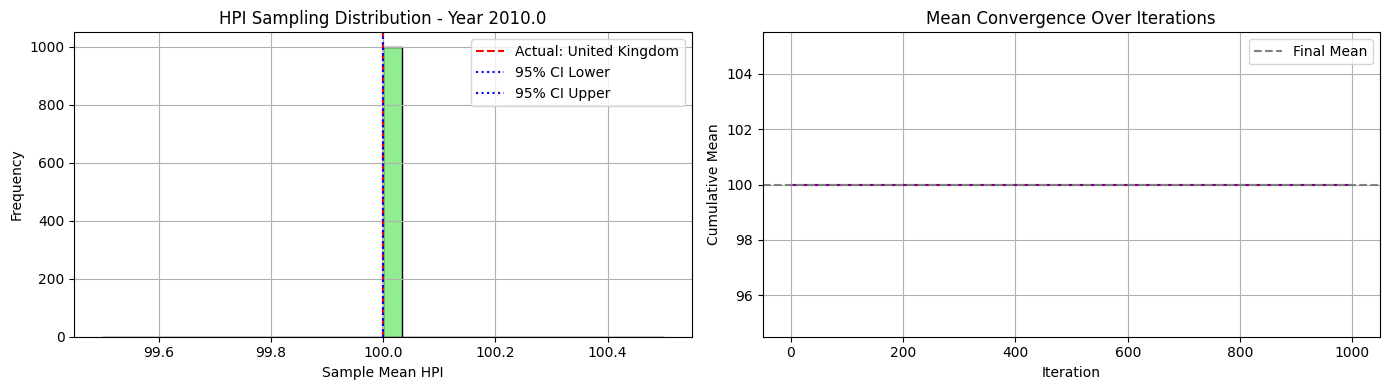


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 110.52 105.75 110.52 107.89 100.02  98.29 105.69 102.42  96.56
 105.5  110.52 110.52 101.36 100.07 109.83 105.8  108.01 105.57 100.08
  94.49  97.62 103.59 105.23 102.58 104.26 108.8   97.24]


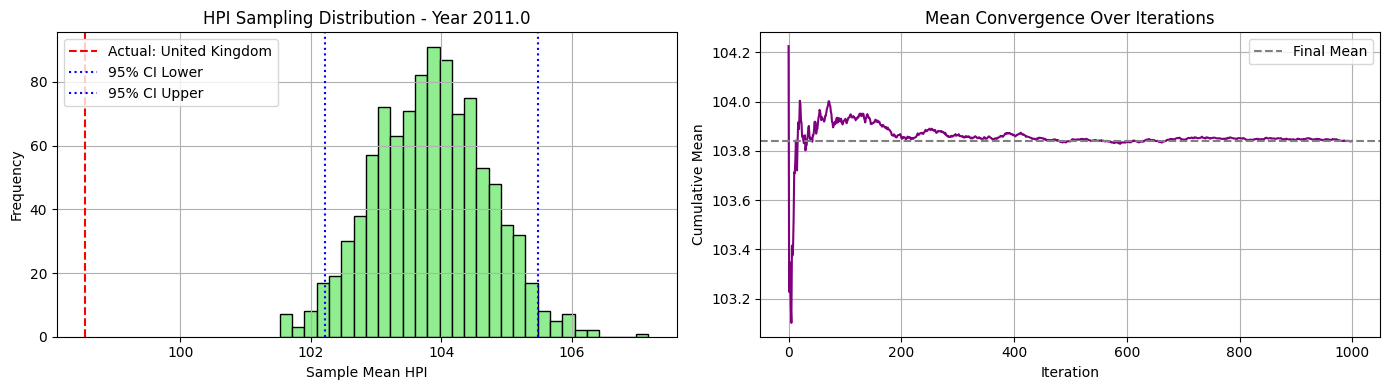


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 124.02 110.62 124.02 118.79  98.56  95.67 105.11 105.48  92.98
 112.38 124.02 114.1   98.77  99.19 124.02 109.17 115.34 114.94  96.58
  91.1   95.68 108.41 108.25 103.86 107.63 120.68 101.82]


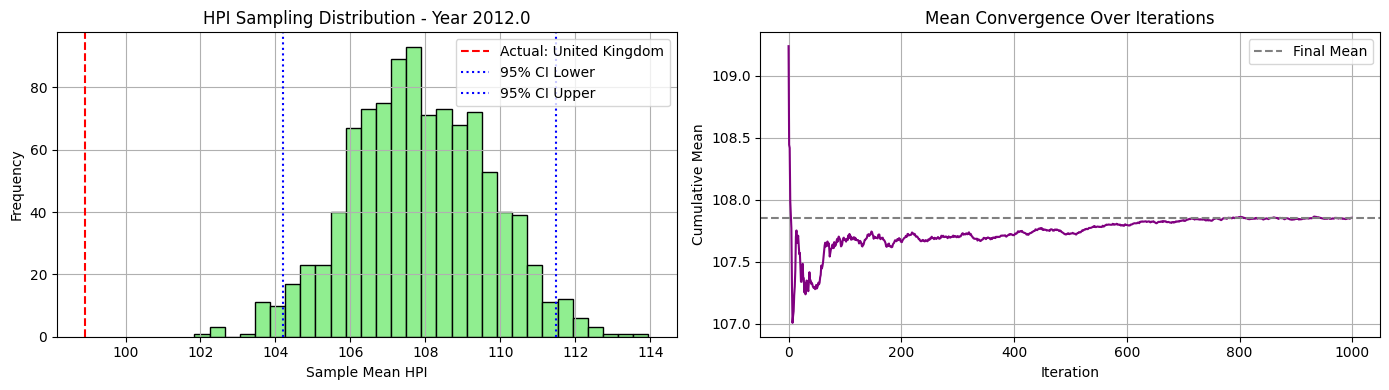


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 136.52 112.76 136.52 130.06  98.58  99.37 103.13 108.68  90.58
 119.18 136.52 124.45  92.38 100.81 136.52 114.75 119.98 127.86  92.35
  94.32  90.62 115.41 107.8  109.22 115.99 134.46 111.83]


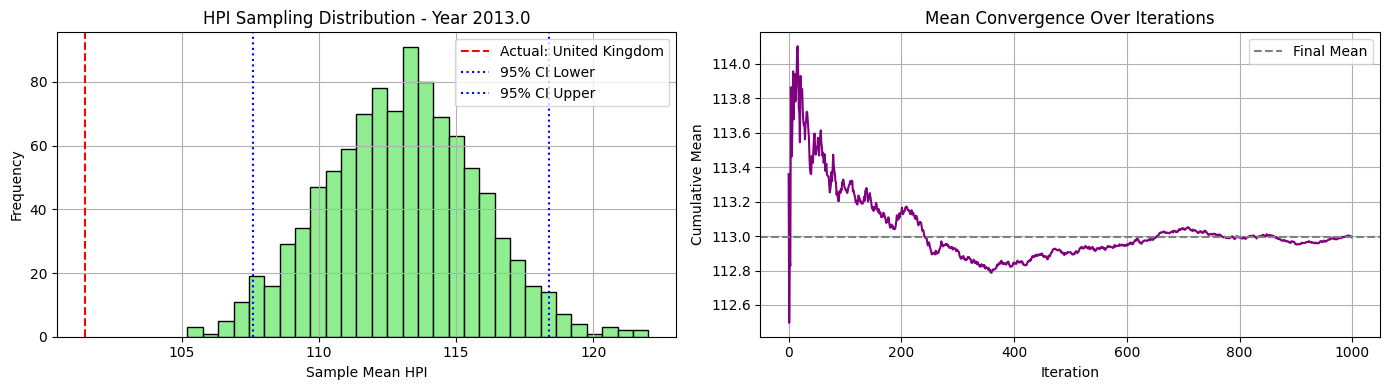


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 151.67 118.86 151.67 140.75 101.   103.12 101.58 111.85  94.37
 128.94 151.67 132.36  88.02 102.38 151.67 119.64 123.24 142.76  93.27
  95.84  95.77 123.99 109.43 119.52 127.07 151.25 118.88]


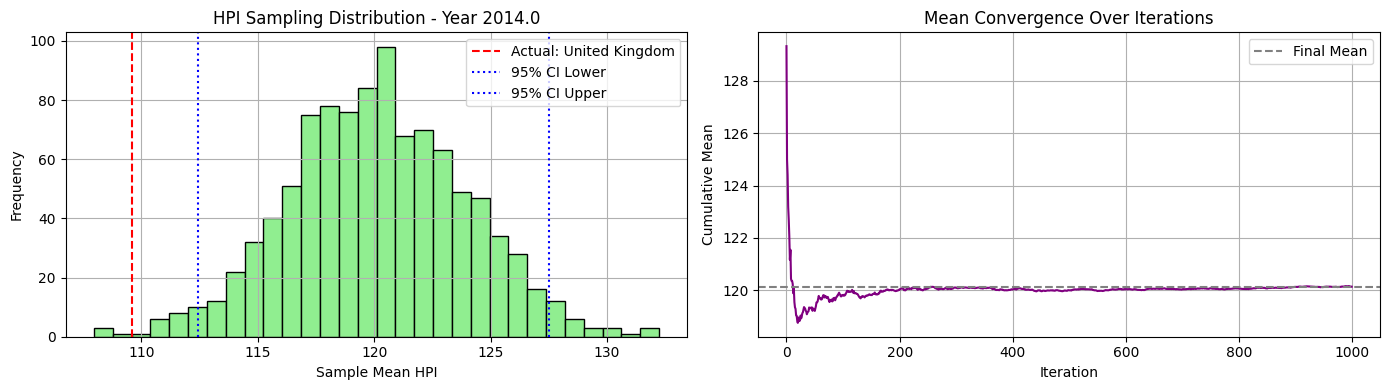


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 156.16 128.43 162.89 152.93 105.01 110.29 100.22 117.12 106.75
 139.74 162.89 140.12  84.67 104.86 162.89 129.39 130.76 157.04  94.69
  97.    99.5  131.8  113.08 135.2  136.   162.89 125.18]


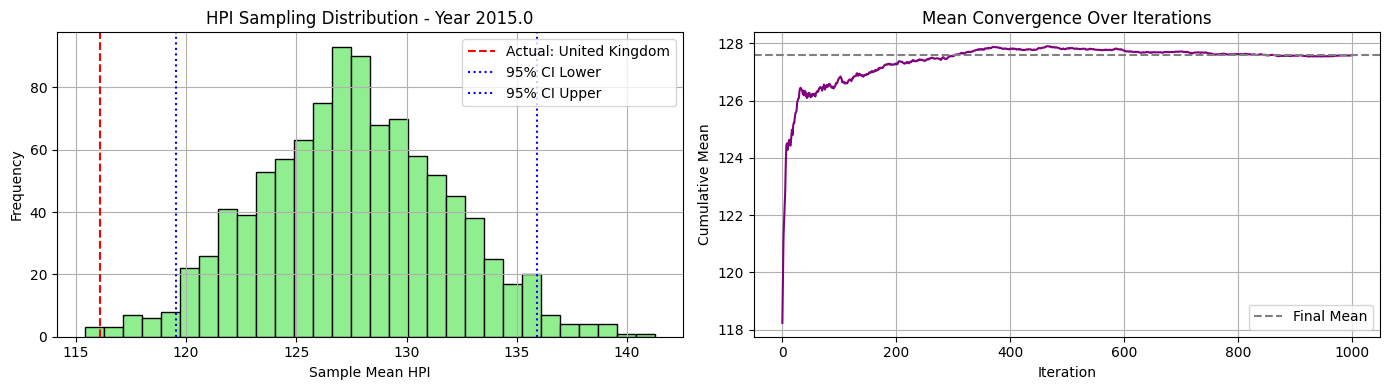


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 151.94 148.66 172.75 167.48 112.52 115.5  101.25 125.93 121.03
 154.59 172.75 150.56  88.1  107.18 172.75 138.82 139.95 172.75  96.44
  91.86 110.62 138.22 116.09 146.34 142.4  172.75 131.88]


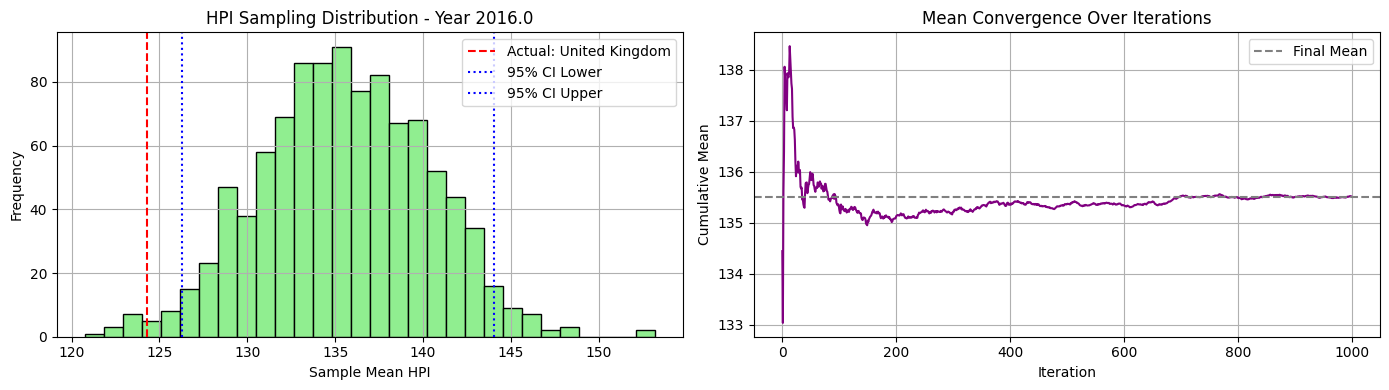


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 149.02 172.3  183.99 178.56 125.7  120.63 104.46 133.62 135.84
 183.99 183.99 156.44  88.54 109.91 183.99 149.69 146.91 178.82 100.16
  88.54 115.3  143.94 117.6  156.06 146.48 183.99 139.61]


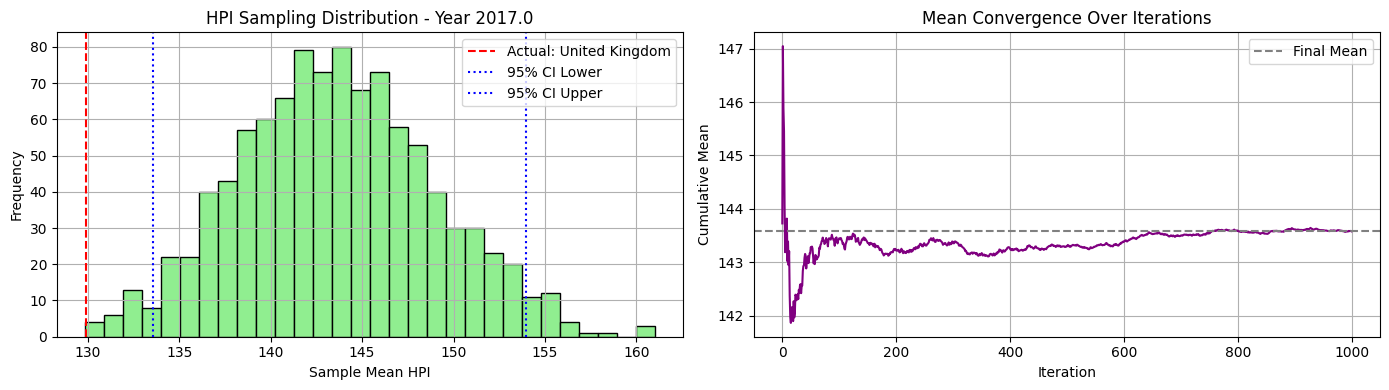


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  149.81 178.24 191.85 188.24 136.52 126.31 107.52 142.52 155.3
 191.85 191.85 155.14  90.72 112.04 191.85 162.97 149.04 183.82 106.75
  90.72 123.06 148.96 120.22 154.6  153.9  191.85 147.35]


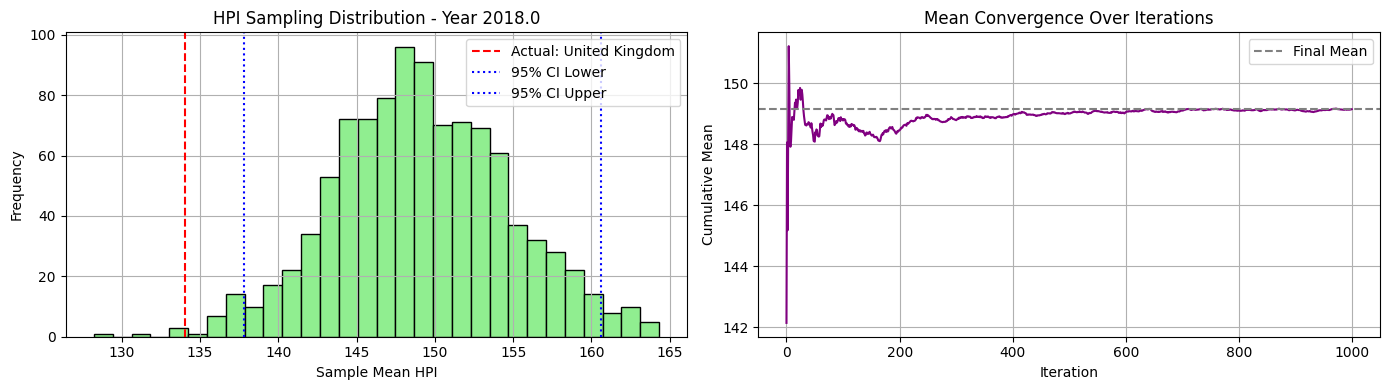


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 155.06 179.4  198.37 198.37 149.02 129.62 111.1  150.75 181.64
 198.37 198.37 158.06  97.25 113.84 196.06 176.92 152.73 195.26 116.01
  97.25 135.77 152.69 121.93 158.44 155.1  198.37 153.14]


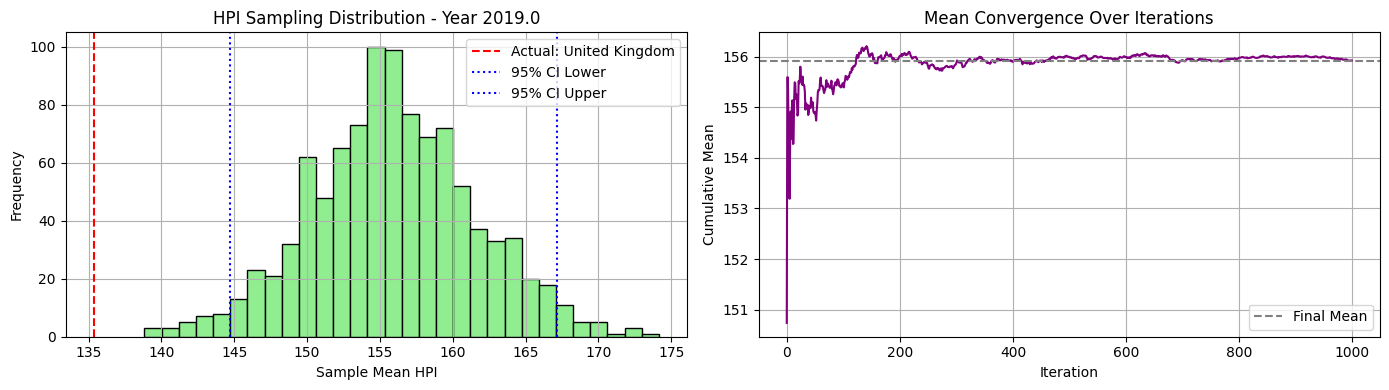


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 166.92 190.73 213.74 203.12 161.56 136.24 116.89 162.48 190.63
 213.74 213.74 162.9  106.71 113.93 198.37 187.18 159.24 213.74 128.18
 106.71 149.28 156.31 126.56 165.09 160.6  213.74 163.52]


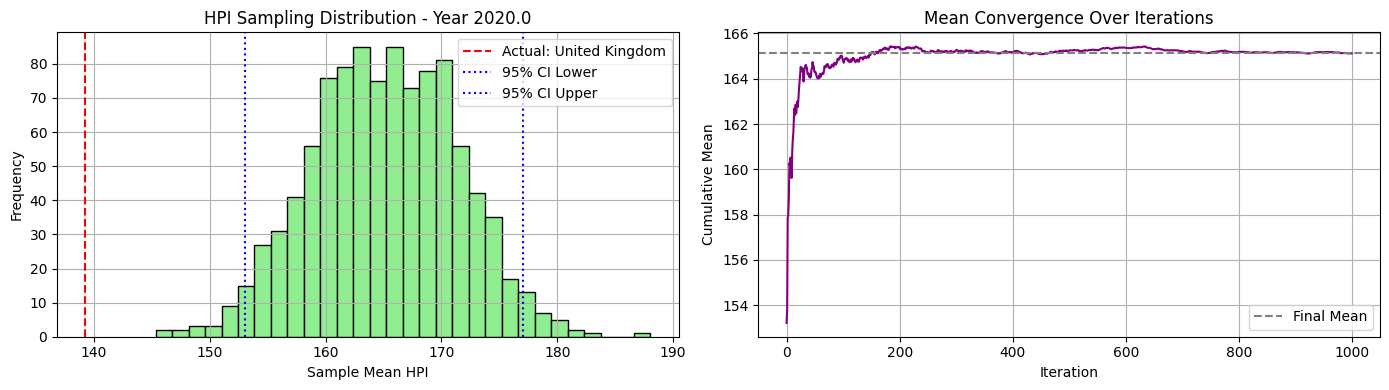


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 180.02 214.88 248.26 214.9  193.46 152.2  124.38 181.28 222.1
 248.26 248.26 176.65 112.34 120.7  200.69 201.94 175.91 211.74 139.92
 121.41 166.04 166.82 143.73 181.79 164.23 248.26 188.56]


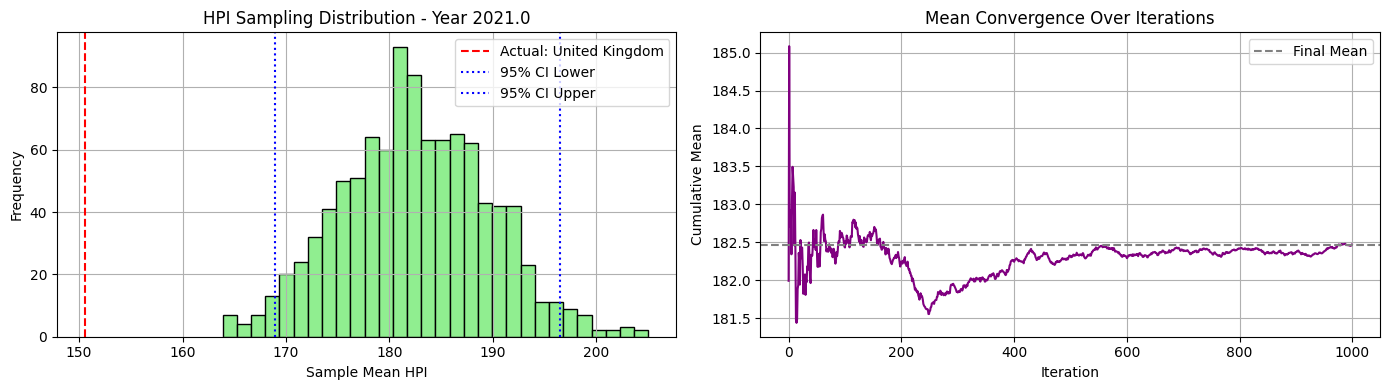


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 185.16 235.32 292.18 230.   226.15 151.49 132.1  190.42 271.5
 292.18 292.18 207.16 118.98 130.84 207.75 219.93 185.13 223.73 156.43
 155.16 191.49 174.03 153.22 188.27 169.16 292.18 213.  ]


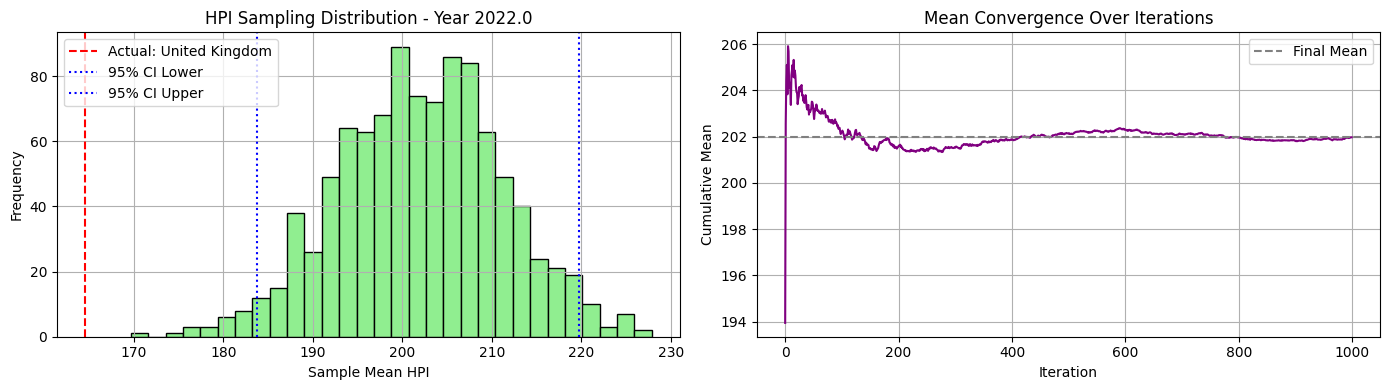


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 191.27 221.05 309.37 245.75 222.4  151.24 131.52 174.25 290.98
 309.37 309.37 214.23 112.27 134.8  216.19 243.89 184.12 248.04 170.23
 157.88 209.99 176.62 143.99 178.36 174.79 309.37 221.72]


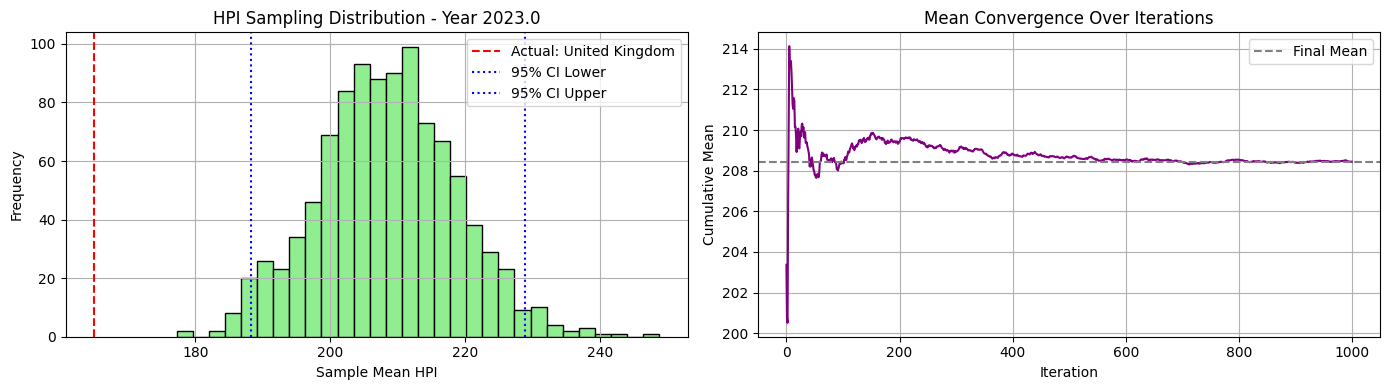


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 203.78 217.35 328.24 269.02 233.42 156.73 126.68 171.5  328.1
 328.24 328.24 224.54 119.1  138.61 225.06 266.38 189.05 256.03 195.72
 186.66 220.7  178.1  142.46 178.49 178.06 328.24 231.23]


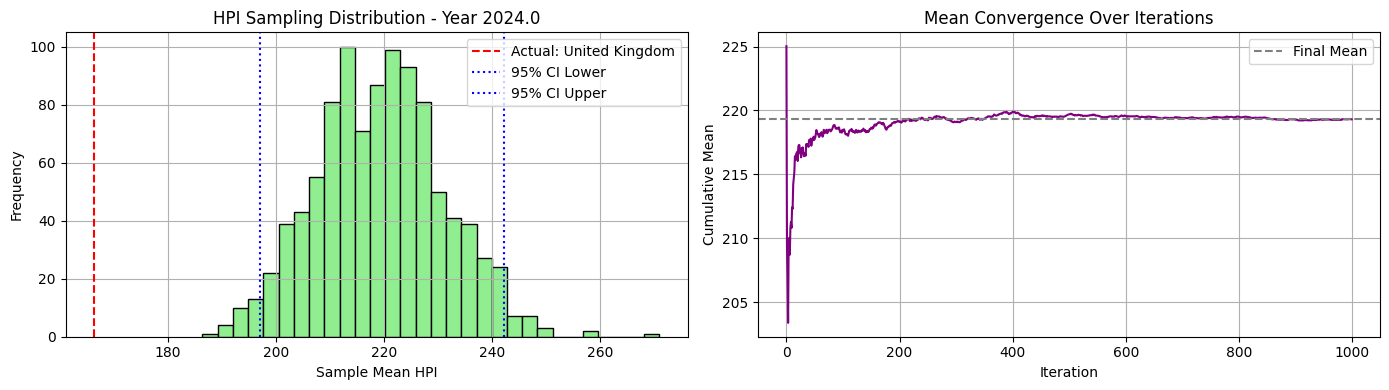

In [78]:
synthetic_c2_ni10_maxi100_00, excluded_c2_ni10_maxi100_00, actual_c2_ni10_maxi100_00 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni10_maxi100, cluster_id=0, seed=56)

🔍 Cluster 1 selected. Excluding country: Romania
📊 Sampling from countries: ['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Netherlands', 'New Zealand', 'Peru', 'Portugal', 'Singapore', 'Slovakia', 'Slovenia', 'Spain', 'Switzerland']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100.]


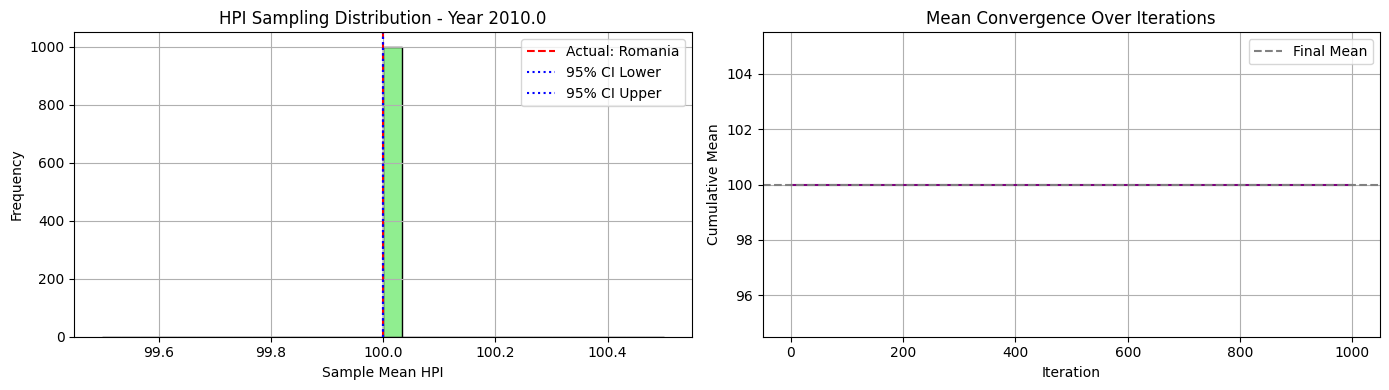


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58  94.49 100.16  96.68 108.47 103.17  94.53  94.49 110.42
 106.6  103.68  98.63  98.02 100.75 110.52  95.1  109.46  98.46 102.72
  94.49 107.51]


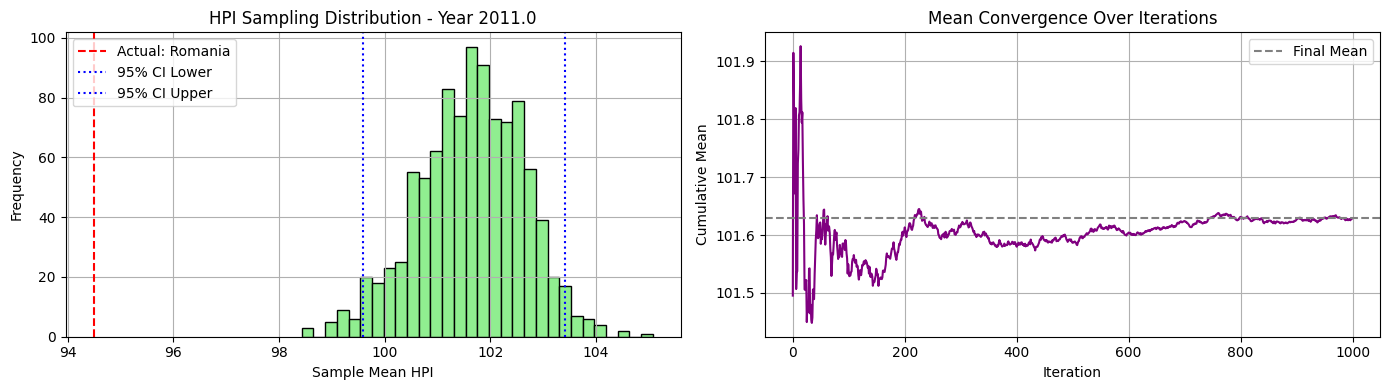


📅 Year 2012.0 - Available HPI values for sampling:
[117.13 106.02  92.69  98.62  91.54 116.34 105.64  88.37  88.37 113.71
 106.36 108.03 101.62  91.44 105.25 124.02  88.37 112.02  95.73  95.63
  88.37 113.72]


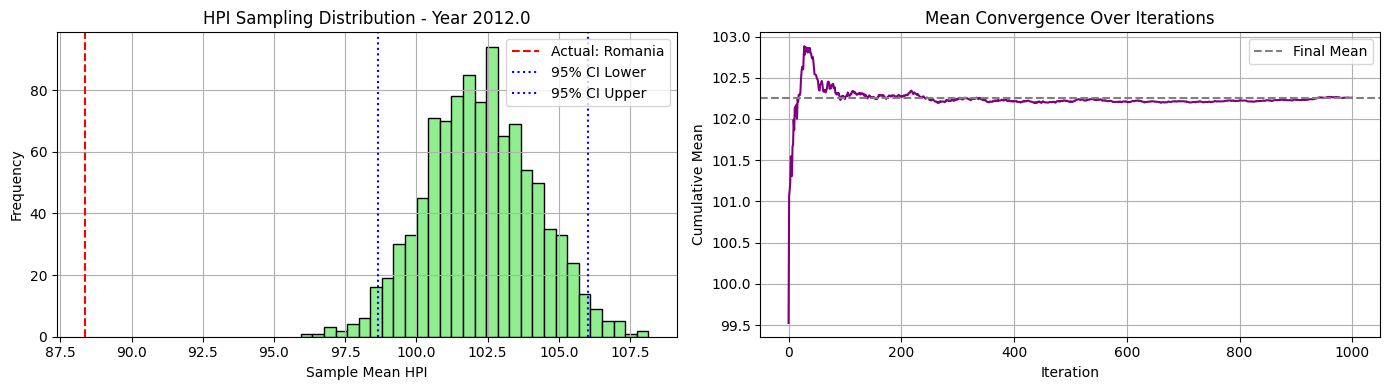


📅 Year 2013.0 - Available HPI values for sampling:
[122.59 107.59  90.65  94.7   85.58 128.77 106.87  85.58  85.58 121.5
 107.65 113.42 101.21  85.95 114.59 136.52  86.7  115.56  96.53  90.62
  85.58 118.3 ]


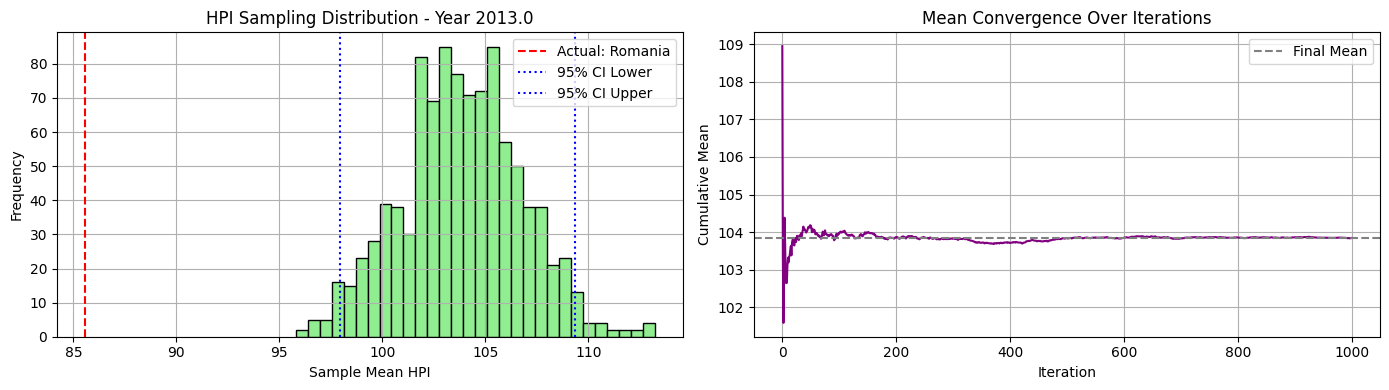


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  91.95  93.19  84.64 146.41 106.5   84.64  84.66 128.78
 114.57 118.39 103.79  86.66 122.03 151.67  90.38 112.25  97.8   84.64
  84.64 121.46]


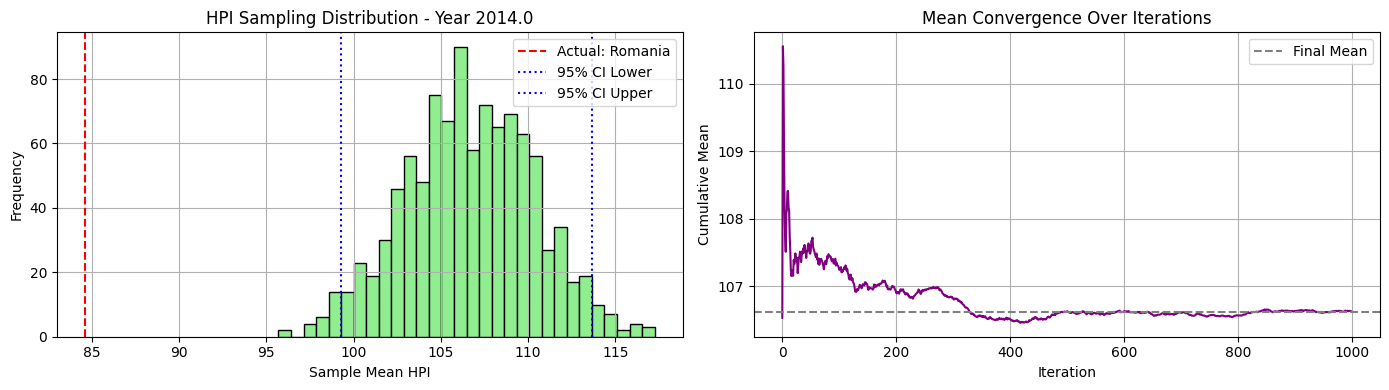


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  94.51  90.54  84.67 156.46 106.5   84.67  94.36 124.46
 118.76 124.78 109.83  89.69 137.18 162.89  93.15 107.92 103.    85.32
  84.67 124.08]


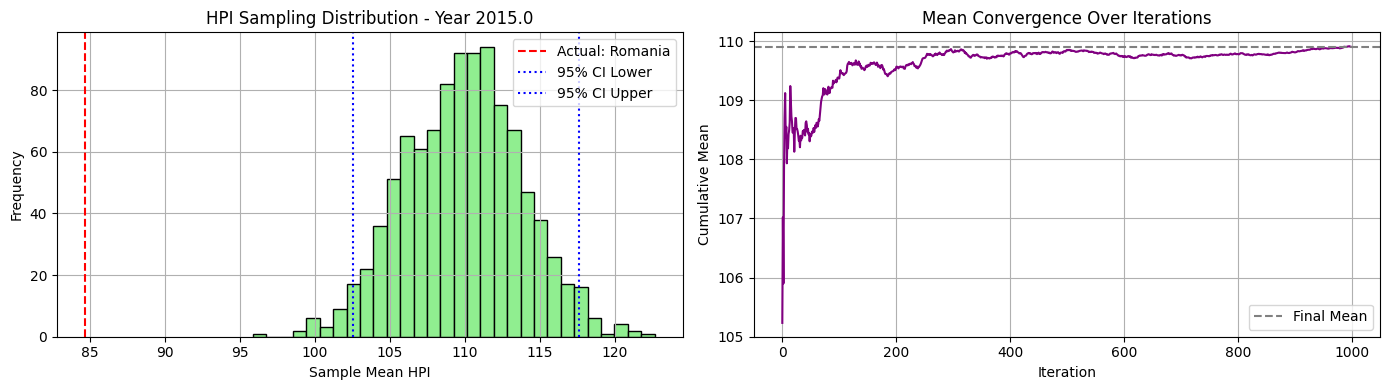


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72 101.15  91.33  88.1  163.86 107.86  88.1  101.42 135.02
 125.16 132.28 115.82  94.43 156.62 164.18  99.78 104.55 109.87  88.1
  88.1  124.32]


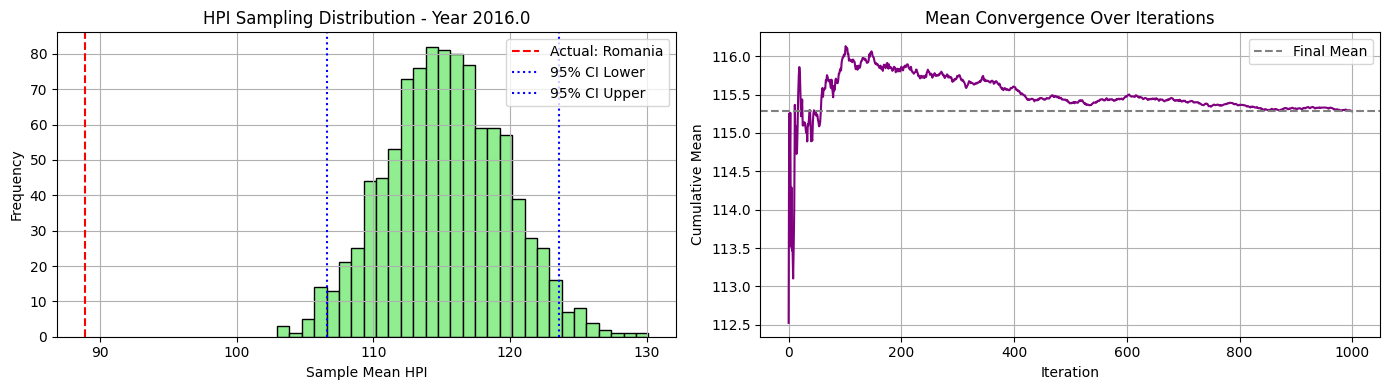


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66 109.91  94.84  88.54 172.91 109.02  88.54 112.44 146.87
 136.34 139.69 121.94 102.06 166.8  168.   108.99 103.4  116.3   95.38
  88.54 125.42]


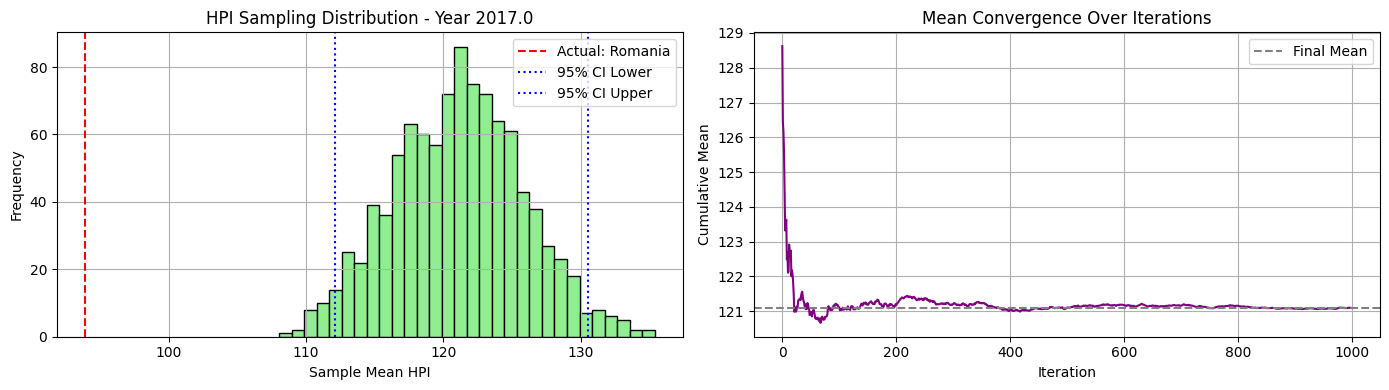


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 117.15 100.59  90.72 183.13 110.06  90.72 123.96 160.92
 146.29 149.55 129.02 111.57 172.8  168.42 120.19 111.46 124.97 103.7
  90.72 129.16]


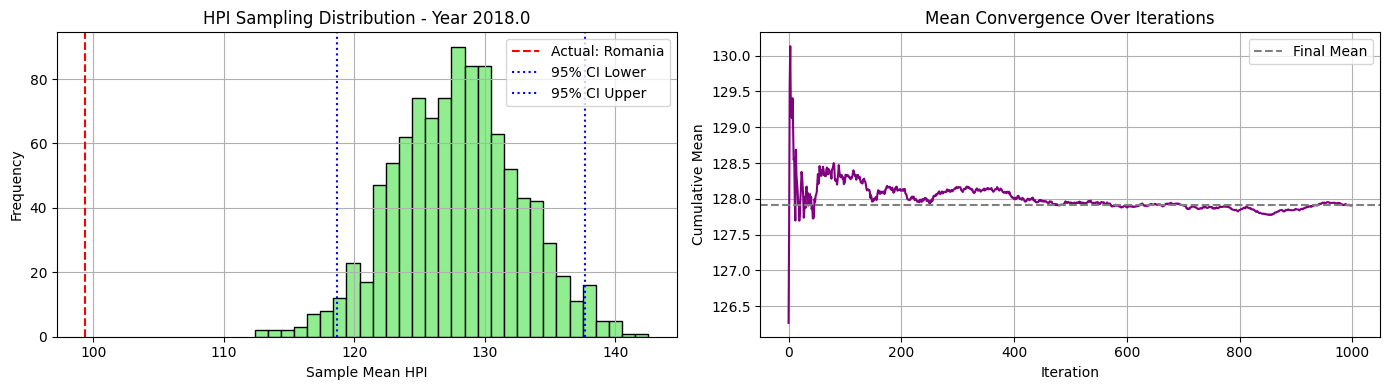


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 124.2  109.64  97.25 195.98 110.52  97.25 126.85 175.33
 156.3  164.68 136.9  119.62 178.19 172.03 132.16 113.98 136.39 110.65
  97.25 133.99]


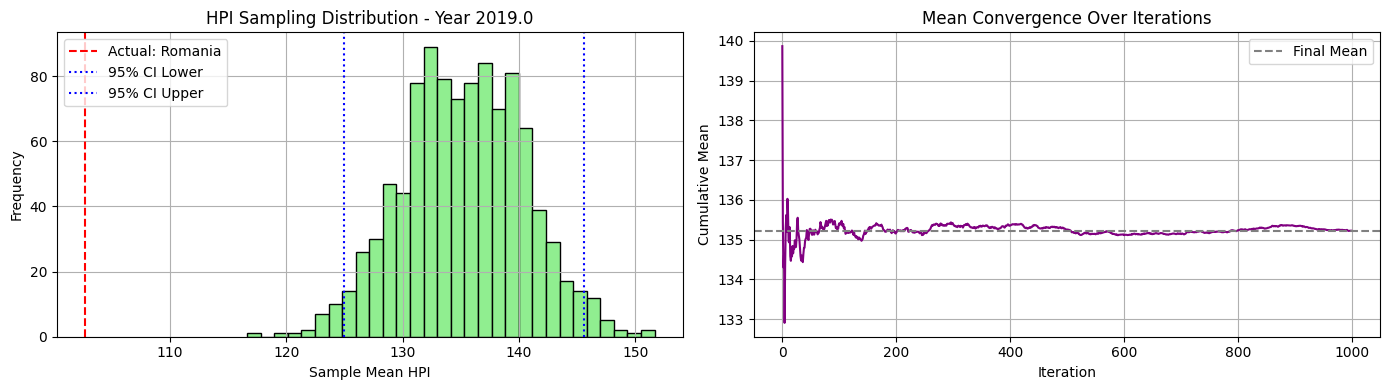


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 129.87 118.06 106.71 207.78 112.49 106.71 127.24 181.42
 167.66 188.57 141.54 129.21 196.31 173.67 143.75 115.8  149.36 115.74
 106.71 137.31]


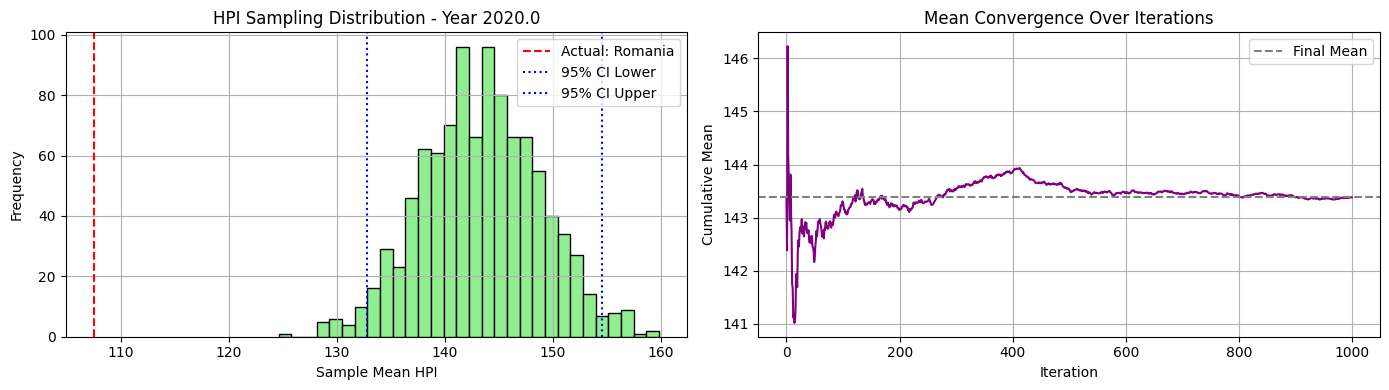


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 141.14 126.64 112.34 239.04 117.62 112.34 137.77 201.18
 194.58 214.81 148.74 147.93 248.26 173.6  157.27 125.04 158.94 129.1
 112.34 145.16]


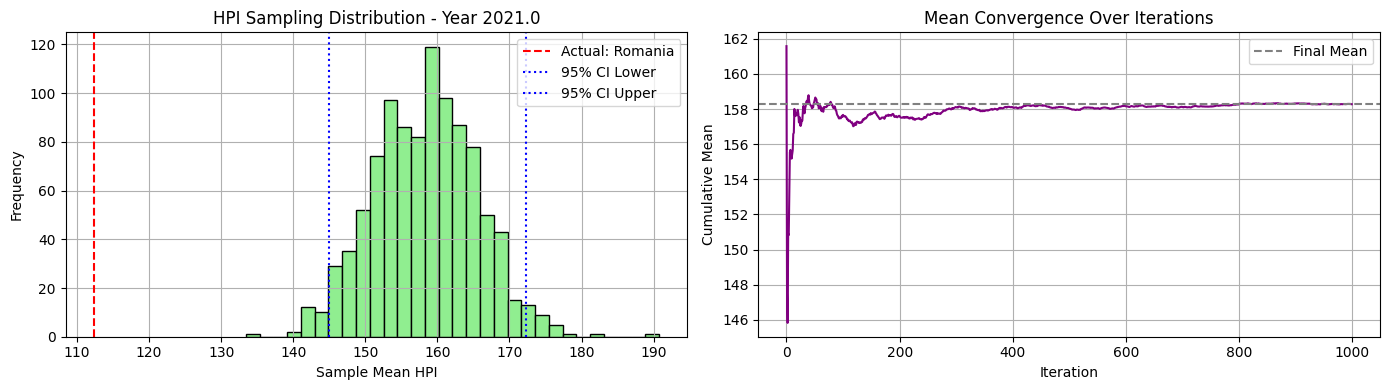


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 160.59 145.44 118.98 292.18 118.98 118.98 154.73 229.01
 231.64 235.34 158.62 167.57 249.69 172.65 177.14 137.74 180.7  148.16
 118.98 154.42]


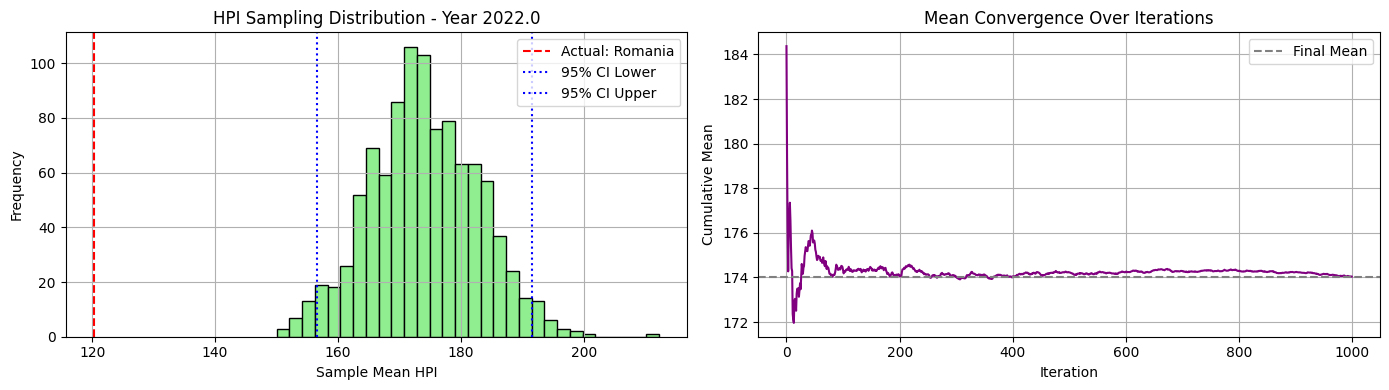


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 176.43 162.82 112.27 309.37 112.27 112.27 159.48 237.56
 254.38 214.   168.5  164.36 233.54 175.16 191.66 148.01 180.36 158.88
 112.27 157.81]


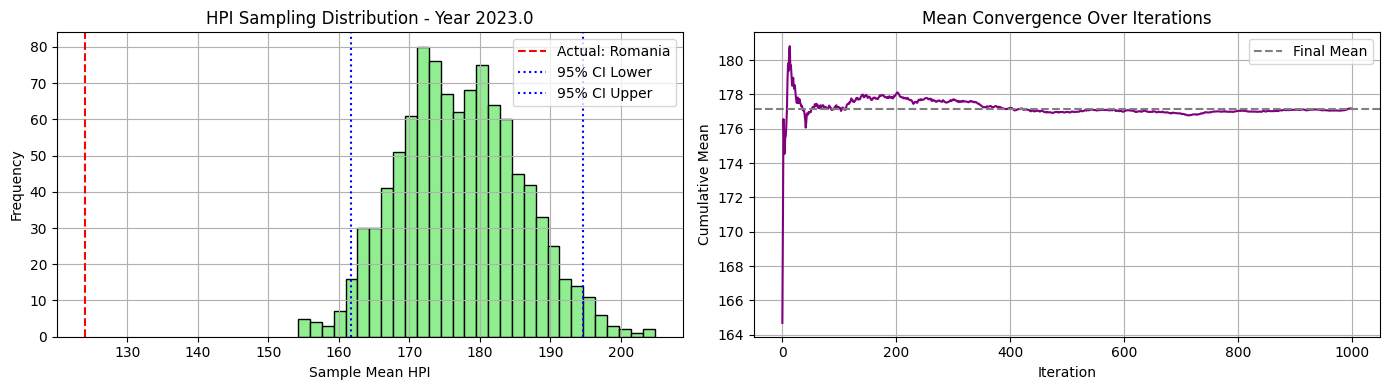


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 205.53 179.7  119.1  328.24 119.1  119.1  173.07 247.54
 279.12 202.74 179.35 177.7  233.68 175.38 209.06 155.12 187.15 170.56
 119.1  160.56]


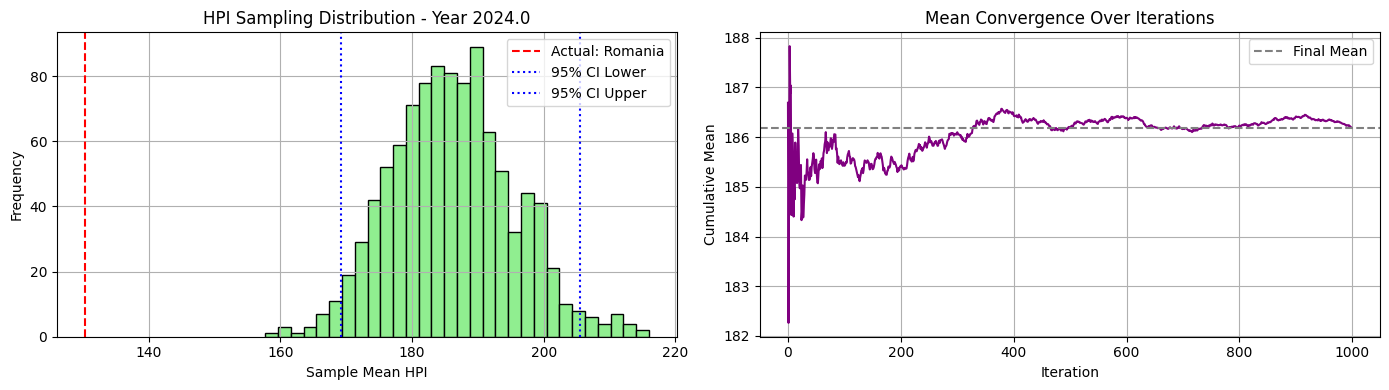

In [79]:
synthetic_c2_ni10_maxi100_01, excluded_c2_ni10_maxi100_01, actual_c2_ni10_maxi100_01 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni10_maxi100, cluster_id=1, seed=56)

🔍 Cluster 0 selected. Excluding country: United Kingdom
📊 Sampling from countries: ['Australia', 'Brazil', 'Canada', 'Chile', 'Colombia', 'Czech Republic', 'Denmark', 'France', 'Germany', 'Hungary', 'Iceland', 'India', 'Israel', 'Italy', 'Japan', 'Malaysia', 'Mexico', 'Norway', 'Philippines', 'Poland', 'Russia', 'Serbia', 'South Africa', 'South Korea', 'Sweden', 'Thailand', 'Turkey', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


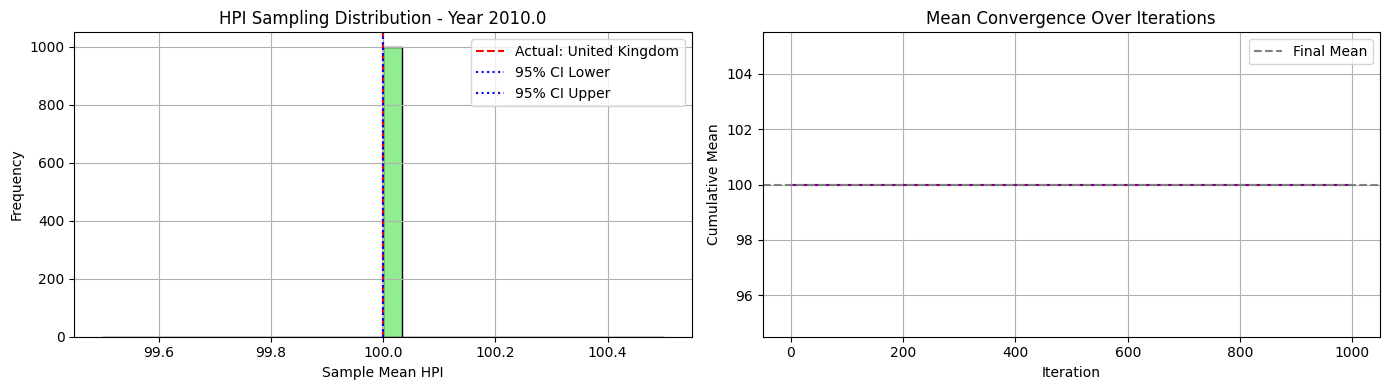


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 110.52 105.75 110.52 107.89 100.02  98.29 105.69 102.42  96.56
 105.5  110.52 110.52 101.36 100.07 109.83 105.8  108.01 105.57 100.08
  94.49  97.62 103.59 105.23 102.58 104.26 108.8   97.24]


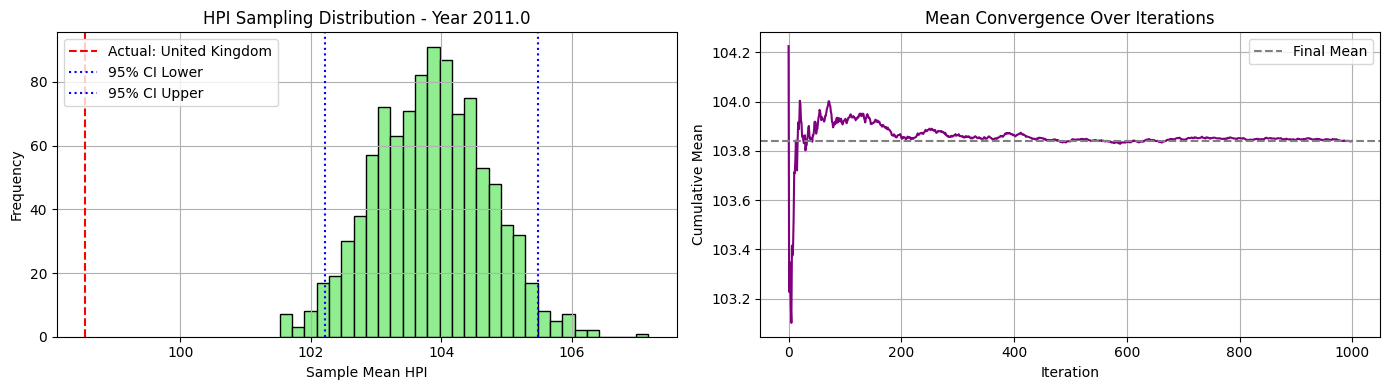


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 124.02 110.62 124.02 118.79  98.56  95.67 105.11 105.48  92.98
 112.38 124.02 114.1   98.77  99.19 124.02 109.17 115.34 114.94  96.58
  91.1   95.68 108.41 108.25 103.86 107.63 120.68 101.82]


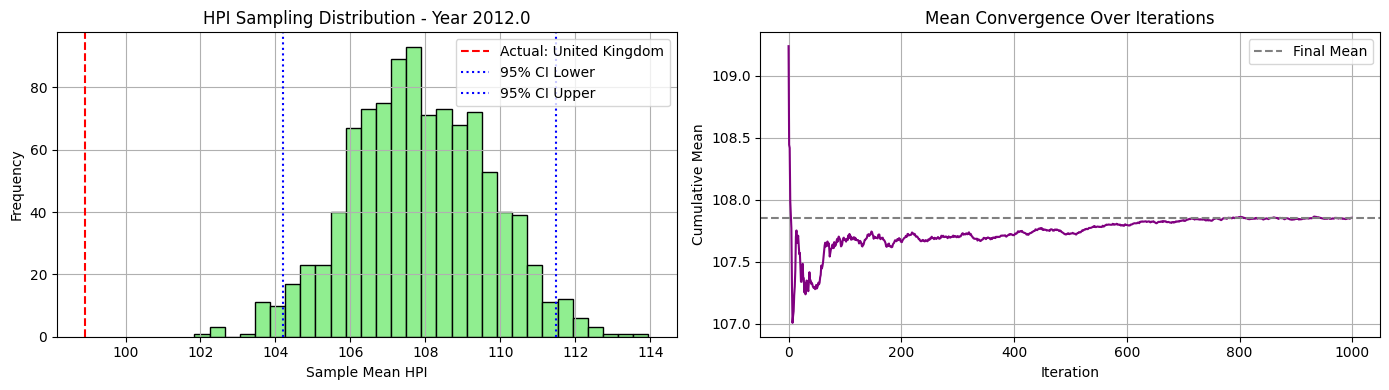


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 136.52 112.76 136.52 130.06  98.58  99.37 103.13 108.68  90.58
 119.18 136.52 124.45  92.38 100.81 136.52 114.75 119.98 127.86  92.35
  94.32  90.62 115.41 107.8  109.22 115.99 134.46 111.83]


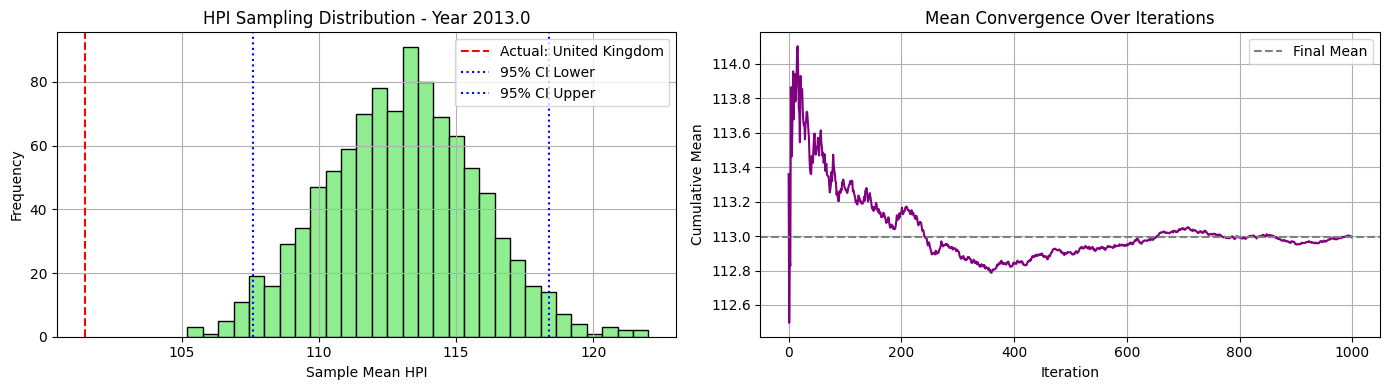


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 151.67 118.86 151.67 140.75 101.   103.12 101.58 111.85  94.37
 128.94 151.67 132.36  88.02 102.38 151.67 119.64 123.24 142.76  93.27
  95.84  95.77 123.99 109.43 119.52 127.07 151.25 118.88]


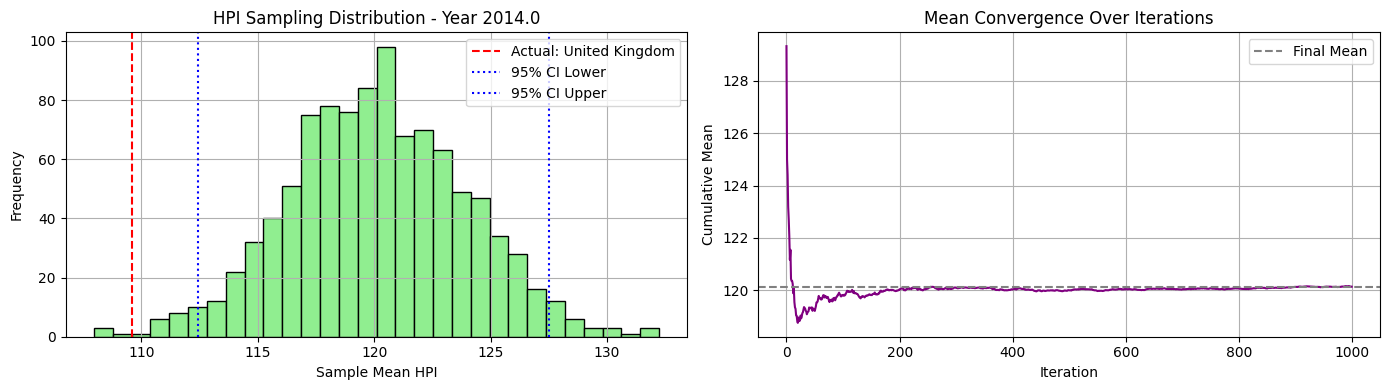


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 156.16 128.43 162.89 152.93 105.01 110.29 100.22 117.12 106.75
 139.74 162.89 140.12  84.67 104.86 162.89 129.39 130.76 157.04  94.69
  97.    99.5  131.8  113.08 135.2  136.   162.89 125.18]


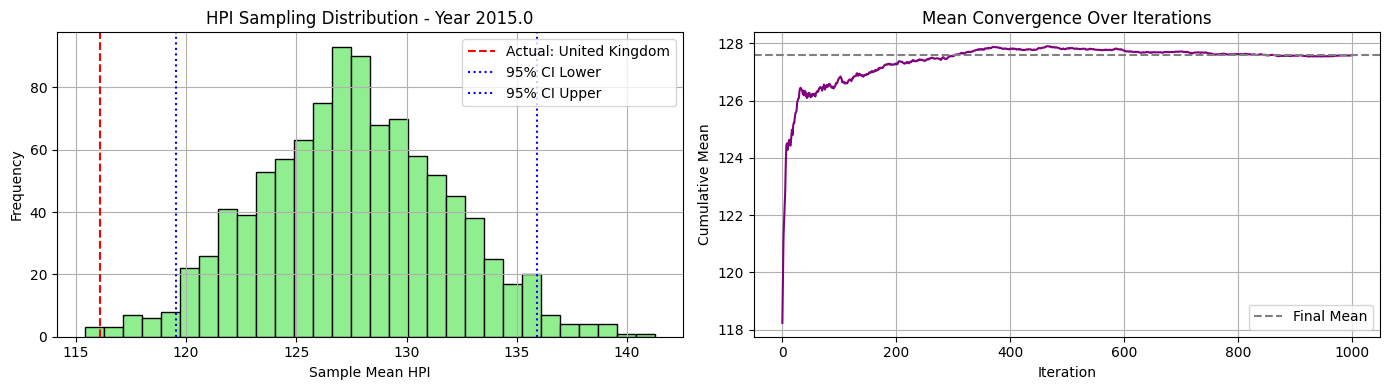


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 151.94 148.66 172.75 167.48 112.52 115.5  101.25 125.93 121.03
 154.59 172.75 150.56  88.1  107.18 172.75 138.82 139.95 172.75  96.44
  91.86 110.62 138.22 116.09 146.34 142.4  172.75 131.88]


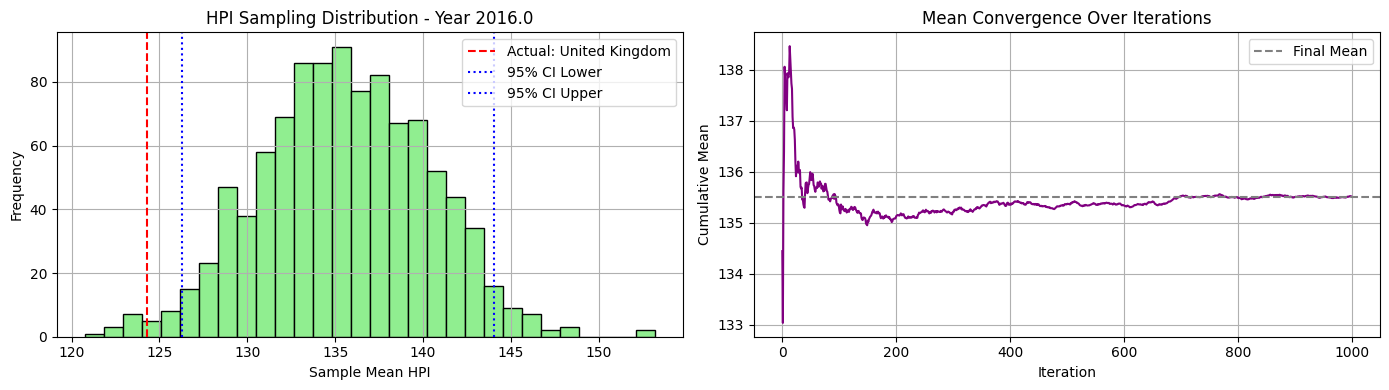


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 149.02 172.3  183.99 178.56 125.7  120.63 104.46 133.62 135.84
 183.99 183.99 156.44  88.54 109.91 183.99 149.69 146.91 178.82 100.16
  88.54 115.3  143.94 117.6  156.06 146.48 183.99 139.61]


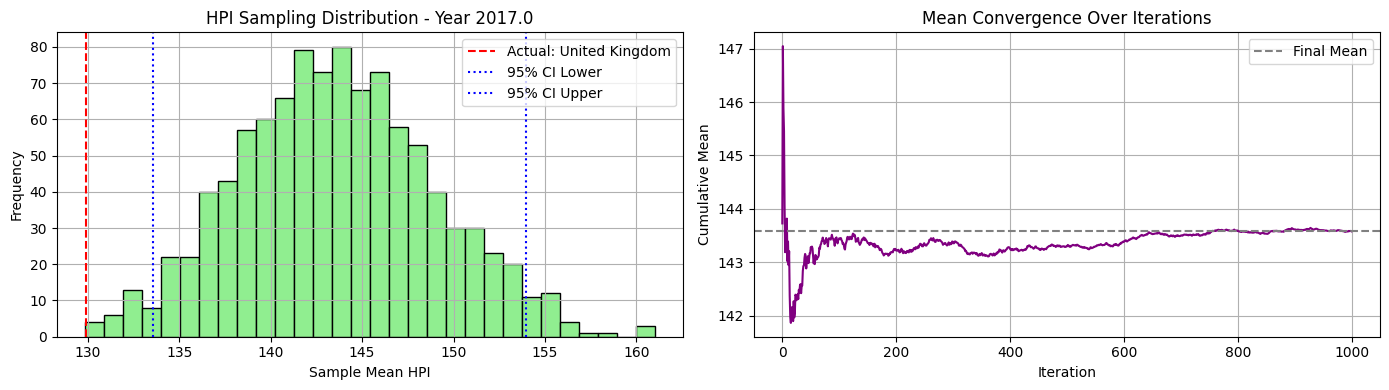


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  149.81 178.24 191.85 188.24 136.52 126.31 107.52 142.52 155.3
 191.85 191.85 155.14  90.72 112.04 191.85 162.97 149.04 183.82 106.75
  90.72 123.06 148.96 120.22 154.6  153.9  191.85 147.35]


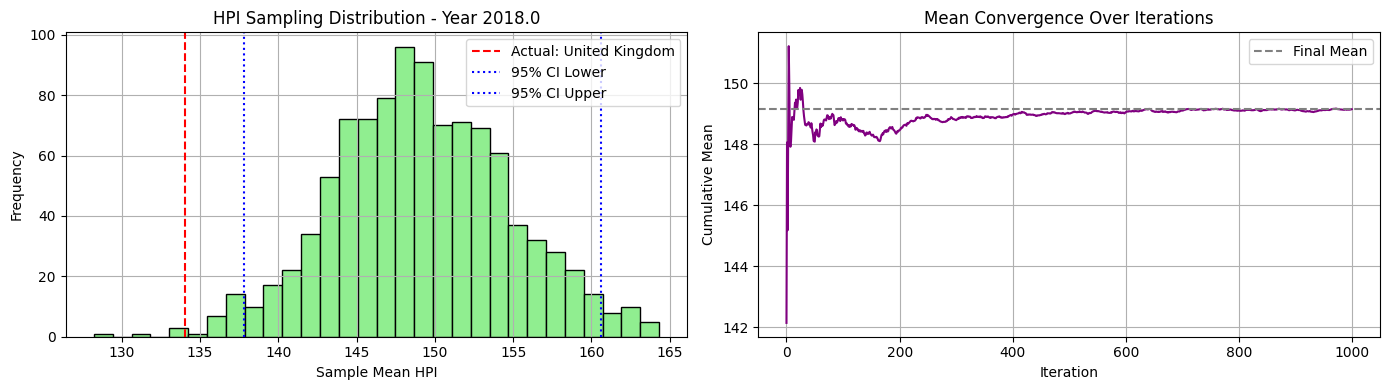


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 155.06 179.4  198.37 198.37 149.02 129.62 111.1  150.75 181.64
 198.37 198.37 158.06  97.25 113.84 196.06 176.92 152.73 195.26 116.01
  97.25 135.77 152.69 121.93 158.44 155.1  198.37 153.14]


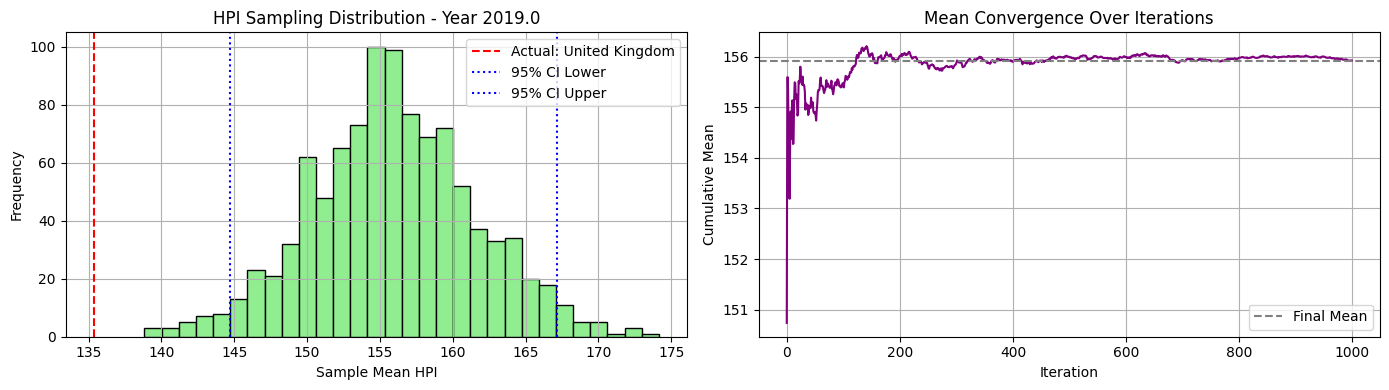


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 166.92 190.73 213.74 203.12 161.56 136.24 116.89 162.48 190.63
 213.74 213.74 162.9  106.71 113.93 198.37 187.18 159.24 213.74 128.18
 106.71 149.28 156.31 126.56 165.09 160.6  213.74 163.52]


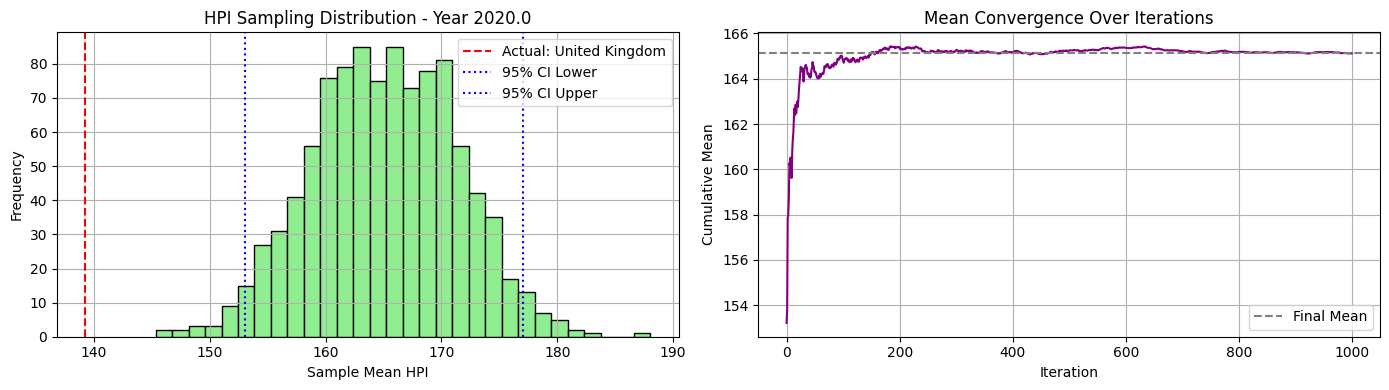


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 180.02 214.88 248.26 214.9  193.46 152.2  124.38 181.28 222.1
 248.26 248.26 176.65 112.34 120.7  200.69 201.94 175.91 211.74 139.92
 121.41 166.04 166.82 143.73 181.79 164.23 248.26 188.56]


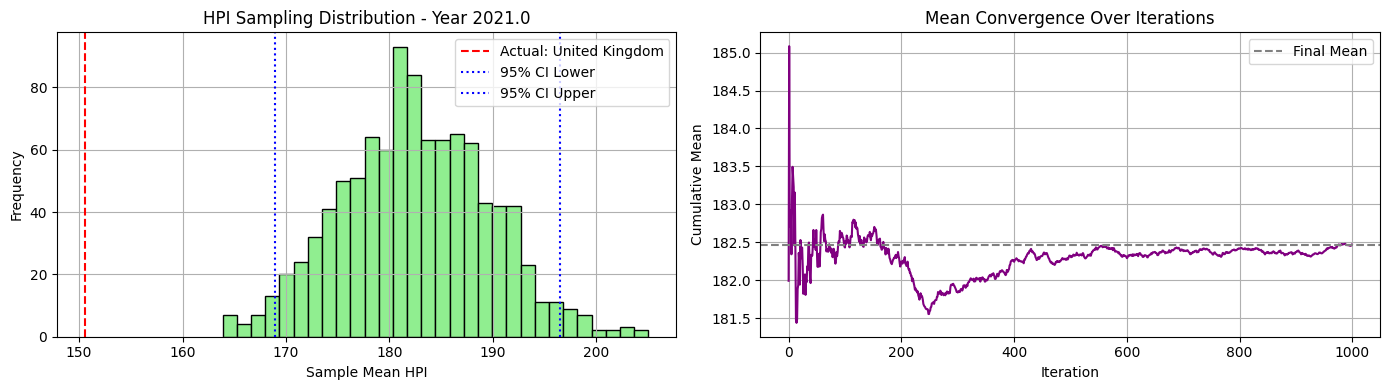


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 185.16 235.32 292.18 230.   226.15 151.49 132.1  190.42 271.5
 292.18 292.18 207.16 118.98 130.84 207.75 219.93 185.13 223.73 156.43
 155.16 191.49 174.03 153.22 188.27 169.16 292.18 213.  ]


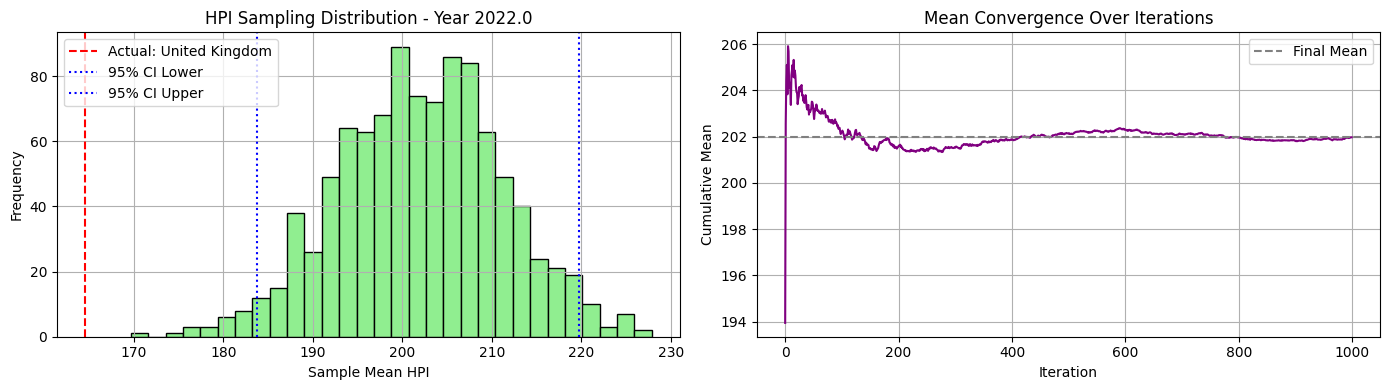


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 191.27 221.05 309.37 245.75 222.4  151.24 131.52 174.25 290.98
 309.37 309.37 214.23 112.27 134.8  216.19 243.89 184.12 248.04 170.23
 157.88 209.99 176.62 143.99 178.36 174.79 309.37 221.72]


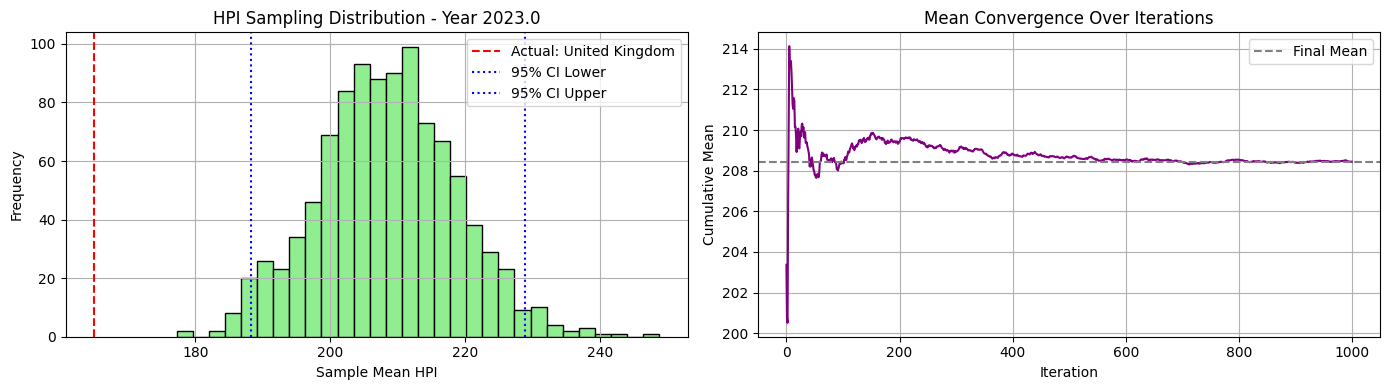


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 203.78 217.35 328.24 269.02 233.42 156.73 126.68 171.5  328.1
 328.24 328.24 224.54 119.1  138.61 225.06 266.38 189.05 256.03 195.72
 186.66 220.7  178.1  142.46 178.49 178.06 328.24 231.23]


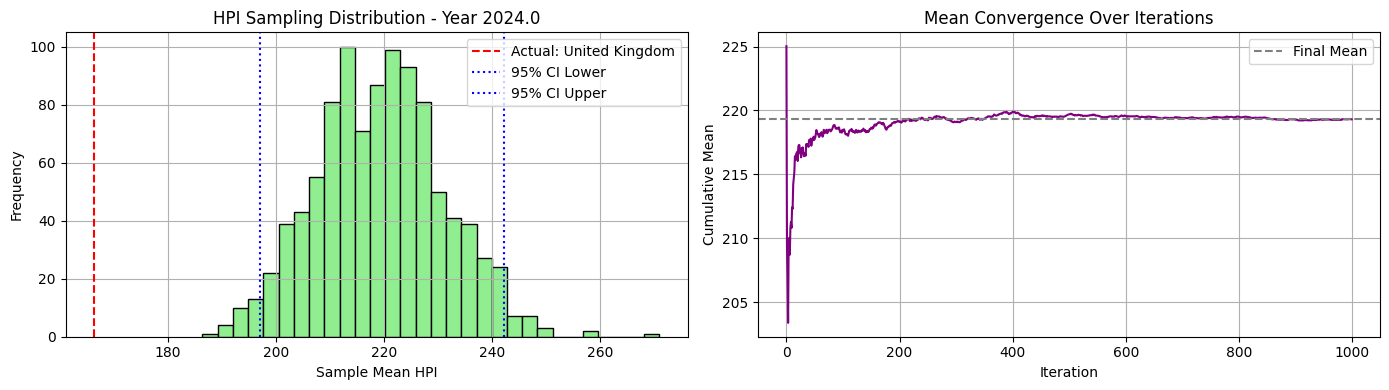

In [83]:
synthetic_c2_ni20_maxi500_00, excluded_c2_ni20_maxi500_00, actual_c2_ni20_maxi500_00 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni20_maxi500, cluster_id=0, seed=56)

🔍 Cluster 1 selected. Excluding country: Romania
📊 Sampling from countries: ['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Netherlands', 'New Zealand', 'Peru', 'Portugal', 'Singapore', 'Slovakia', 'Slovenia', 'Spain', 'Switzerland']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100.]


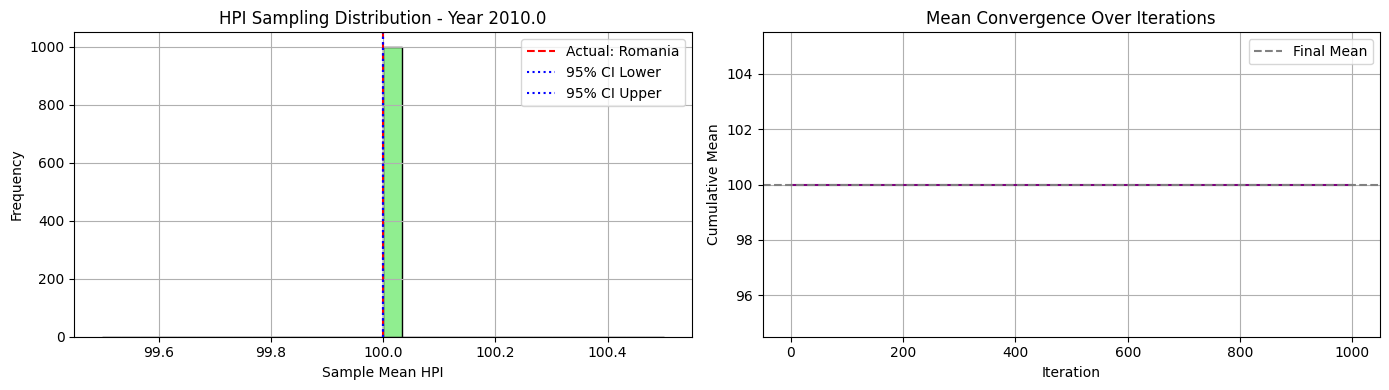


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58  94.49 100.16  96.68 108.47 103.17  94.53  94.49 110.42
 106.6  103.68  98.63  98.02 100.75 110.52  95.1  109.46  98.46 102.72
  94.49 107.51]


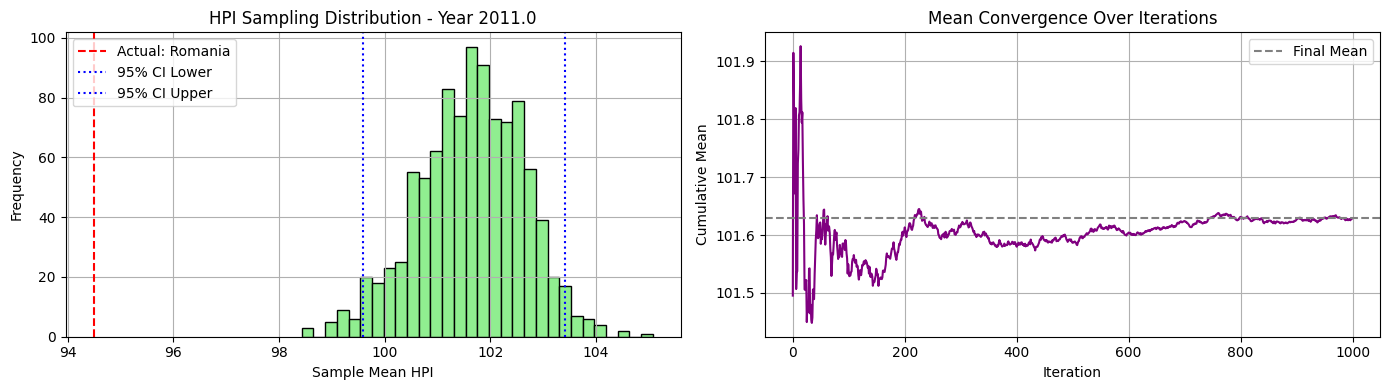


📅 Year 2012.0 - Available HPI values for sampling:
[117.13 106.02  92.69  98.62  91.54 116.34 105.64  88.37  88.37 113.71
 106.36 108.03 101.62  91.44 105.25 124.02  88.37 112.02  95.73  95.63
  88.37 113.72]


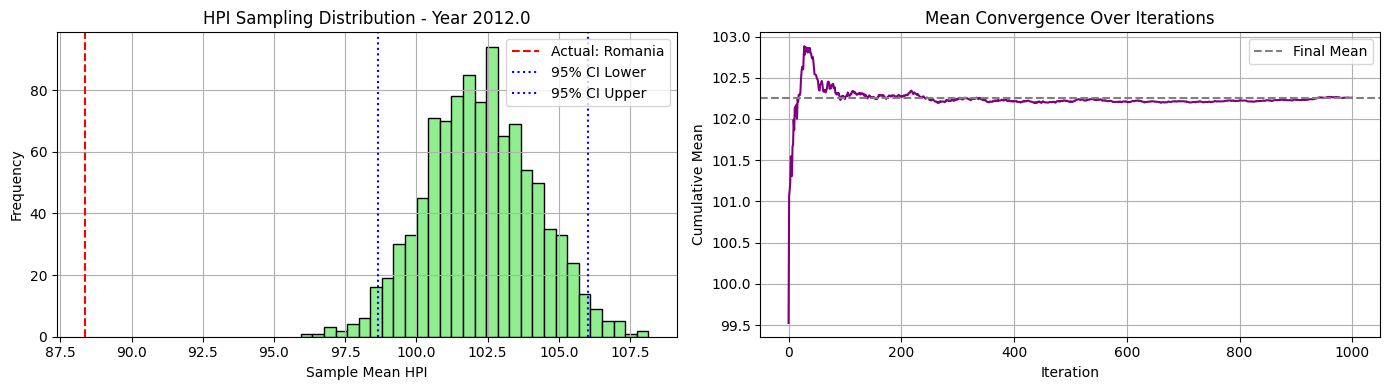


📅 Year 2013.0 - Available HPI values for sampling:
[122.59 107.59  90.65  94.7   85.58 128.77 106.87  85.58  85.58 121.5
 107.65 113.42 101.21  85.95 114.59 136.52  86.7  115.56  96.53  90.62
  85.58 118.3 ]


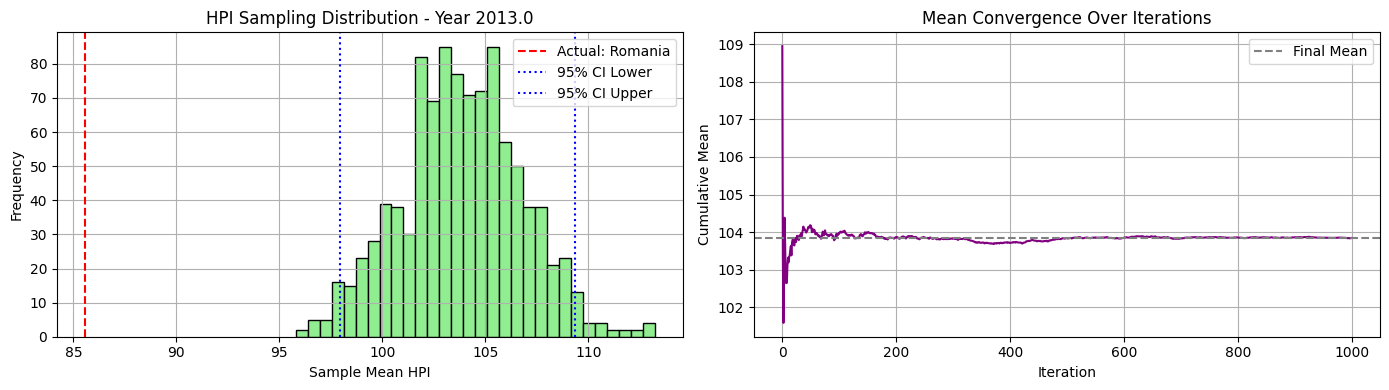


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  91.95  93.19  84.64 146.41 106.5   84.64  84.66 128.78
 114.57 118.39 103.79  86.66 122.03 151.67  90.38 112.25  97.8   84.64
  84.64 121.46]


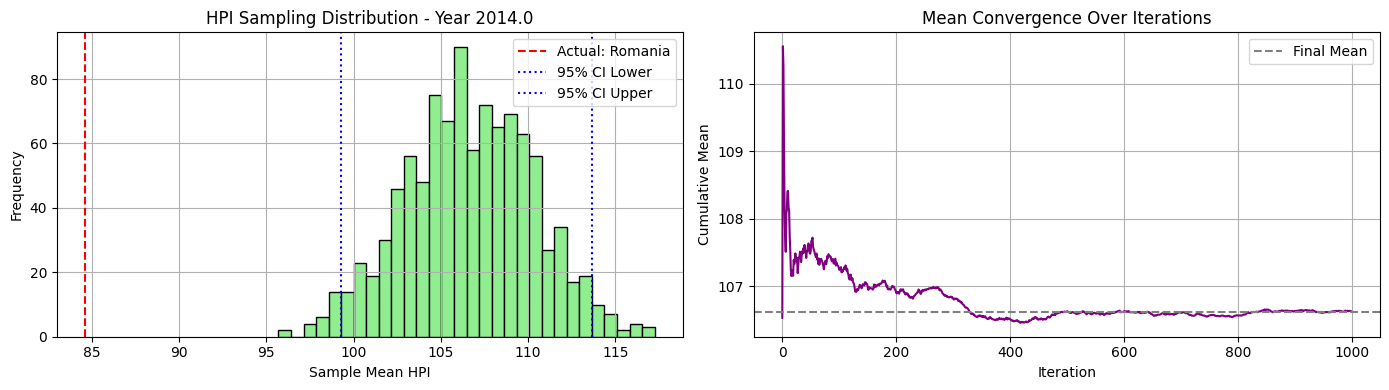


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  94.51  90.54  84.67 156.46 106.5   84.67  94.36 124.46
 118.76 124.78 109.83  89.69 137.18 162.89  93.15 107.92 103.    85.32
  84.67 124.08]


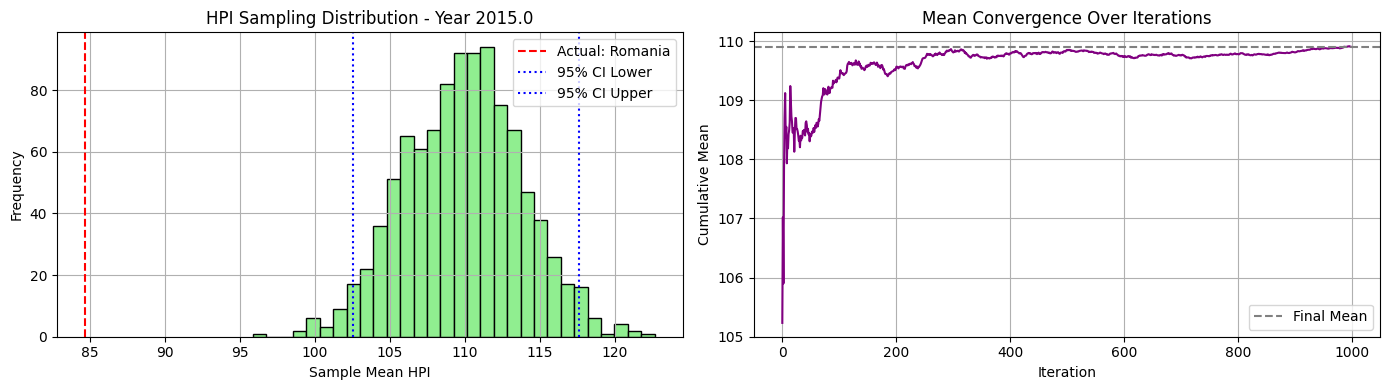


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72 101.15  91.33  88.1  163.86 107.86  88.1  101.42 135.02
 125.16 132.28 115.82  94.43 156.62 164.18  99.78 104.55 109.87  88.1
  88.1  124.32]


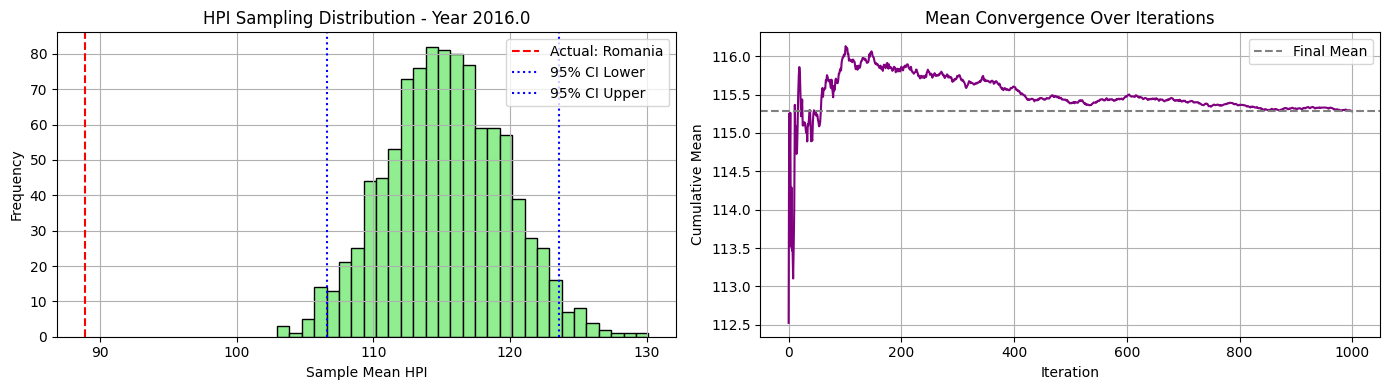


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66 109.91  94.84  88.54 172.91 109.02  88.54 112.44 146.87
 136.34 139.69 121.94 102.06 166.8  168.   108.99 103.4  116.3   95.38
  88.54 125.42]


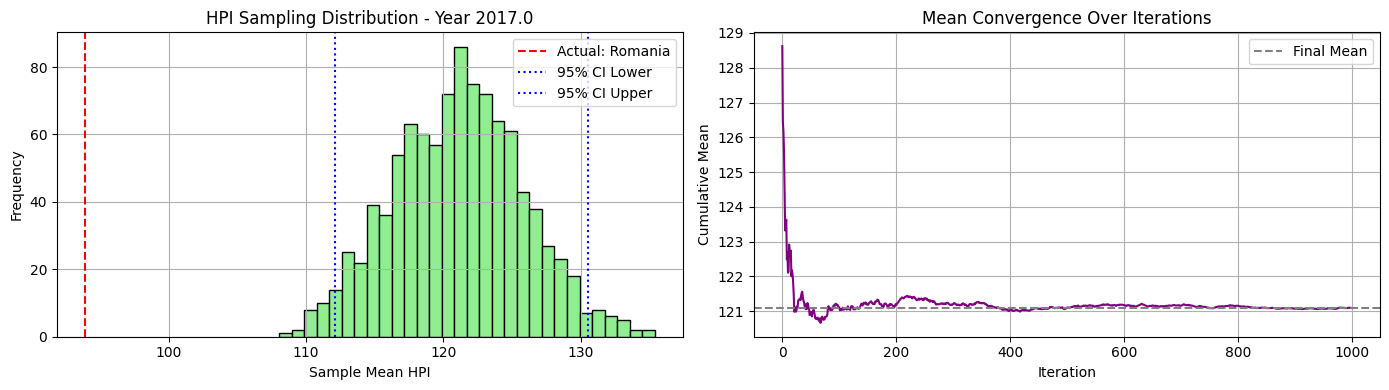


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 117.15 100.59  90.72 183.13 110.06  90.72 123.96 160.92
 146.29 149.55 129.02 111.57 172.8  168.42 120.19 111.46 124.97 103.7
  90.72 129.16]


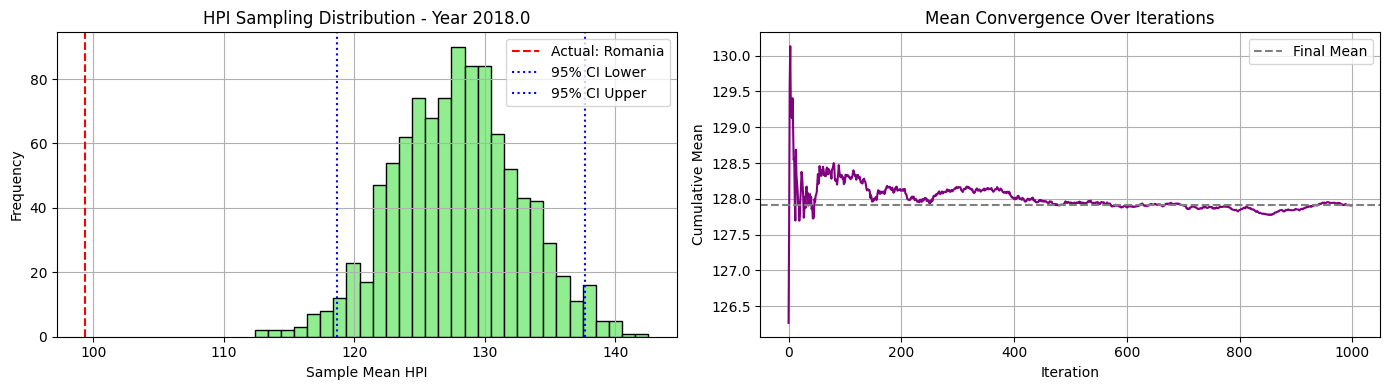


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 124.2  109.64  97.25 195.98 110.52  97.25 126.85 175.33
 156.3  164.68 136.9  119.62 178.19 172.03 132.16 113.98 136.39 110.65
  97.25 133.99]


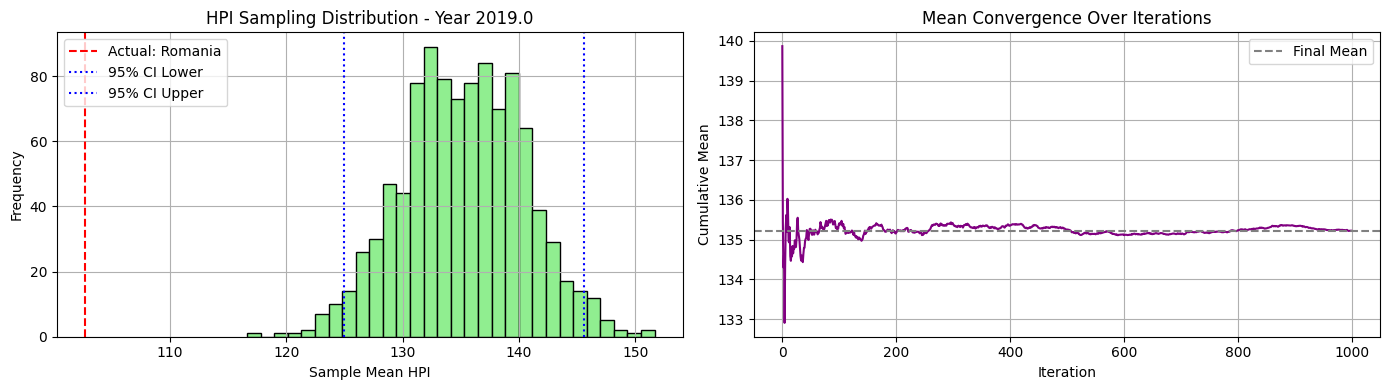


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 129.87 118.06 106.71 207.78 112.49 106.71 127.24 181.42
 167.66 188.57 141.54 129.21 196.31 173.67 143.75 115.8  149.36 115.74
 106.71 137.31]


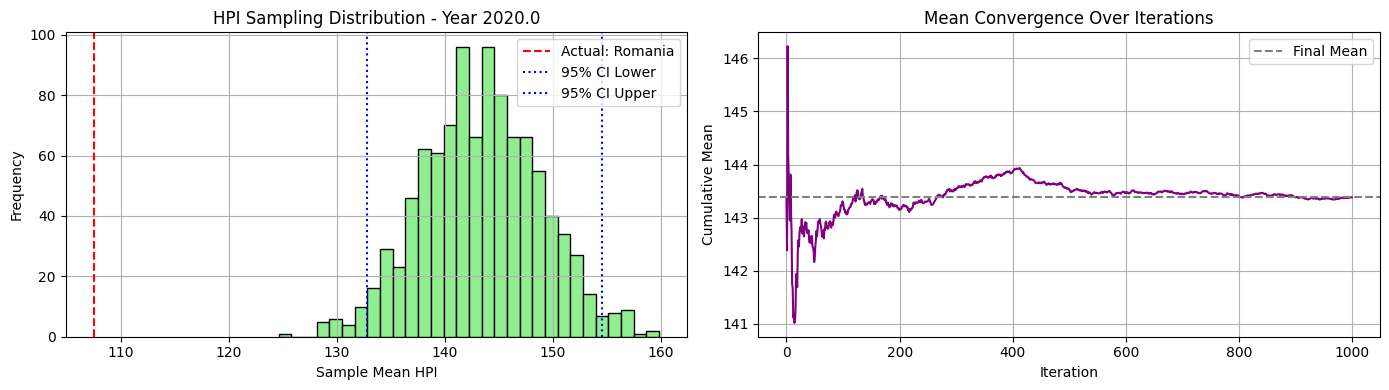


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 141.14 126.64 112.34 239.04 117.62 112.34 137.77 201.18
 194.58 214.81 148.74 147.93 248.26 173.6  157.27 125.04 158.94 129.1
 112.34 145.16]


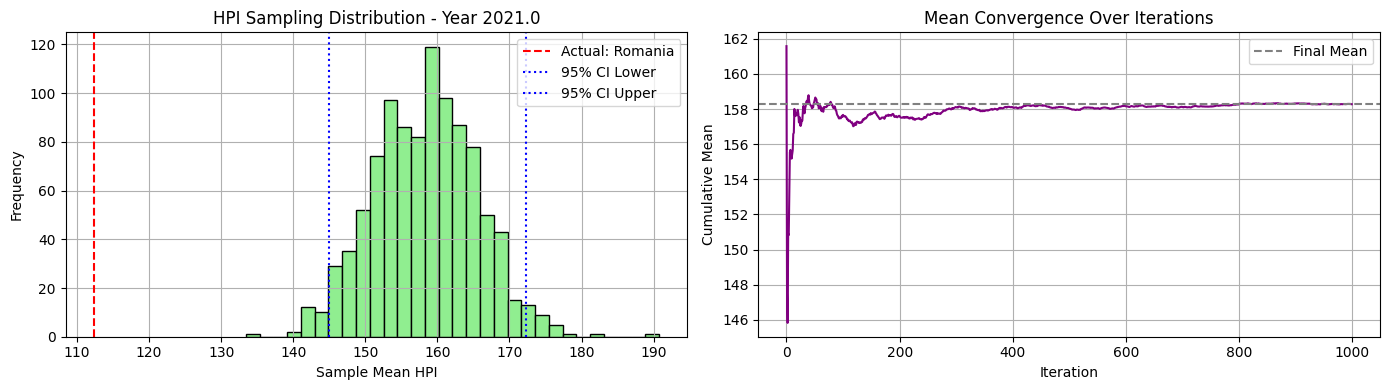


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 160.59 145.44 118.98 292.18 118.98 118.98 154.73 229.01
 231.64 235.34 158.62 167.57 249.69 172.65 177.14 137.74 180.7  148.16
 118.98 154.42]


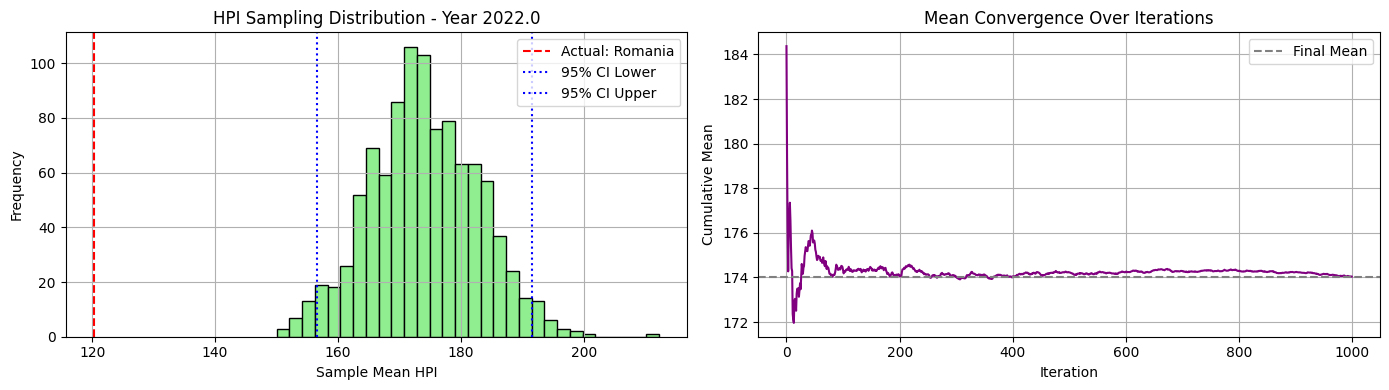


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 176.43 162.82 112.27 309.37 112.27 112.27 159.48 237.56
 254.38 214.   168.5  164.36 233.54 175.16 191.66 148.01 180.36 158.88
 112.27 157.81]


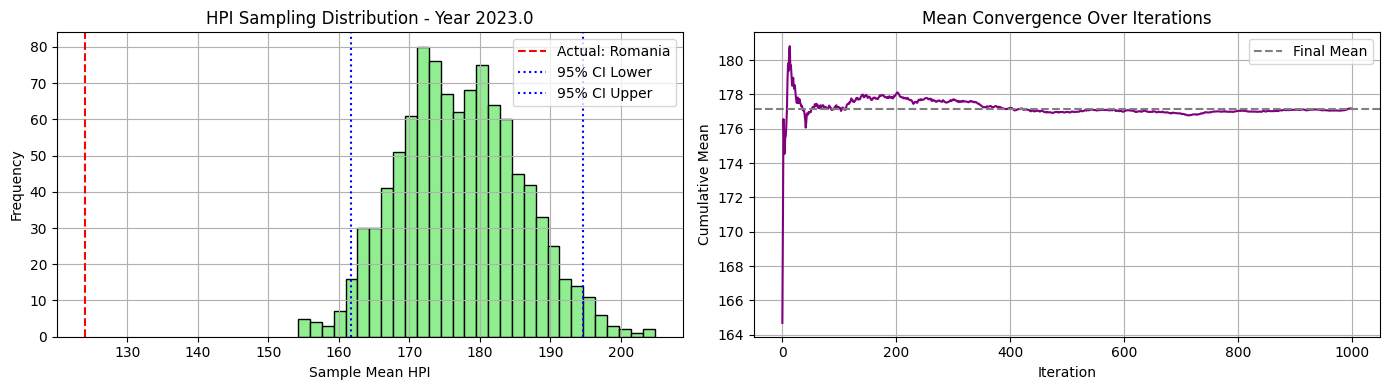


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 205.53 179.7  119.1  328.24 119.1  119.1  173.07 247.54
 279.12 202.74 179.35 177.7  233.68 175.38 209.06 155.12 187.15 170.56
 119.1  160.56]


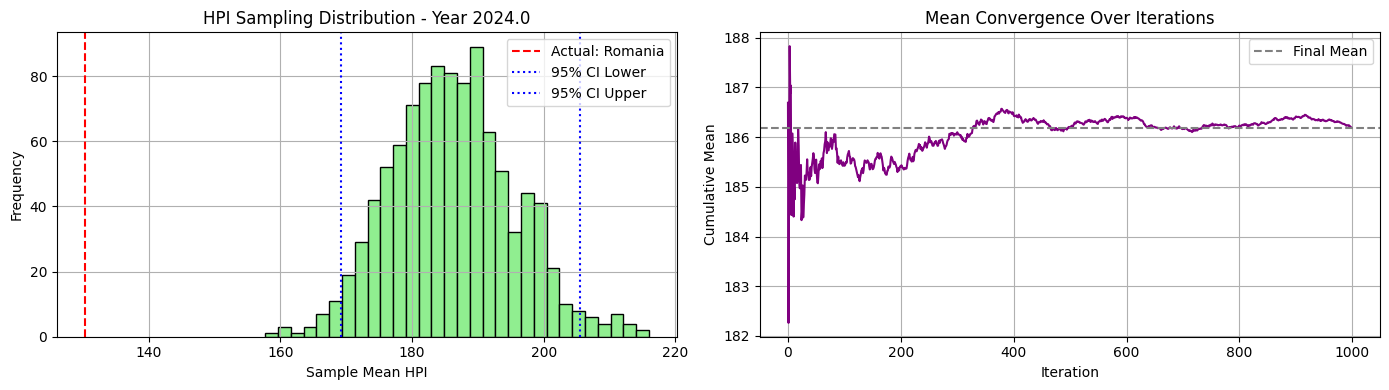

In [84]:
synthetic_c2_ni20_maxi500_01, excluded_c2_ni20_maxi500_01, actual_c2_ni20_maxi500_01 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni20_maxi500, cluster_id=1, seed=56)

🔍 Cluster 0 selected. Excluding country: Brazil
📊 Sampling from countries: ['Chile', 'Colombia', 'Czech Republic', 'Hungary', 'India', 'Japan', 'Mexico', 'Philippines', 'Russia', 'Serbia', 'South Africa', 'South Korea', 'Thailand', 'Turkey', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100.]


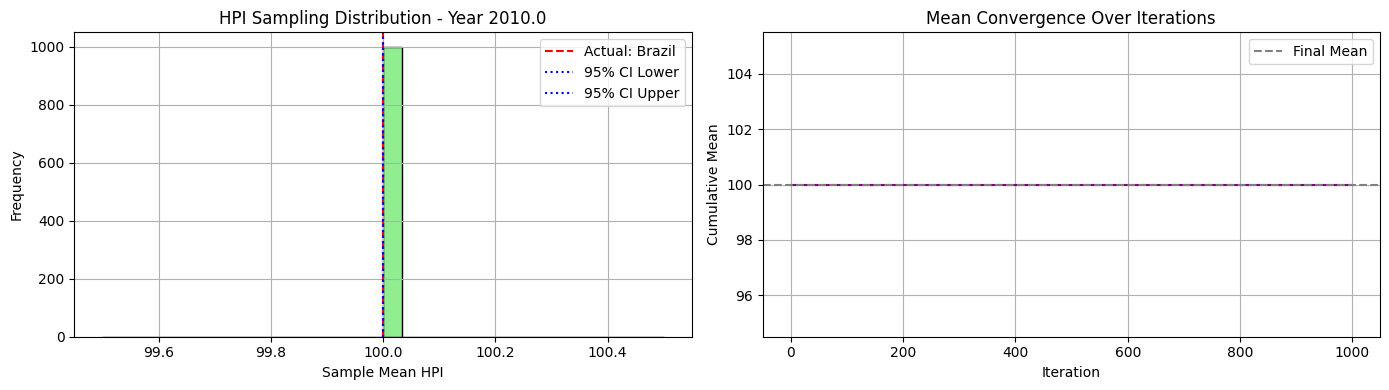


📅 Year 2011.0 - Available HPI values for sampling:
[110.52 107.89 100.02  96.56 110.52 100.07 105.8  105.57  94.49  97.62
 103.59 105.23 104.26 108.8   97.24]


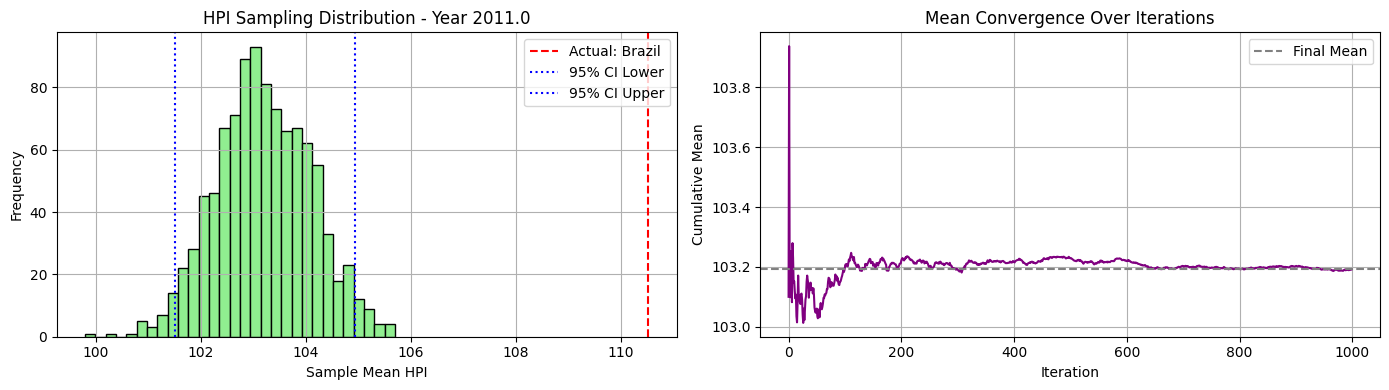


📅 Year 2012.0 - Available HPI values for sampling:
[124.02 118.79  98.56  92.98 124.02  99.19 109.17 114.94  91.1   95.68
 108.41 108.25 107.63 120.68 101.82]


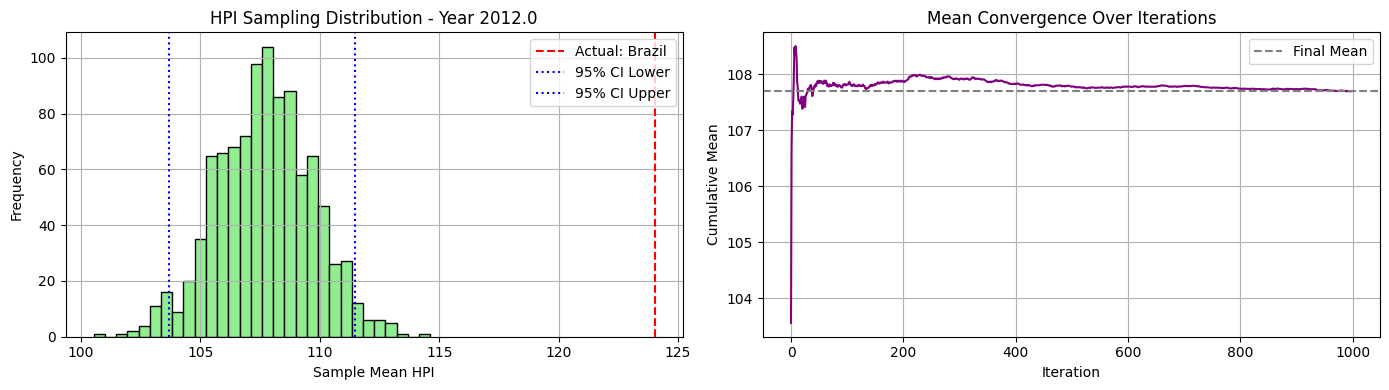


📅 Year 2013.0 - Available HPI values for sampling:
[136.52 130.06  98.58  90.58 136.52 100.81 114.75 127.86  94.32  90.62
 115.41 107.8  115.99 134.46 111.83]


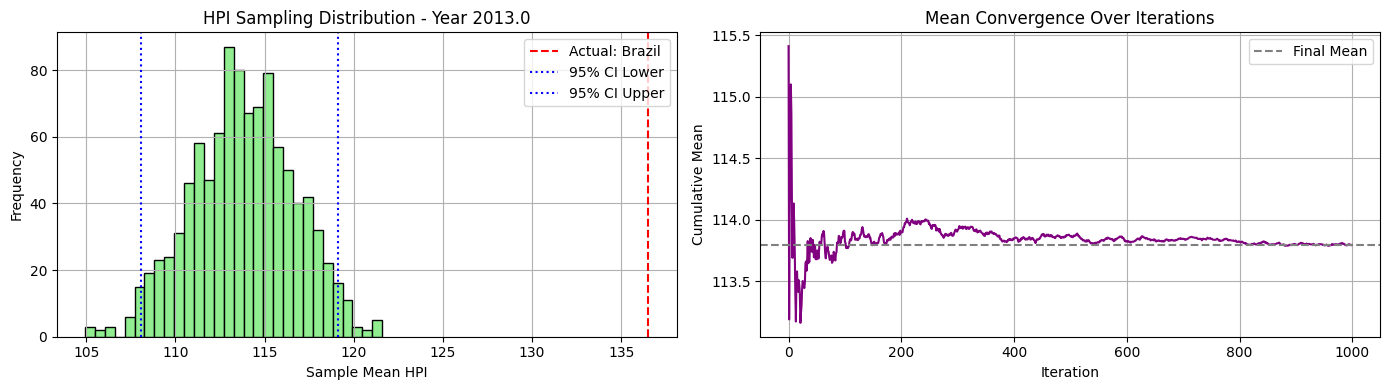


📅 Year 2014.0 - Available HPI values for sampling:
[151.67 140.75 101.    94.37 151.67 102.38 119.64 142.76  95.84  95.77
 123.99 109.43 127.07 151.25 118.88]


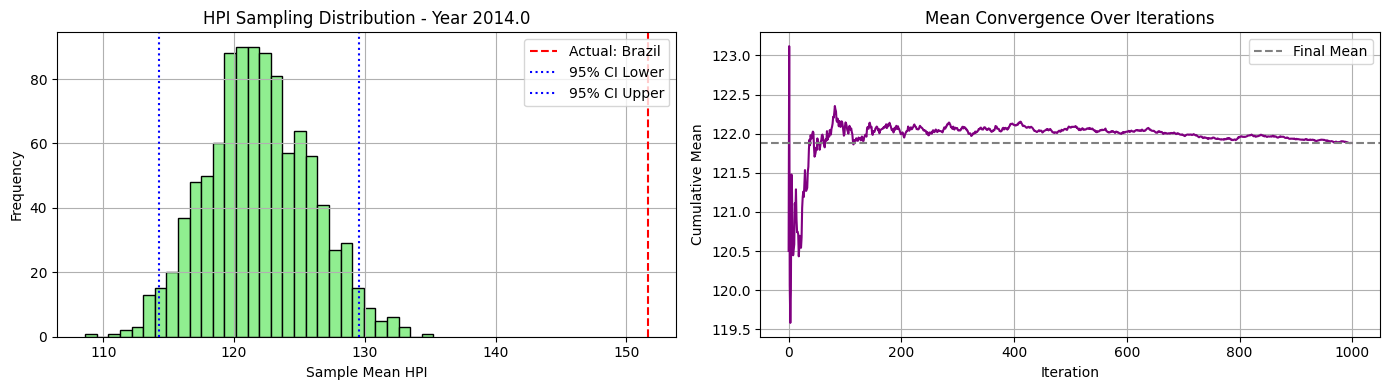


📅 Year 2015.0 - Available HPI values for sampling:
[162.89 152.93 105.01 106.75 162.89 104.86 129.39 157.04  97.    99.5
 131.8  113.08 136.   162.89 125.18]


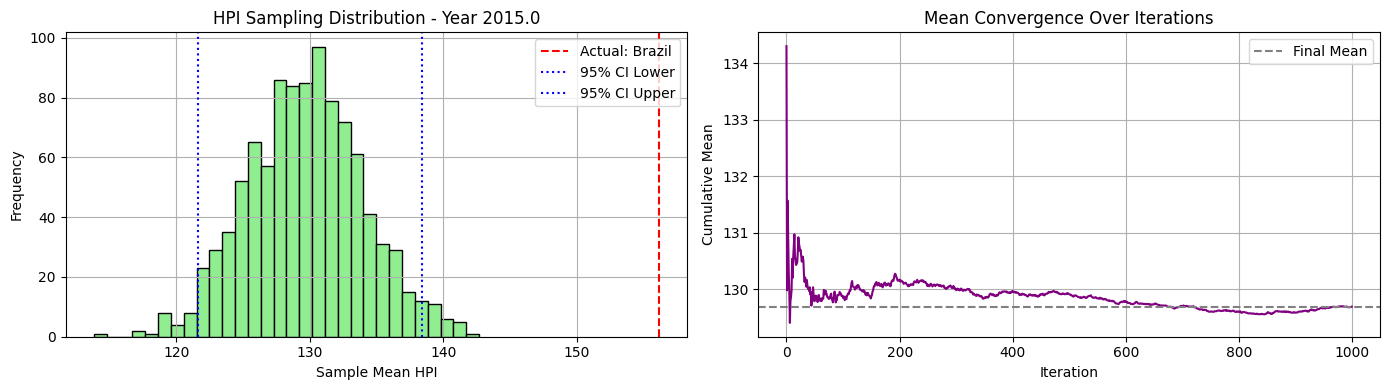


📅 Year 2016.0 - Available HPI values for sampling:
[172.75 167.48 112.52 121.03 172.75 107.18 138.82 172.75  91.86 110.62
 138.22 116.09 142.4  172.75 131.88]


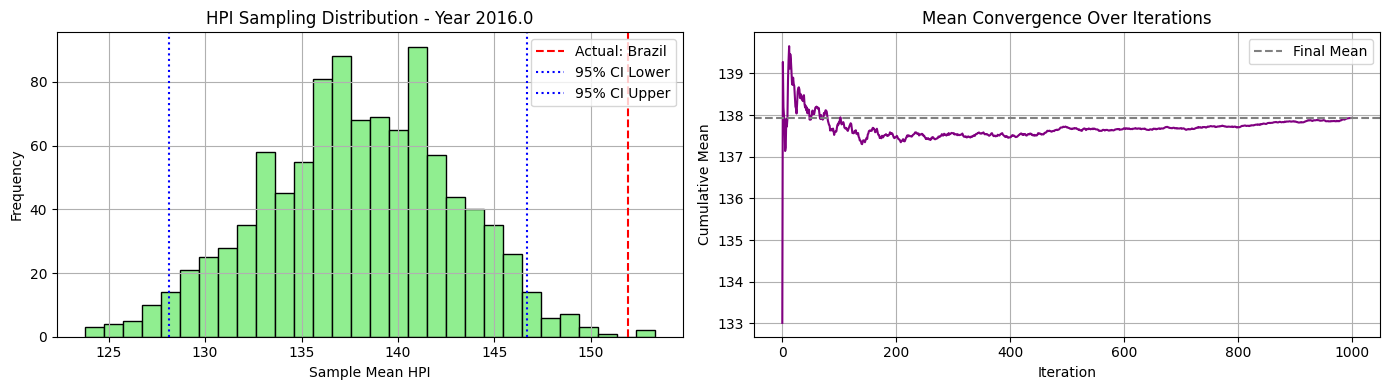


📅 Year 2017.0 - Available HPI values for sampling:
[183.99 178.56 125.7  135.84 183.99 109.91 149.69 178.82  88.54 115.3
 143.94 117.6  146.48 183.99 139.61]


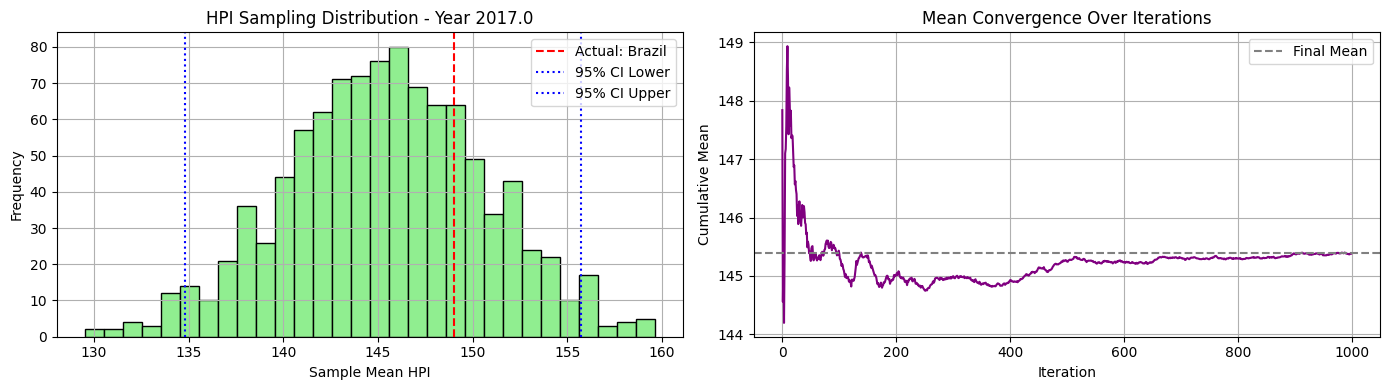


📅 Year 2018.0 - Available HPI values for sampling:
[191.85 188.24 136.52 155.3  191.85 112.04 162.97 183.82  90.72 123.06
 148.96 120.22 153.9  191.85 147.35]


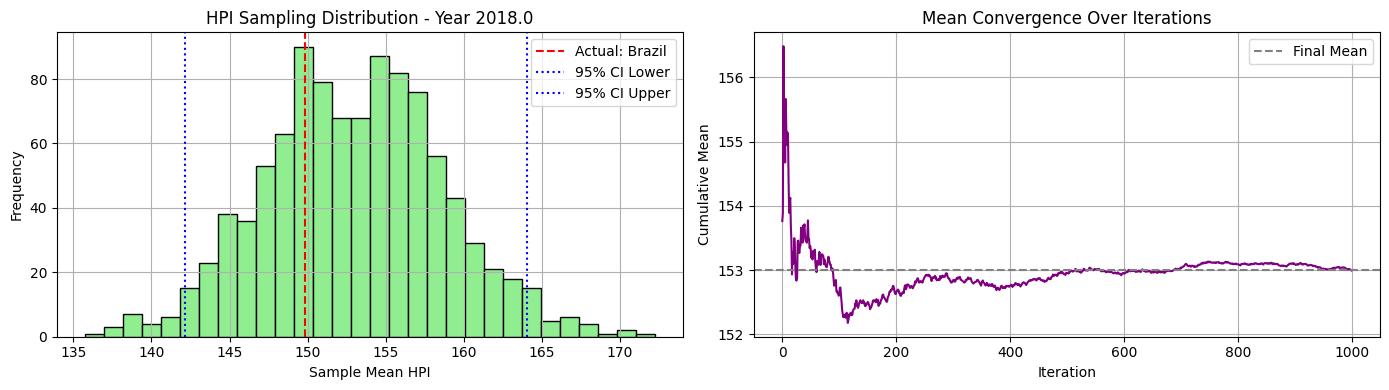


📅 Year 2019.0 - Available HPI values for sampling:
[198.37 198.37 149.02 181.64 198.37 113.84 176.92 195.26  97.25 135.77
 152.69 121.93 155.1  198.37 153.14]


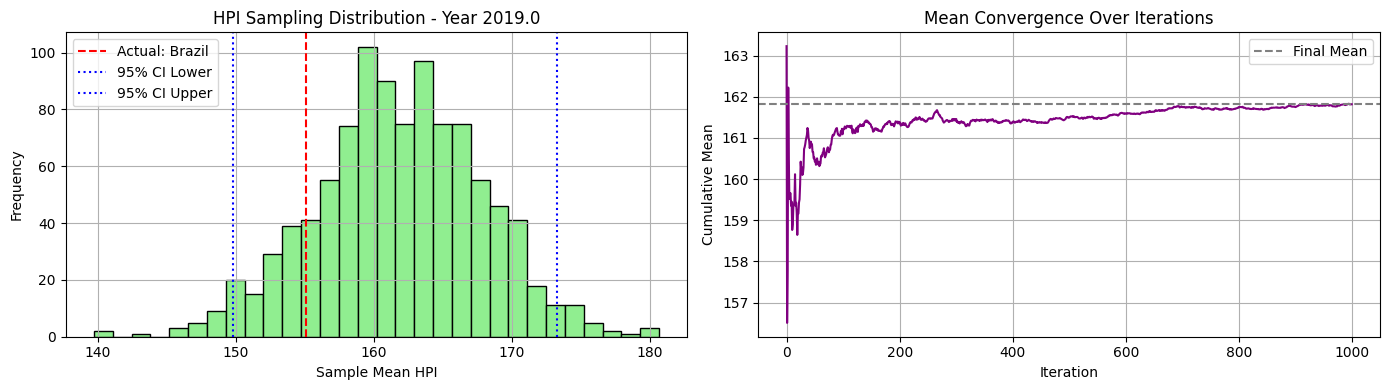


📅 Year 2020.0 - Available HPI values for sampling:
[213.74 203.12 161.56 190.63 213.74 113.93 187.18 213.74 106.71 149.28
 156.31 126.56 160.6  213.74 163.52]


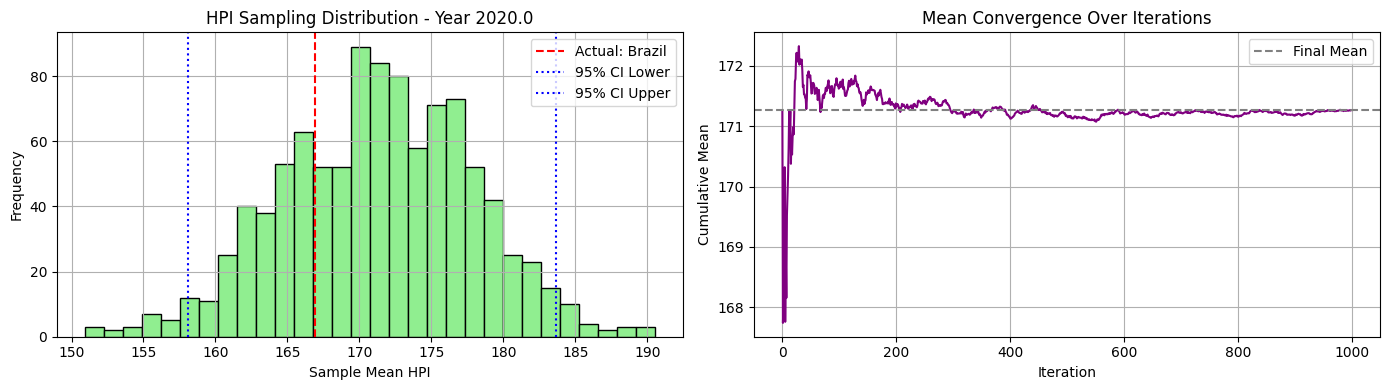


📅 Year 2021.0 - Available HPI values for sampling:
[248.26 214.9  193.46 222.1  248.26 120.7  201.94 211.74 121.41 166.04
 166.82 143.73 164.23 248.26 188.56]


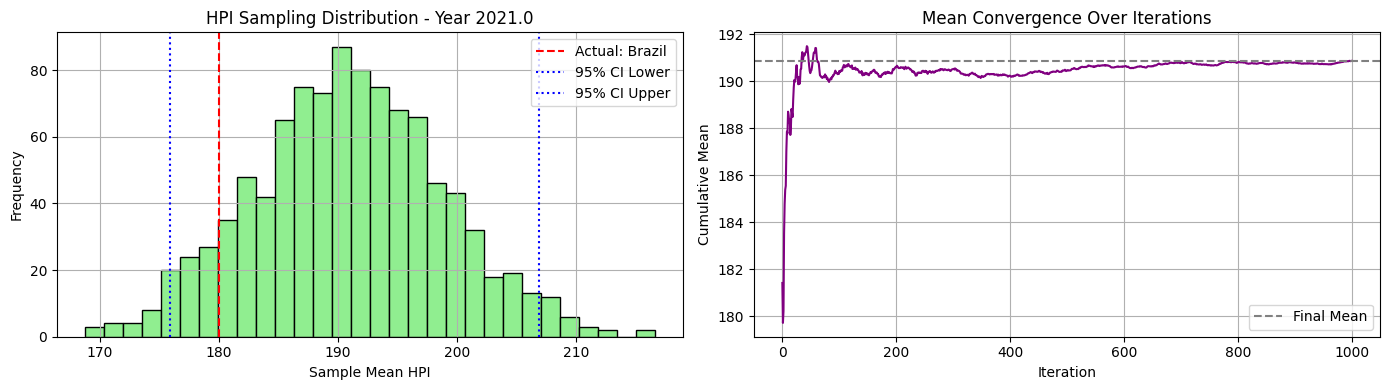


📅 Year 2022.0 - Available HPI values for sampling:
[292.18 230.   226.15 271.5  292.18 130.84 219.93 223.73 155.16 191.49
 174.03 153.22 169.16 292.18 213.  ]


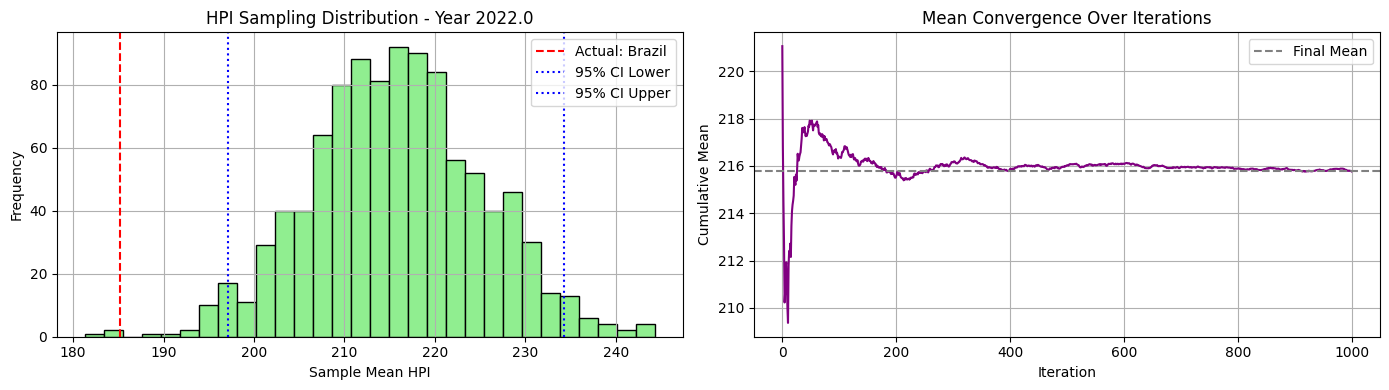


📅 Year 2023.0 - Available HPI values for sampling:
[309.37 245.75 222.4  290.98 309.37 134.8  243.89 248.04 157.88 209.99
 176.62 143.99 174.79 309.37 221.72]


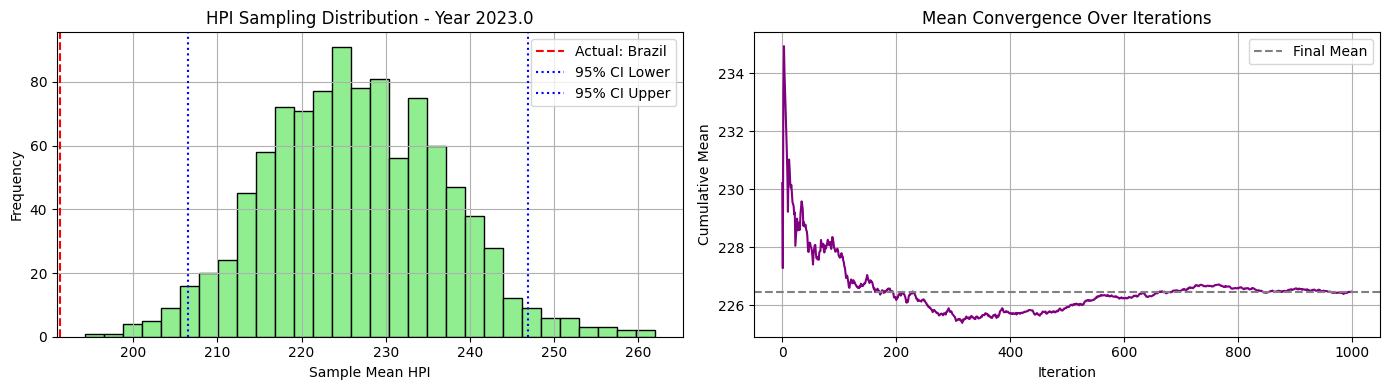


📅 Year 2024.0 - Available HPI values for sampling:
[328.24 269.02 233.42 328.1  328.24 138.61 266.38 256.03 186.66 220.7
 178.1  142.46 178.06 328.24 231.23]


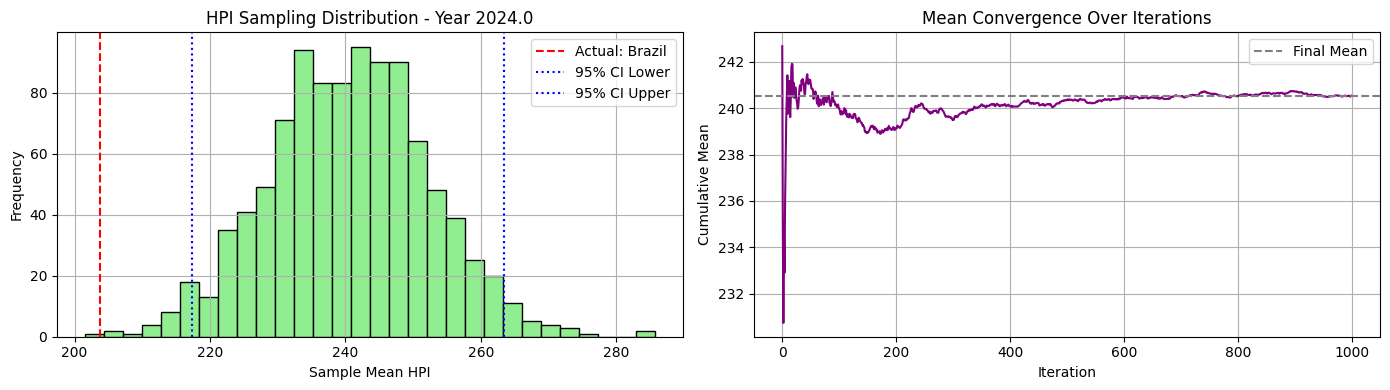

In [90]:
synthetic_c3_ni20_maxi500_00, excluded_c3_ni20_maxi500_00, actual_c3_ni20_maxi500_00 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c3_ni20_maxi500, cluster_id=0, seed=56)

🔍 Cluster 1 selected. Excluding country: Austria
📊 Sampling from countries: ['Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'New Zealand', 'Portugal', 'Slovakia', 'Slovenia']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100.]


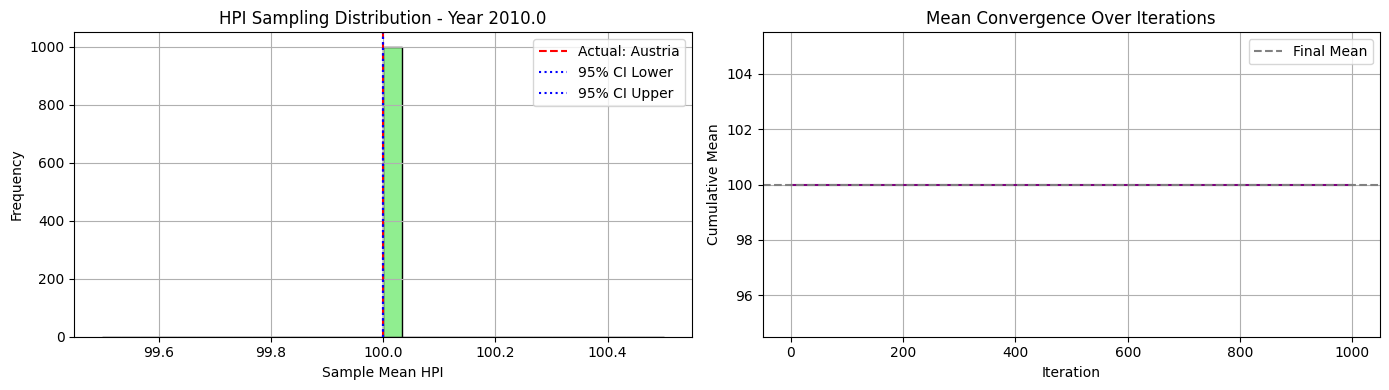


📅 Year 2011.0 - Available HPI values for sampling:
[103.58  94.49 100.16  96.68 108.47 103.17  94.53  94.49 110.42 106.6
 103.68  98.63 100.75  95.1   98.46 102.72]


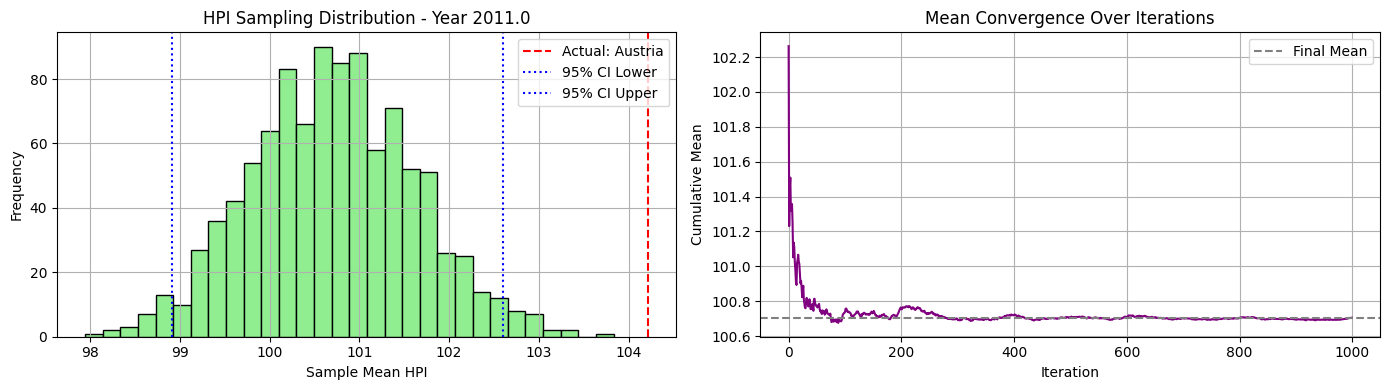


📅 Year 2012.0 - Available HPI values for sampling:
[106.02  92.69  98.62  91.54 116.34 105.64  88.37  88.37 113.71 106.36
 108.03 101.62 105.25  88.37  95.73  95.63]


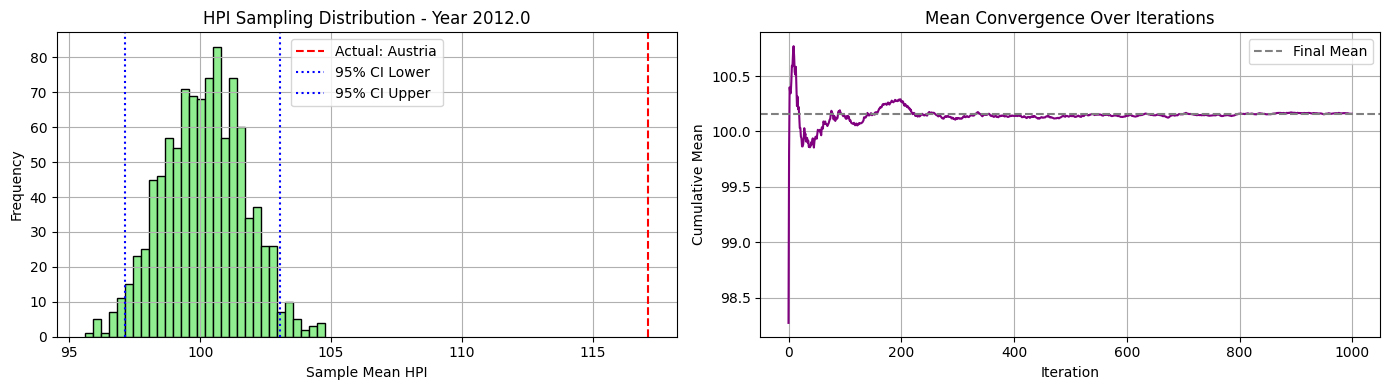


📅 Year 2013.0 - Available HPI values for sampling:
[107.59  90.65  94.7   85.58 128.77 106.87  85.58  85.58 121.5  107.65
 113.42 101.21 114.59  86.7   96.53  90.62]


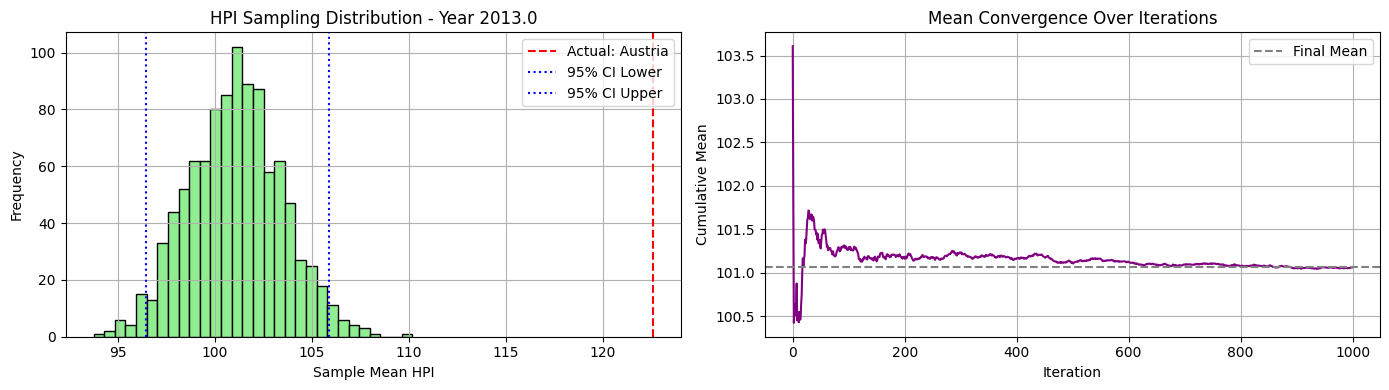


📅 Year 2014.0 - Available HPI values for sampling:
[107.22  91.95  93.19  84.64 146.41 106.5   84.64  84.66 128.78 114.57
 118.39 103.79 122.03  90.38  97.8   84.64]


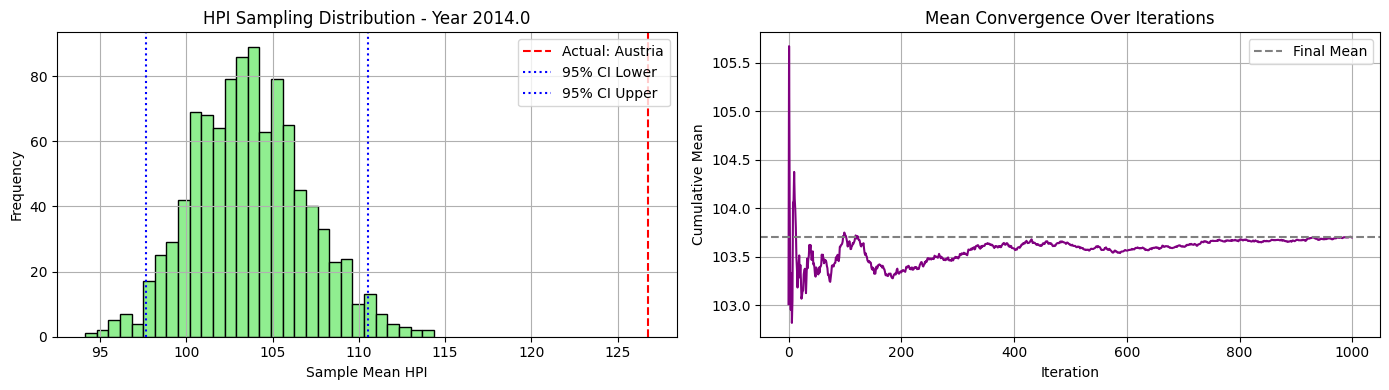


📅 Year 2015.0 - Available HPI values for sampling:
[109.17  94.51  90.54  84.67 156.46 106.5   84.67  94.36 124.46 118.76
 124.78 109.83 137.18  93.15 103.    85.32]


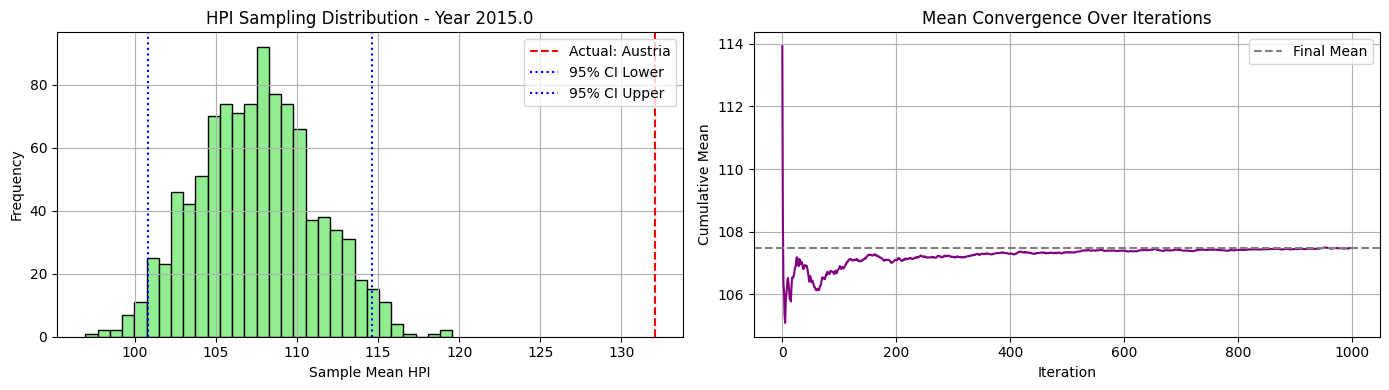


📅 Year 2016.0 - Available HPI values for sampling:
[111.72 101.15  91.33  88.1  163.86 107.86  88.1  101.42 135.02 125.16
 132.28 115.82 156.62  99.78 109.87  88.1 ]


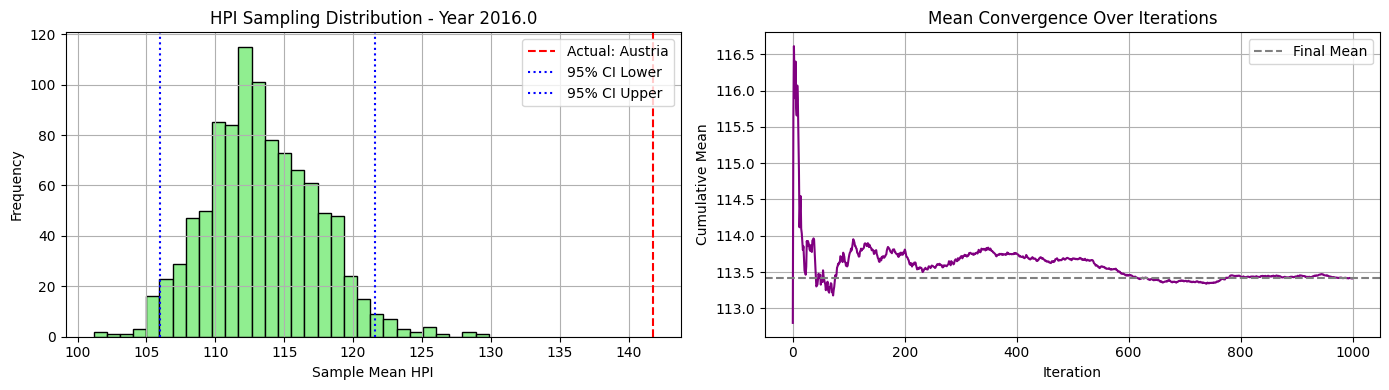


📅 Year 2017.0 - Available HPI values for sampling:
[115.66 109.91  94.84  88.54 172.91 109.02  88.54 112.44 146.87 136.34
 139.69 121.94 166.8  108.99 116.3   95.38]


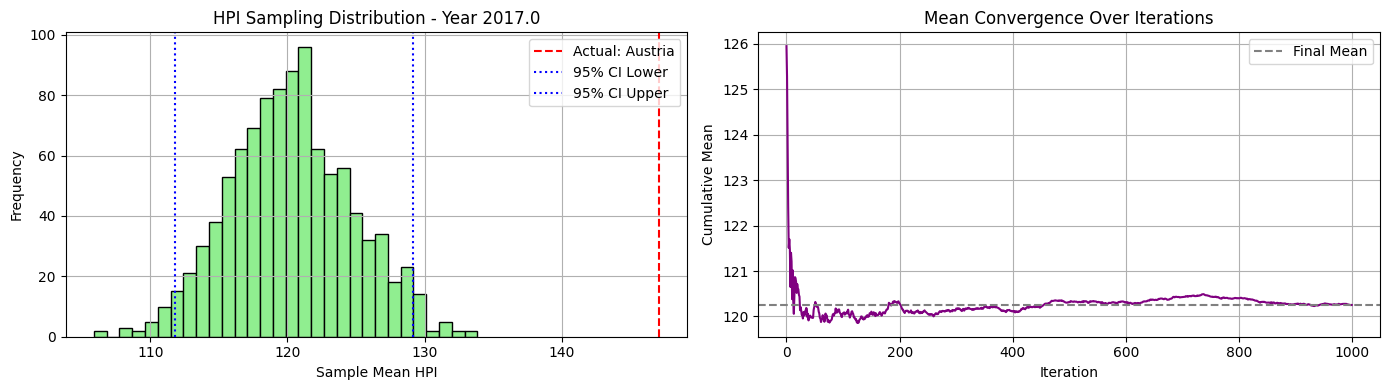


📅 Year 2018.0 - Available HPI values for sampling:
[119.16 117.15 100.59  90.72 183.13 110.06  90.72 123.96 160.92 146.29
 149.55 129.02 172.8  120.19 124.97 103.7 ]


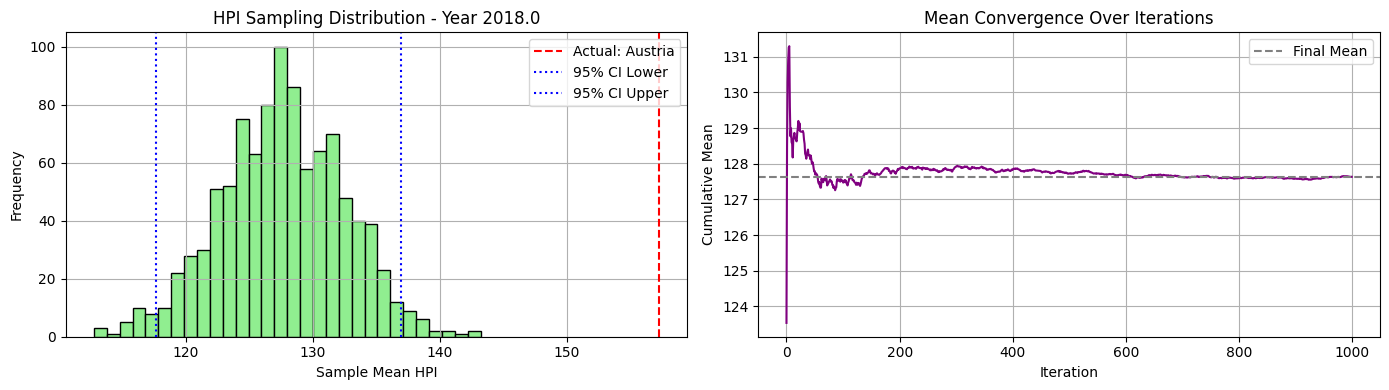


📅 Year 2019.0 - Available HPI values for sampling:
[123.62 124.2  109.64  97.25 195.98 110.52  97.25 126.85 175.33 156.3
 164.68 136.9  178.19 132.16 136.39 110.65]


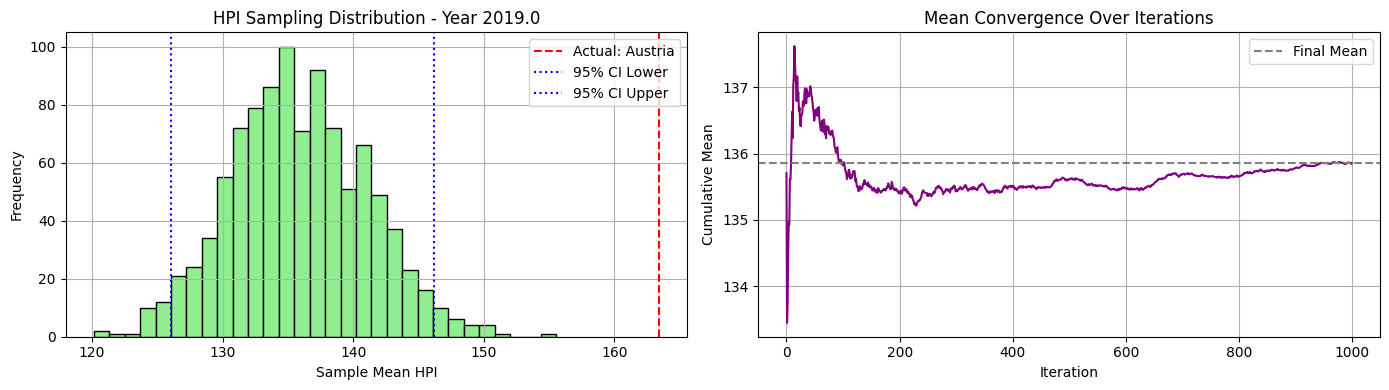


📅 Year 2020.0 - Available HPI values for sampling:
[128.92 129.87 118.06 106.71 207.78 112.49 106.71 127.24 181.42 167.66
 188.57 141.54 196.31 143.75 149.36 115.74]


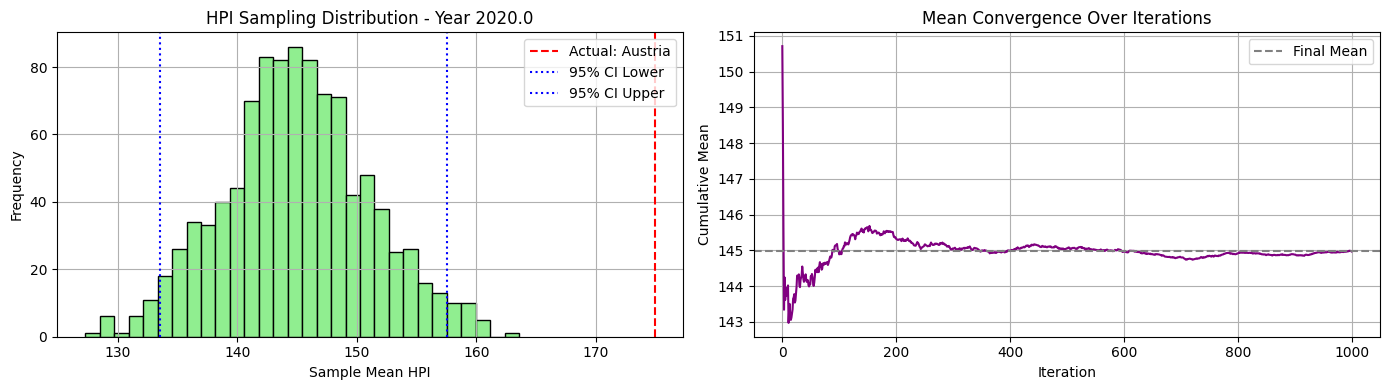


📅 Year 2021.0 - Available HPI values for sampling:
[137.52 141.14 126.64 112.34 239.04 117.62 112.34 137.77 201.18 194.58
 214.81 148.74 248.26 157.27 158.94 129.1 ]


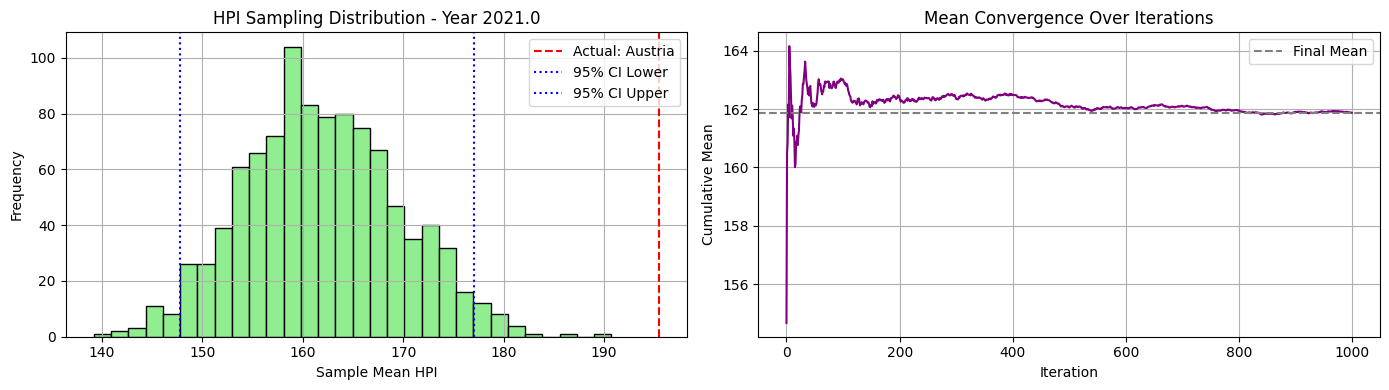


📅 Year 2022.0 - Available HPI values for sampling:
[145.12 160.59 145.44 118.98 292.18 118.98 118.98 154.73 229.01 231.64
 235.34 158.62 249.69 177.14 180.7  148.16]


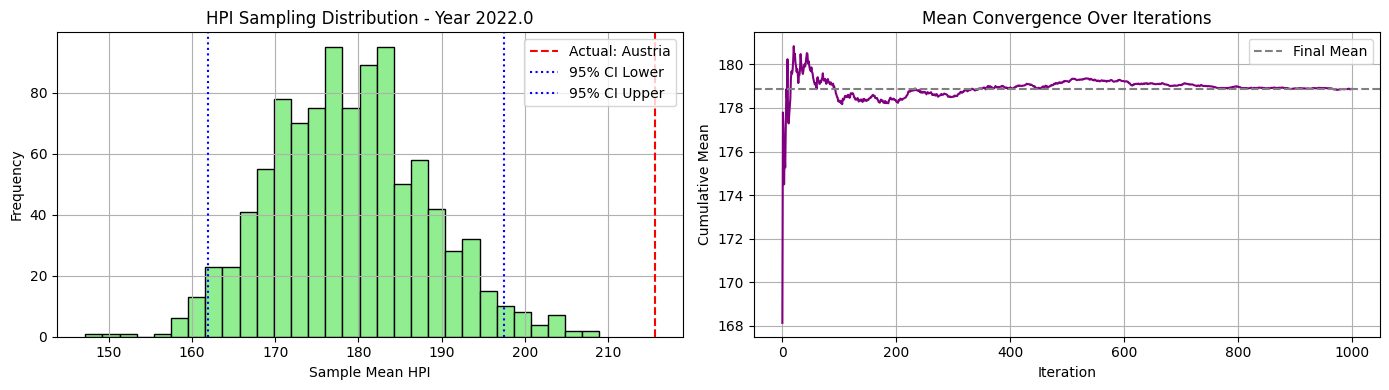


📅 Year 2023.0 - Available HPI values for sampling:
[148.52 176.43 162.82 112.27 309.37 112.27 112.27 159.48 237.56 254.38
 214.   168.5  233.54 191.66 180.36 158.88]


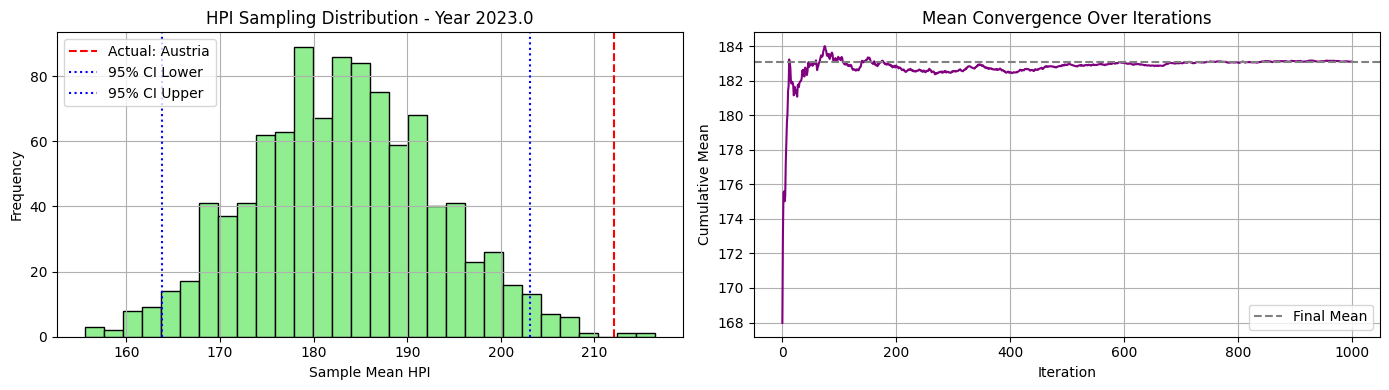


📅 Year 2024.0 - Available HPI values for sampling:
[153.31 205.53 179.7  119.1  328.24 119.1  119.1  173.07 247.54 279.12
 202.74 179.35 233.68 209.06 187.15 170.56]


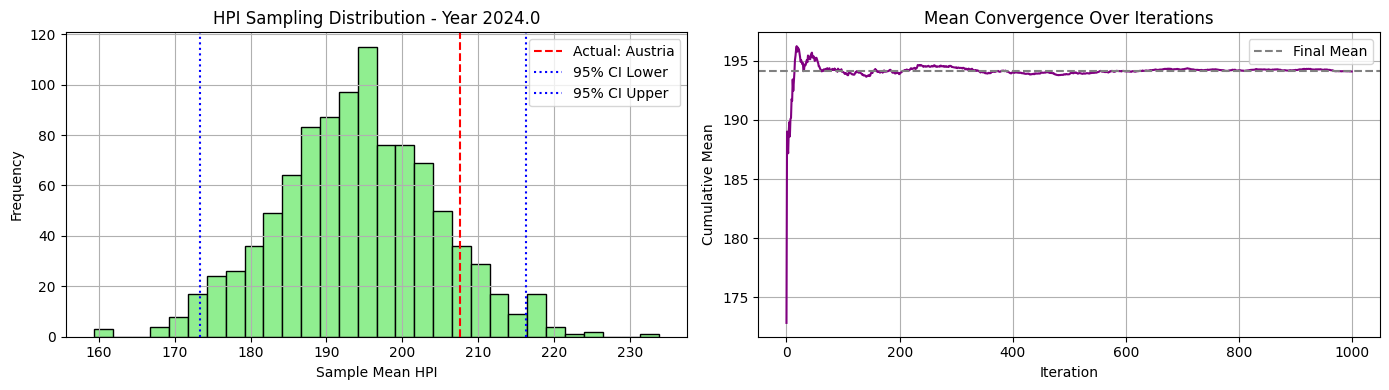

In [91]:
synthetic_c3_ni20_maxi500_01, excluded_c3_ni20_maxi500_01, actual_c3_ni20_maxi500_01 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c3_ni20_maxi500, cluster_id=1, seed=56)

🔍 Cluster 2 selected. Excluding country: Switzerland
📊 Sampling from countries: ['Australia', 'Canada', 'Denmark', 'France', 'Germany', 'Iceland', 'Israel', 'Italy', 'Malaysia', 'Netherlands', 'Norway', 'Peru', 'Poland', 'Romania', 'Singapore', 'Spain', 'Sweden', 'United Kingdom']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100.]


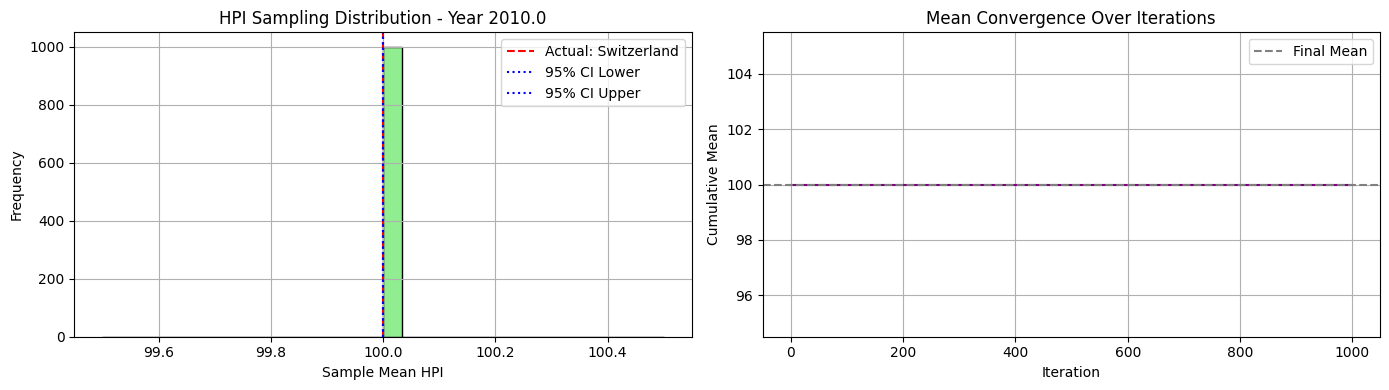


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 105.75  98.29 105.69 102.42 105.5  110.52 101.36 109.83  98.02
 108.01 110.52 100.08  94.49 109.46  94.49 102.58  98.54]


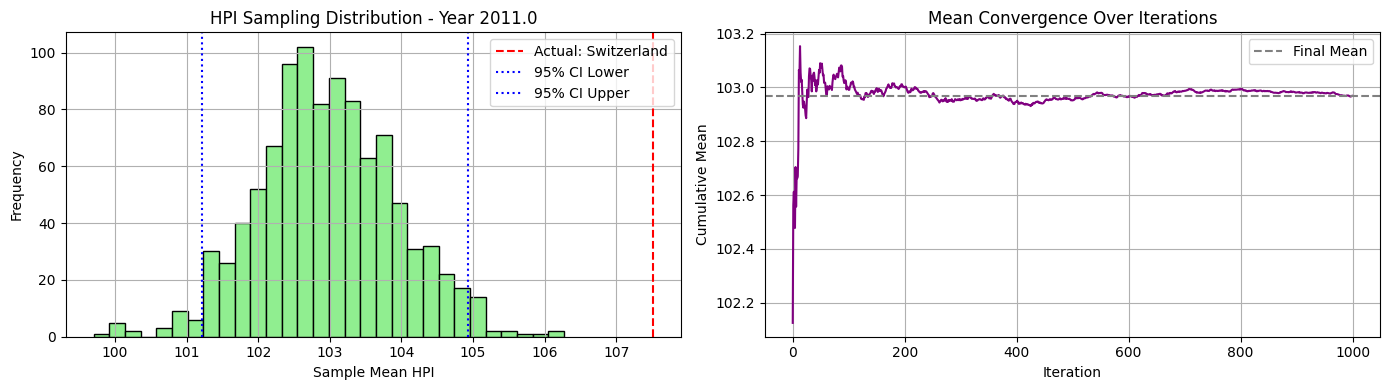


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 110.62  95.67 105.11 105.48 112.38 114.1   98.77 124.02  91.44
 115.34 124.02  96.58  88.37 112.02  88.37 103.86  98.92]


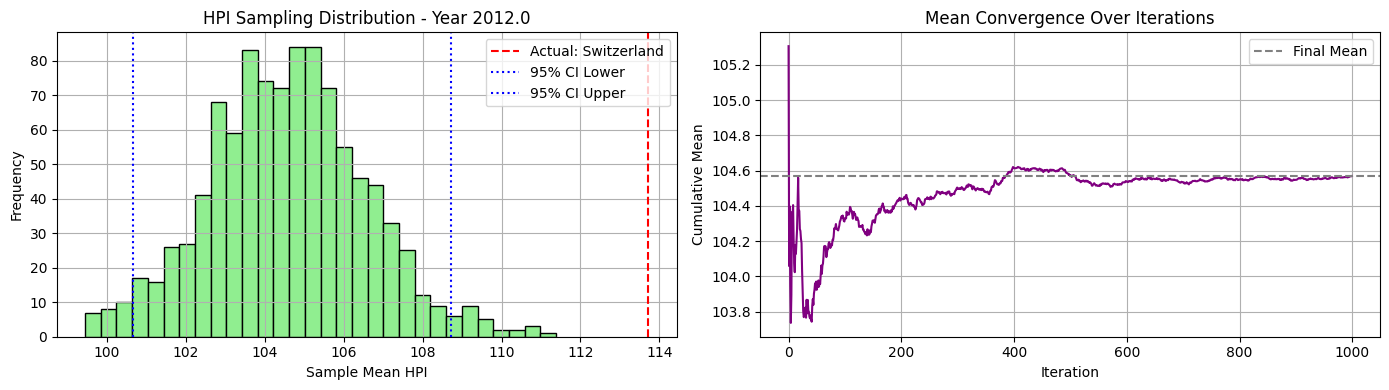


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 112.76  99.37 103.13 108.68 119.18 124.45  92.38 136.52  85.95
 119.98 136.52  92.35  85.58 115.56  85.58 109.22 101.46]


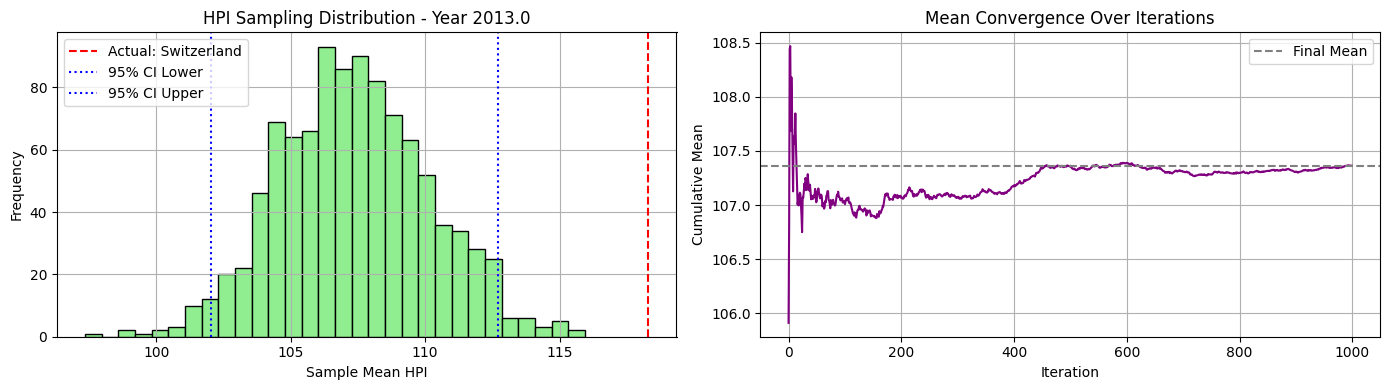


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 118.86 103.12 101.58 111.85 128.94 132.36  88.02 151.67  86.66
 123.24 151.67  93.27  84.64 112.25  84.64 119.52 109.6 ]


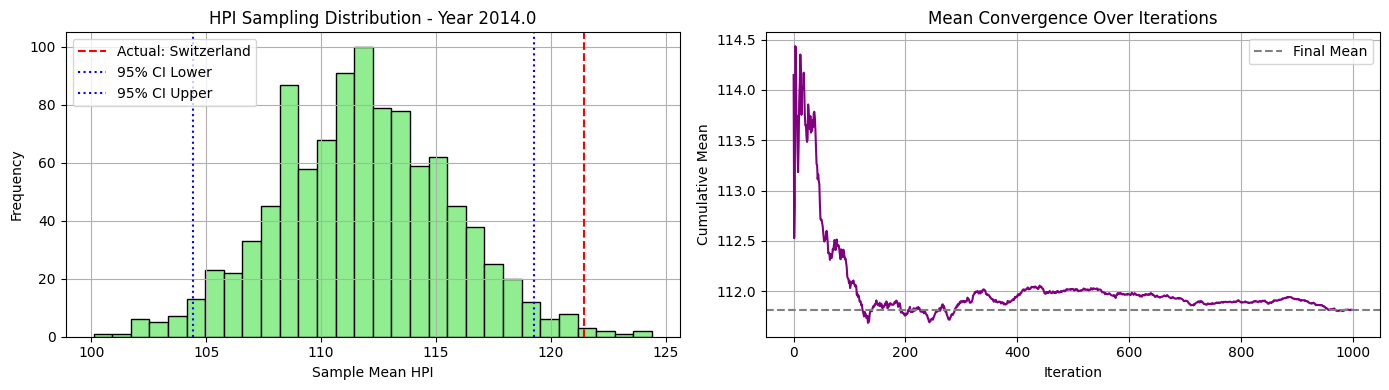


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 128.43 110.29 100.22 117.12 139.74 140.12  84.67 162.89  89.69
 130.76 162.89  94.69  84.67 107.92  84.67 135.2  116.12]


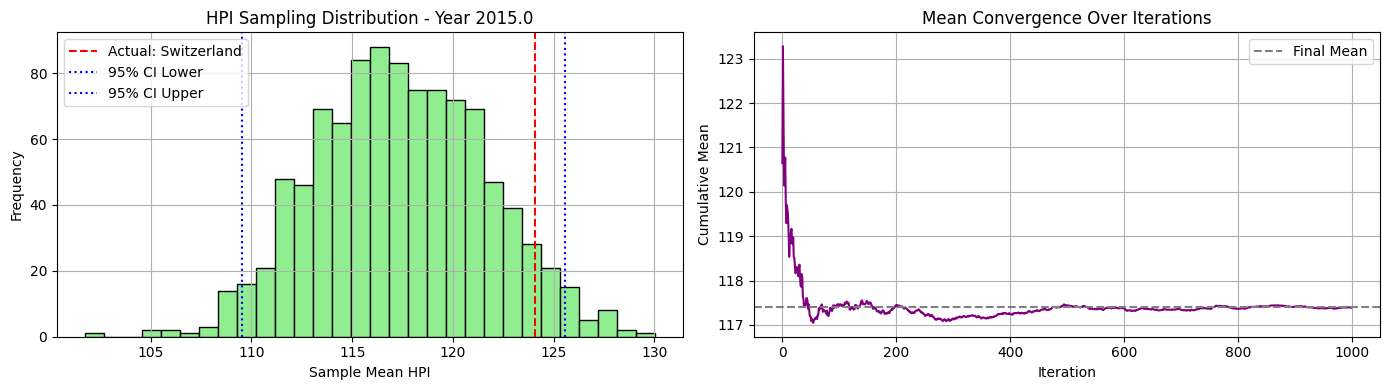


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 148.66 115.5  101.25 125.93 154.59 150.56  88.1  172.75  94.43
 139.95 164.18  96.44  88.91 104.55  88.1  146.34 124.27]


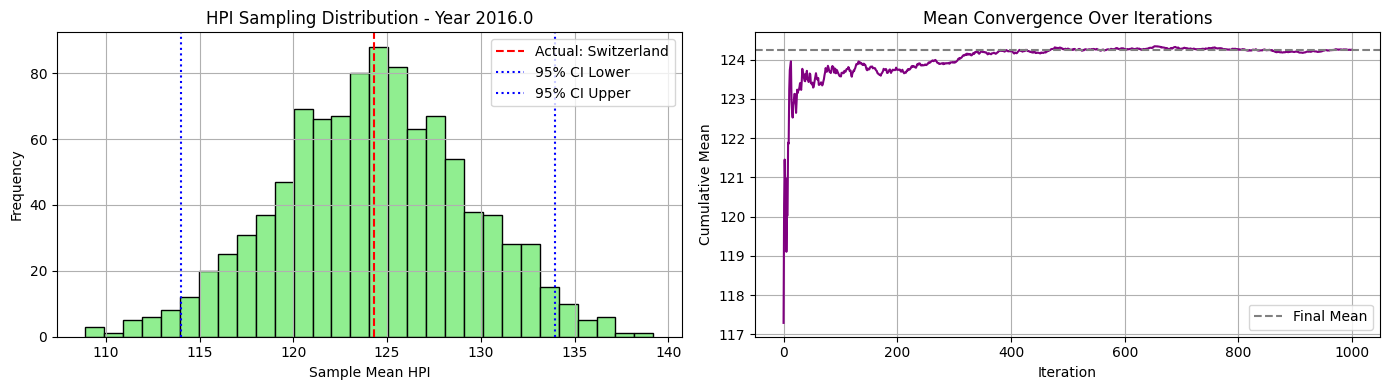


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 172.3  120.63 104.46 133.62 183.99 156.44  88.54 183.99 102.06
 146.91 168.   100.16  93.93 103.4   88.54 156.06 129.93]


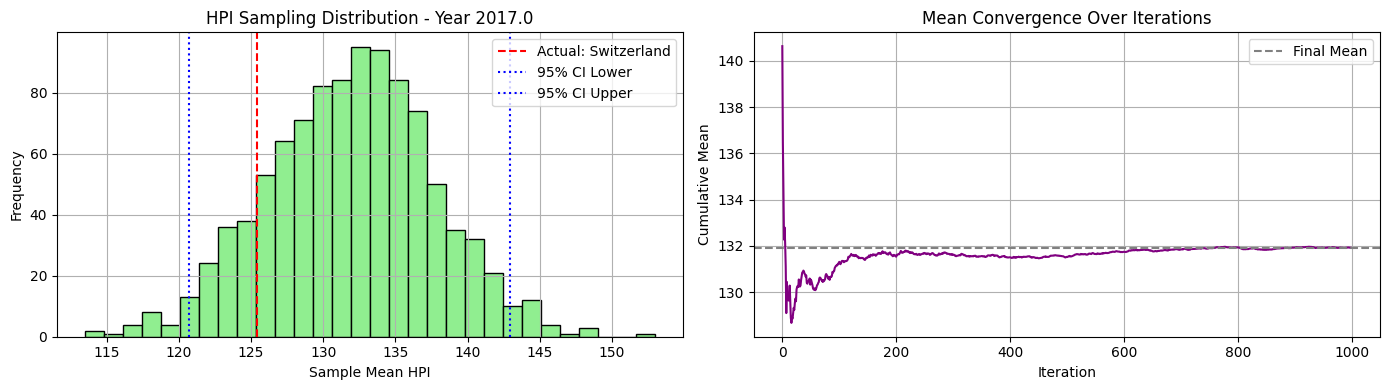


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  178.24 126.31 107.52 142.52 191.85 155.14  90.72 191.85 111.57
 149.04 168.42 106.75  99.37 111.46  90.72 154.6  134.04]


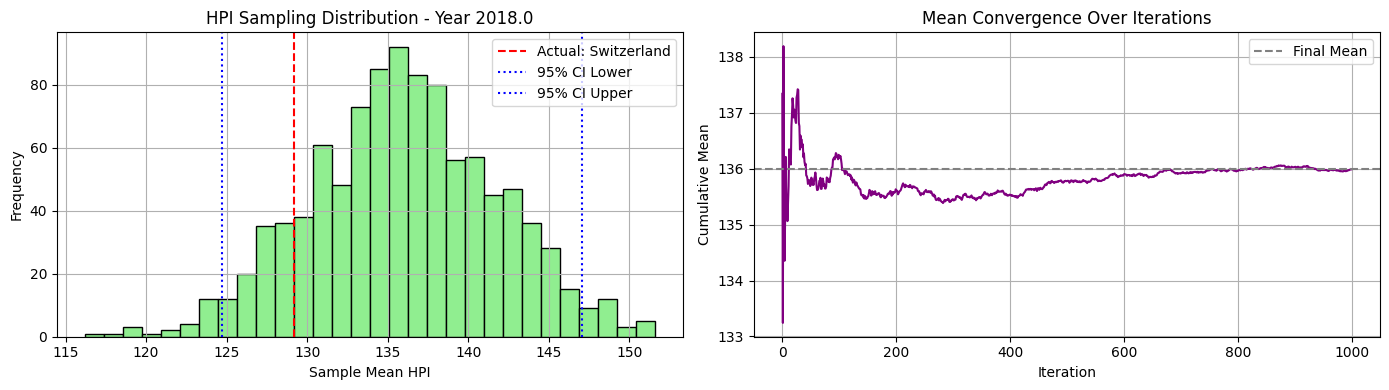


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 179.4  129.62 111.1  150.75 198.37 158.06  97.25 196.06 119.62
 152.73 172.03 116.01 102.72 113.98  97.25 158.44 135.37]


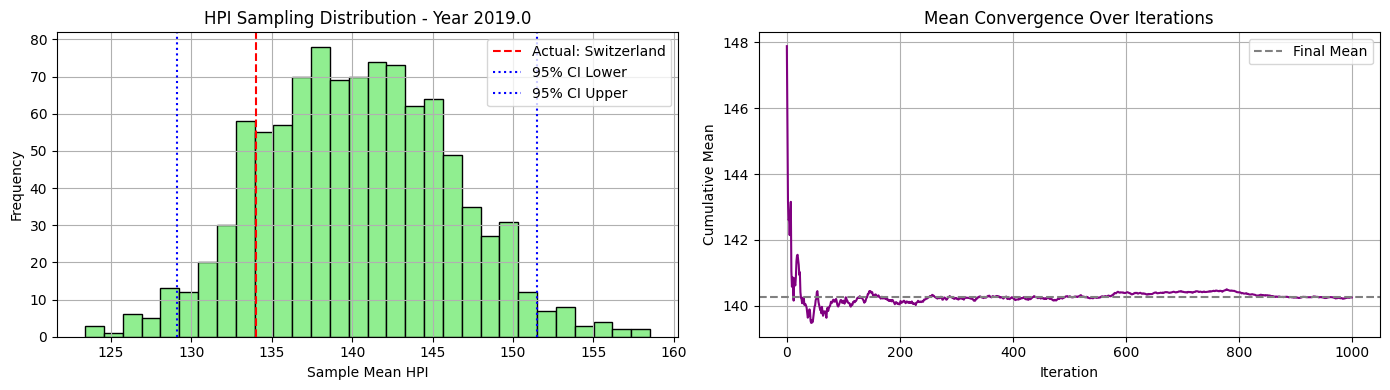


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 190.73 136.24 116.89 162.48 213.74 162.9  106.71 198.37 129.21
 159.24 173.67 128.18 107.53 115.8  106.71 165.09 139.24]


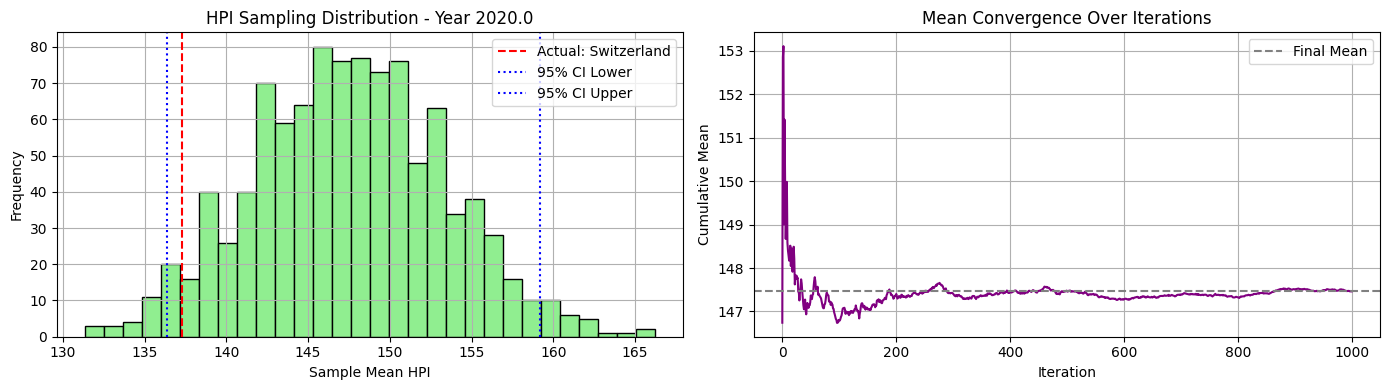


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 214.88 152.2  124.38 181.28 248.26 176.65 112.34 200.69 147.93
 175.91 173.6  139.92 112.34 125.04 112.34 181.79 150.58]


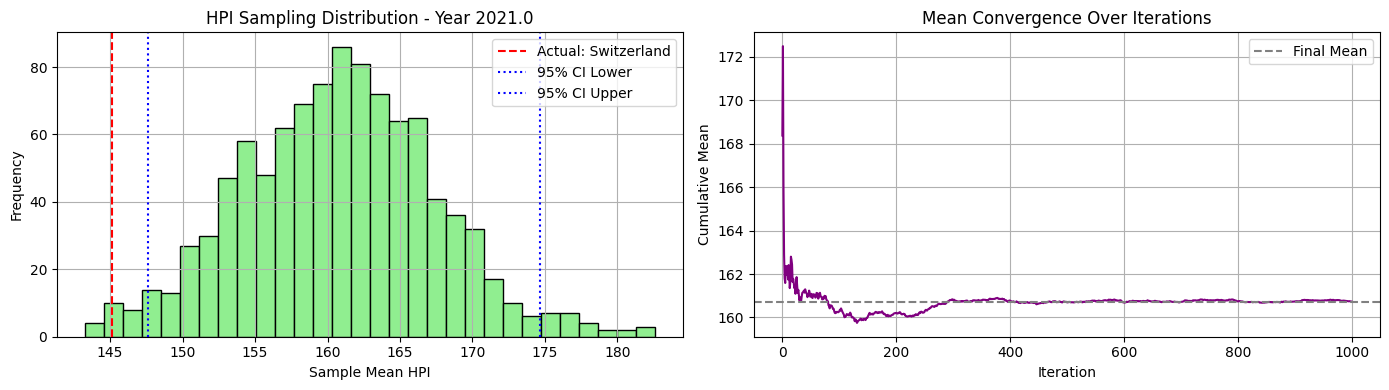


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 235.32 151.49 132.1  190.42 292.18 207.16 118.98 207.75 167.57
 185.13 172.65 156.43 120.29 137.74 118.98 188.27 164.55]


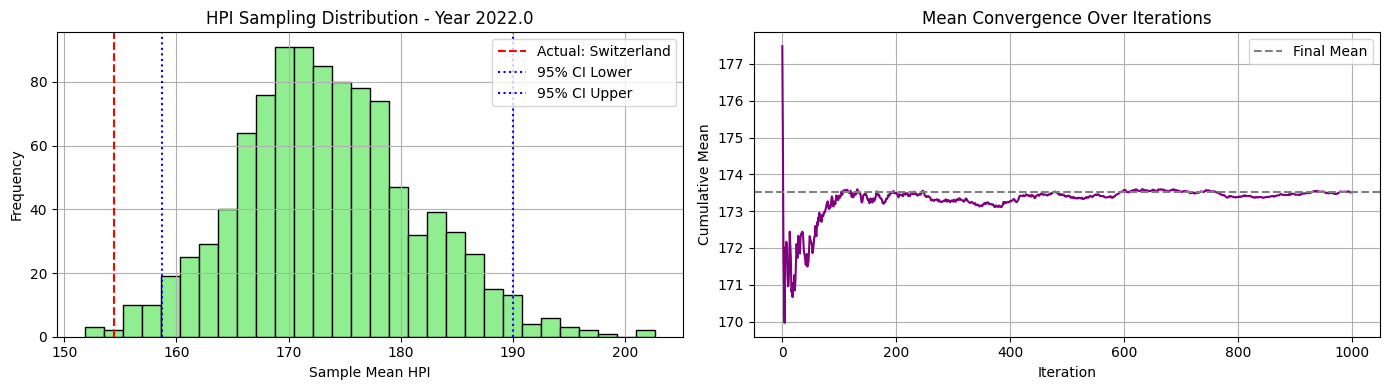


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 221.05 151.24 131.52 174.25 309.37 214.23 112.27 216.19 164.36
 184.12 175.16 170.23 124.06 148.01 112.27 178.36 165.  ]


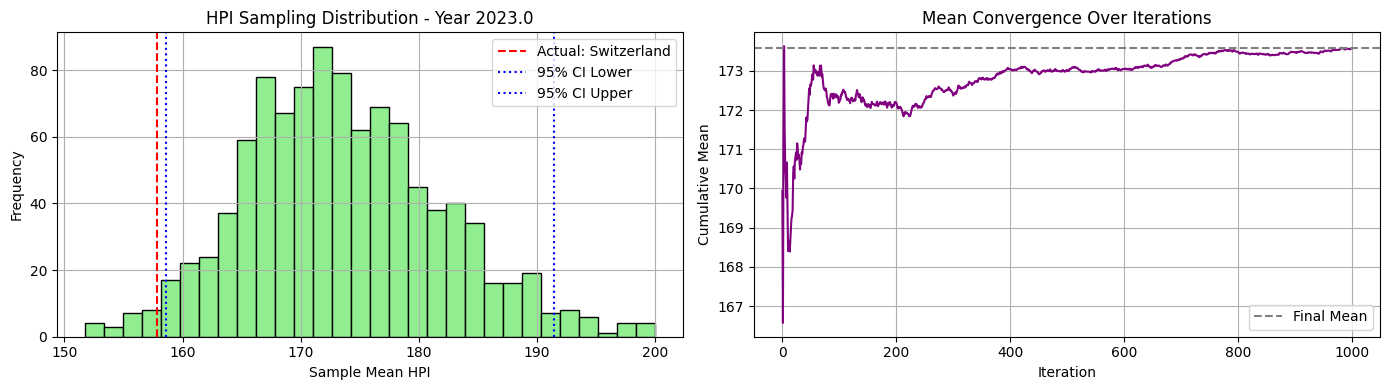


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 217.35 156.73 126.68 171.5  328.24 224.54 119.1  225.06 177.7
 189.05 175.38 195.72 130.34 155.12 119.1  178.49 166.38]


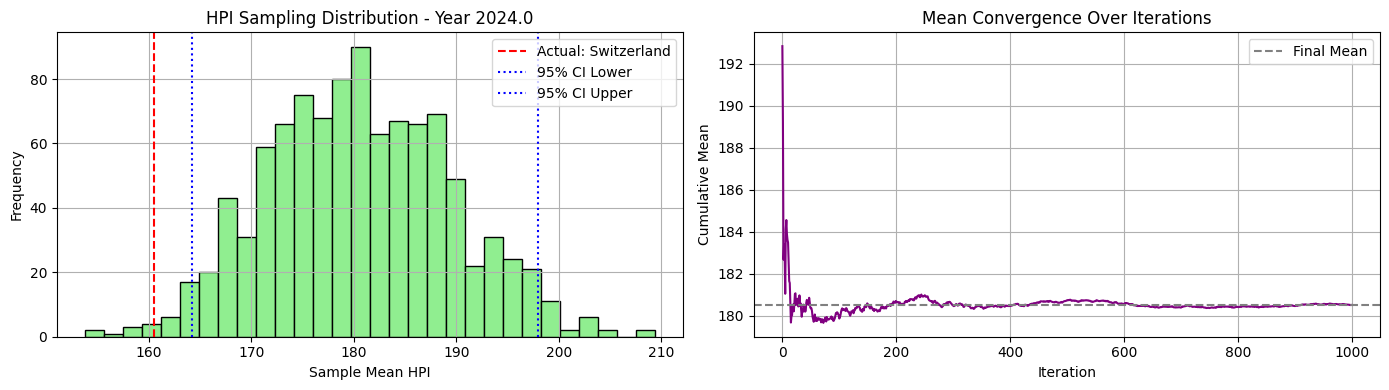

In [92]:
synthetic_c3_ni20_maxi500_02, excluded_c3_ni20_maxi500_02, actual_c3_ni20_maxi500_02 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c3_ni20_maxi500, cluster_id=2, seed=56)

### Compute metrics
* Compute MSE from synthetic data versus the real one from the country excluded
* Compute MAE from synthetic data versus the real one from the country excluded

In [68]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [69]:
from sklearn.metrics import silhouette_score

In [70]:
def compute_global_mse_mae(synthetic_dicts, actual_dicts):
    """
    Computes global MSE and MAE across multiple synthetic vs. actual HPI dictionaries.

    Parameters:
    - synthetic_dicts: list of dicts with synthetic HPI values per year
    - actual_dicts: list of dicts with actual HPI values per year

    Returns:
    - mse: Mean Squared Error
    - mae: Mean Absolute Error
    """

    y_true = []
    y_pred = []

    for synth, actual in zip(synthetic_dicts, actual_dicts):
        common_years = set(synth.keys()) & set(actual.keys())
        for year in common_years:
            s_val = synth[year]
            a_val = actual[year]
            if not (np.isnan(s_val) or np.isnan(a_val)):
                y_pred.append(s_val)
                y_true.append(a_val)

    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    return mse, mae

In [93]:
synthetic_list_c2_ni10_maxi100 = [synthetic_c2_ni10_maxi100_00, synthetic_c2_ni10_maxi100_01]
actual_list_c2_ni10_maxi100 = [actual_c2_ni10_maxi100_00, actual_c2_ni10_maxi100_01]
synthetic_list_c2_ni20_maxi500 = [synthetic_c2_ni20_maxi500_00, synthetic_c2_ni20_maxi500_01]
actual_list_c2_ni20_maxi500 = [actual_c2_ni20_maxi500_00, actual_c2_ni20_maxi500_01]
synthetic_list_c3_ni20_maxi500 = [synthetic_c3_ni20_maxi500_00, synthetic_c3_ni20_maxi500_01, synthetic_c3_ni20_maxi500_02]
actual_list_c3_ni20_maxi500 = [actual_c3_ni20_maxi500_00, actual_c3_ni20_maxi500_01, actual_c3_ni20_maxi500_02]

In [86]:
mse_c2_ni10_maxi100, mae_c2_ni10_maxi100 = compute_global_mse_mae(synthetic_list_c2_ni10_maxi100, actual_list_c2_ni10_maxi100)
print(f"Global MSE: {mse_c2_ni10_maxi100:.4f}")
print(f"Global MAE: {mae_c2_ni10_maxi100:.4f}")

Global MSE: 881.6041
Global MAE: 24.8488


In [87]:
score_c2_ni10_maxi100 = silhouette_score(cluster_input, ym_c2_ni10_maxi100.labels_, metric='euclidean')
print(f"Silhouette Score: {score_c2_ni10_maxi100:.4f}")

Silhouette Score: 0.3998


In [88]:
mse_c2_ni20_maxi500, mae_c2_ni20_maxi500 = compute_global_mse_mae(synthetic_list_c2_ni20_maxi500, actual_list_c2_ni20_maxi500)
print(f"Global MSE: {mse_c2_ni20_maxi500:.4f}")
print(f"Global MAE: {mae_c2_ni20_maxi500:.4f}")

Global MSE: 881.6041
Global MAE: 24.8488


In [89]:
score_c2_ni20_maxi500 = silhouette_score(cluster_input, ym_c2_ni20_maxi500.labels_, metric='euclidean')
print(f"Silhouette Score: {score_c2_ni20_maxi500:.4f}")

Silhouette Score: 0.3998


In [94]:
mse_c3_ni20_maxi500, mae_c3_ni20_maxi500 = compute_global_mse_mae(synthetic_list_c3_ni20_maxi500, actual_list_c3_ni20_maxi500)
print(f"Global MSE: {mse_c3_ni20_maxi500:.4f}")
print(f"Global MAE: {mae_c3_ni20_maxi500:.4f}")

Global MSE: 392.4662
Global MAE: 16.3107


In [95]:
score_c3_ni20_maxi500 = silhouette_score(cluster_input, ym_c3_ni20_maxi500.labels_, metric='euclidean')
print(f"Silhouette Score: {score_c3_ni20_maxi500:.4f}")

Silhouette Score: 0.3110


### Log performance of the experiment
* Import dataframe for the logs
* Define the hyperparameter for introduce the results
* Export the dataframe

In [96]:
from datetime import datetime

In [97]:
log_df = pd.read_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')

In [98]:
log_df

,experiment_name,experiment_date,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,transformations_sampling,outliers_handling_clustering,outliers_handling_sampling,sampling_method,mse_score,mae_score
0,baseline_kmeans_random,2025-09-07 18:52,KMeans,3,random,10.0,100.0,42,False,False,0,NaN,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,1280.833748,27.767857
1,baseline_continent_clusters,2025-09-07 22:44,continent based,4,None,NaN,NaN,42,None,None,0,NaN,None,"Winsorization, rounding",None,Winsorization,mean,1652.241439,27.672956
2,baseline_kmeans_plusplus,2025-09-09 20:56,KMeans,3,k-means++,10.0,100.0,42,False,False,0,NaN,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,1268.379506,25.588507
3,kmeans_plusplus_without_outliers,2025-09-10 16:20,KMeans,3,k-means++,10.0,100.0,42,False,False,0,NaN,"StandardScaler, log transformation, Winsorization","Winsorization, rounding",Winsorization,Winsorization,mean,566.926791,19.297330
4,kmeans_plusplus_elbow_silhouette_5,2025-09-10 19:38:00,KMeans,5,k-means++,10.0,100.0,42,False,False,0,0.230735,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,1889.093940,29.773409
5,kmeans_plusplus_c2_ni10_maxi100,2025-09-11 17:54,KMeans,2,k-means++,10.0,100.0,42,True,True,1,0.335868,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,253.672048,12.191757
6,kmeans_plusplus_c2_ni18_maxi300,2025-09-11 17:54,KMeans,2,k-means++,18.0,300.0,42,True,True,1,0.319750,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,208.801705,10.990371
7,kmeans_plusplus_c2_ni20_maxi500,2025-09-11 17:54,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.319750,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,208.801705,10.990371
8,kmeans_plusplus_c3_ni20_maxi500,2025-09-11 17:54,KMeans,3,k-means++,20.0,500.0,42,True,True,0,0.285543,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,1268.379506,25.588507


In [99]:
log_df.loc[len(log_df)] = {
    'experiment_name': 'kmeans_++_c2_ni10_maxi100_wo',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 2,
    'init_method': 'k-means++',
    'n_init': 10,
    'max_iter': 100,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': score_c2_ni10_maxi100,
    'transformations_clustering': 'StandardScaler, log transformation',
    'transformations_sampling': 'Winsorization, rounding',
    'outliers_handling_clustering': 'Winsorization',
    'outliers_handling_sampling': 'Winsorization',
    'sampling_method': 'mean',
    'mse_score': mse_c2_ni10_maxi100,
    'mae_score': mae_c2_ni10_maxi100
}

In [100]:
log_df.loc[len(log_df)] = {
    'experiment_name': 'kmeans_plusplus_c2_ni20_maxi500_wo',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 2,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': score_c2_ni20_maxi500,
    'transformations_clustering': 'StandardScaler, log transformation',
    'transformations_sampling': 'Winsorization, rounding',
    'outliers_handling_clustering': 'Winsorization',
    'outliers_handling_sampling': 'Winsorization',
    'sampling_method': 'mean',
    'mse_score': mse_c2_ni20_maxi500,
    'mae_score': mae_c2_ni20_maxi500
}

In [101]:
log_df.loc[len(log_df)] = {
    'experiment_name': 'kmeans_plusplus_c3_ni20_maxi500_wo',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 3,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': False,
    'silhouette_score': score_c3_ni20_maxi500,
    'transformations_clustering': 'StandardScaler, log transformation',
    'transformations_sampling': 'Winsorization, rounding',
    'outliers_handling_clustering': 'Winsorization',
    'outliers_handling_sampling': 'Winsorization',
    'sampling_method': 'mean',
    'mse_score': mse_c3_ni20_maxi500,
    'mae_score': mae_c3_ni20_maxi500
}

In [102]:
log_df

,experiment_name,experiment_date,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,transformations_sampling,outliers_handling_clustering,outliers_handling_sampling,sampling_method,mse_score,mae_score
0,baseline_kmeans_random,2025-09-07 18:52,KMeans,3,random,10.0,100.0,42,False,False,0,NaN,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,1280.833748,27.767857
1,baseline_continent_clusters,2025-09-07 22:44,continent based,4,None,NaN,NaN,42,None,None,0,NaN,None,"Winsorization, rounding",None,Winsorization,mean,1652.241439,27.672956
2,baseline_kmeans_plusplus,2025-09-09 20:56,KMeans,3,k-means++,10.0,100.0,42,False,False,0,NaN,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,1268.379506,25.588507
3,kmeans_plusplus_without_outliers,2025-09-10 16:20,KMeans,3,k-means++,10.0,100.0,42,False,False,0,NaN,"StandardScaler, log transformation, Winsorization","Winsorization, rounding",Winsorization,Winsorization,mean,566.926791,19.297330
4,kmeans_plusplus_elbow_silhouette_5,2025-09-10 19:38:00,KMeans,5,k-means++,10.0,100.0,42,False,False,0,0.230735,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,1889.093940,29.773409
5,kmeans_plusplus_c2_ni10_maxi100,2025-09-11 17:54,KMeans,2,k-means++,10.0,100.0,42,True,True,1,0.335868,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,253.672048,12.191757
6,kmeans_plusplus_c2_ni18_maxi300,2025-09-11 17:54,KMeans,2,k-means++,18.0,300.0,42,True,True,1,0.319750,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,208.801705,10.990371
7,kmeans_plusplus_c2_ni20_maxi500,2025-09-11 17:54,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.319750,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,208.801705,10.990371
8,kmeans_plusplus_c3_ni20_maxi500,2025-09-11 17:54,KMeans,3,k-means++,20.0,500.0,42,True,True,0,0.285543,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,1268.379506,25.588507
9,kmeans_++_c2_ni10_maxi100_wo,2025-09-11 19:48,KMeans,2,k-means++,10.0,100.0,42,True,True,1,0.399803,"StandardScaler, log transformation","Winsorization, rounding",Winsorization,Winsorization,mean,881.604066,24.848810


In [103]:
log_df.to_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')